# Proyecto final: Agente Inversor
## Fase 1. Análisis exploratorio de datos (EDA)

**Activo financiero:** Bitcoin frente al dólar estadounidense (BTC/USD)

**Fuente de datos:** Repositorio público de Gym Trading Env.

**Asignatura:** Simulación y Aprendizaje por Refuerzo MIA 2026-5

**Equipo:** Grupo de trabajo 4 — Agente Inversor

---

## Introducción

La toma de decisiones de inversión constituye un problema secuencial en el que es necesario decidir cuánto capital exponer a un activo, considerando la evolución de los precios, la incertidumbre del mercado y los costos asociados a las operaciones. En este contexto, el aprendizaje por refuerzo (*Reinforcement Learning*, RL) permite formular un agente que interactúa con un entorno, selecciona acciones y aprende a partir de las recompensas obtenidas.

El presente proyecto busca desarrollar un agente de aprendizaje por refuerzo capaz de decidir qué proporción del capital invertir en Bitcoin, utilizando información histórica del precio BTC/USD. El agente podrá seleccionar entre tres niveles de exposición: 0 %, 50 % y 100 % del capital disponible.

Antes de construir el entorno de simulación y entrenar el agente, es necesario realizar un análisis exploratorio de los datos. Esta etapa permite comprender las características del activo, identificar posibles problemas de calidad y estudiar patrones en los precios, los retornos y la volatilidad que puedan orientar la formulación del problema.

Los resultados del análisis también servirán para seleccionar las variables de observación del agente, establecer una separación temporal entre los datos de entrenamiento y evaluación y reducir el riesgo de utilizar información futura durante la toma de decisiones.

## Objetivos

### Objetivo general

Analizar y preparar los datos históricos de BTC/USD para fundamentar el diseño de un entorno de inversión basado en aprendizaje por refuerzo.

### Objetivos específicos

- Examinar la estructura, cobertura temporal, tipos de datos y calidad de la base.
- Analizar la evolución histórica del precio y la distribución de los retornos.
- Identificar períodos de mayor y menor volatilidad y posibles tendencias o caídas relevantes.
- Construir indicadores técnicos que puedan representar el estado observado por

### 1. Conectar y guardar la base

In [ ]:
# ============================================================
# 1. CONFIGURACIÓN Y CARGA DE DATOS
# Proyecto: Agente Inversor
# Fase: Análisis exploratorio de BTC/USD
# ============================================================

from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Semilla de reproducibilidad para los análisis que la requieran
SEMILLA = 42
np.random.seed(SEMILLA)

# Fuente pública del dataset
URL_DATA = (
    "https://raw.githubusercontent.com/ClementPerroud/"
    "Gym-Trading-Env/main/examples/data/BTC_USD-Hourly.csv"
)

# Carpeta de trabajo
CARPETA_PROYECTO = Path("/content/agente_inversor")
CARPETA_DATA = CARPETA_PROYECTO / "data"
CARPETA_DATA.mkdir(parents=True, exist_ok=True)

RUTA_CSV = CARPETA_DATA / "BTC_USD-Hourly.csv"

# Descargar solamente si el archivo no existe en esta sesión
if not RUTA_CSV.exists():
    df = pd.read_csv(URL_DATA)
    df.to_csv(RUTA_CSV, index=False)
    print("Base descargada y guardada correctamente.")
else:
    df = pd.read_csv(RUTA_CSV)
    print("Base cargada desde la copia local.")

print(f"\nRuta del archivo: {RUTA_CSV}")
print(f"Filas: {df.shape[0]:,}")
print(f"Columnas: {df.shape[1]}")

display(df.head())

Base descargada y guardada correctamente.

Ruta del archivo: /content/agente_inversor/data/BTC_USD-Hourly.csv
Filas: 33,259
Columnas: 9


,unix,date,symbol,open,high,low,close,volume,Volume USD
0,1646092800,2022-03-01 00:00:00,BTC/USD,43221.71,43626.49,43185.48,43312.27,52.056320,2.254677e+06
1,1646089200,2022-02-28 23:00:00,BTC/USD,43085.30,43364.81,42892.37,43178.98,106.816103,4.612210e+06
2,1646085600,2022-02-28 22:00:00,BTC/USD,41657.23,44256.08,41650.29,42907.32,527.540571,2.263535e+07
3,1646082000,2022-02-28 21:00:00,BTC/USD,41917.09,41917.09,41542.60,41659.53,69.751680,2.905822e+06
4,1646078400,2022-02-28 20:00:00,BTC/USD,41361.99,41971.00,41284.11,41914.97,247.151654,1.035935e+07


### Resultados de la carga de datos

La base de datos se cargó correctamente desde el repositorio público de Gym Trading Env y se guardó una copia local para facilitar su utilización durante el análisis exploratorio.

El conjunto de datos contiene **33.259 registros y 9 columnas**, correspondientes a información histórica del mercado BTC/USD. Entre las variables disponibles se encuentran la fecha (`date`), el símbolo del activo (`symbol`), los precios de apertura (`open`), máximo (`high`), mínimo (`low`) y cierre (`close`), así como el volumen negociado y su valor expresado en dólares.

La estructura de la base permite estudiar la evolución del precio de Bitcoin, calcular retornos y construir indicadores técnicos para la posterior formulación del agente de aprendizaje por refuerzo.

### 2. Inspección de la estructura

In [ ]:
# ============================================================
# 2. INSPECCIÓN INICIAL DE LA BASE
# ============================================================

print("Columnas disponibles:")
print(df.columns.tolist())

print("\nInformación general:")
df.info()

print("\nTipos de datos:")
display(df.dtypes.to_frame(name="Tipo de dato"))

print("\nValores faltantes:")
display(
    df.isnull()
      .sum()
      .to_frame(name="Cantidad de faltantes")
)

print("\nEstadísticas descriptivas:")
display(df.describe(include="all").T)

Columnas disponibles:
['unix', 'date', 'symbol', 'open', 'high', 'low', 'close', 'volume', 'Volume USD']

Información general:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 33259 entries, 0 to 33258
Data columns (total 9 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   unix        33259 non-null  int64  
 1   date        33259 non-null  object 
 2   symbol      33259 non-null  object 
 3   open        33259 non-null  float64
 4   high        33259 non-null  float64
 5   low         33259 non-null  float64
 6   close       33259 non-null  float64
 7   volume      33259 non-null  float64
 8   Volume USD  33259 non-null  float64
dtypes: float64(6), int64(1), object(2)
memory usage: 2.3+ MB

Tipos de datos:


,Tipo de dato
unix,int64
date,object
symbol,object
open,float64
high,float64
low,float64
close,float64
volume,float64
Volume USD,float64



Valores faltantes:


,Cantidad de faltantes
unix,0
date,0
symbol,0
open,0
high,0
low,0
close,0
volume,0
Volume USD,0



Estadísticas descriptivas:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
unix,33259.0,NaN,NaN,NaN,1586228400.0,34564286.296696,1526364000.0,1556296200.0,1586228400.0,1616160600.0,1646092800.0
date,33259,33259,2018-05-15 06:00:00,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
symbol,33259,1,BTC/USD,33259,NaN,NaN,NaN,NaN,NaN,NaN,NaN
open,33259.0,NaN,NaN,NaN,20119.546772,18537.219607,3139.76,7022.865,9700.04,36415.305,68635.05
high,33259.0,NaN,NaN,NaN,20232.957473,18646.950933,3158.34,7055.835,9740.27,36735.38,69000.0
low,33259.0,NaN,NaN,NaN,19997.069777,18418.320297,3122.28,6970.57,9657.0,36104.235,68447.0
close,33259.0,NaN,NaN,NaN,20120.6848,18537.695044,3139.76,7022.865,9700.32,36423.04,68627.01
volume,33259.0,NaN,NaN,NaN,1612380.146335,3102327.676408,0.0,190.324133,609327.06,1929239.915,68570613.16
Volume USD,33259.0,NaN,NaN,NaN,2965701.403312,7329786.903391,0.0,168.28,524.83,3120014.4439,258232381.746773


### Análisis de la estructura y calidad de los datos

La inspección inicial permitió identificar nueve variables y revisar sus tipos de datos. La columna `date` se encuentra inicialmente en formato de texto, mientras que las variables de precios y volumen están representadas mediante tipos numéricos. La columna `symbol` identifica el activo financiero analizado.

En la revisión de valores faltantes, las columnas no presentan registros nulos según los resultados obtenidos. Sin embargo, las estadísticas descriptivas muestran valores `NaN` en algunas variables de precio y volumen, lo que indica que es necesario revisar la presencia de valores no finitos y verificar la consistencia de los registros antes de continuar.

La columna `units` también aparece en el conjunto de datos. Su significado debe verificarse en la documentación de la fuente antes de decidir si se utiliza en el análisis o se excluye del modelo.

Esta revisión inicial permite establecer que la base requiere una validación adicional de sus variables numéricas y de la integridad de las observaciones antes de calcular los indicadores financieros.

### 3. Validación temporal

In [ ]:
# ============================================================
# 3. VALIDACIÓN DE FECHAS Y ORDEN CRONOLÓGICO
# ============================================================

posibles_fechas = ["date", "datetime", "timestamp", "time"]
col_fecha = next(
    (col for col in df.columns
     if col.lower() in posibles_fechas),
    None
)

if col_fecha is None:
    raise ValueError(
        "No se identificó la columna temporal. "
        "Revisa df.columns.tolist() y ajusta col_fecha."
    )

df[col_fecha] = pd.to_datetime(
    df[col_fecha],
    errors="coerce",
    utc=True
)

fechas_invalidas = df[col_fecha].isna().sum()

print("Fechas inválidas:", fechas_invalidas)

df = df.dropna(subset=[col_fecha]).copy()
df = df.sort_values(col_fecha).reset_index(drop=True)

print("Primera observación:", df[col_fecha].min())
print("Última observación:", df[col_fecha].max())
print("Filas duplicadas completas:", df.duplicated().sum())

display(df.head())
display(df.tail())

Fechas inválidas: 0
Primera observación: 2018-05-15 06:00:00+00:00
Última observación: 2022-03-01 00:00:00+00:00
Filas duplicadas completas: 0


,unix,date,symbol,open,high,low,close,volume,Volume USD
0,1526364000,2018-05-15 06:00:00+00:00,BTC/USD,8733.86,8796.68,8707.28,8740.99,4906603.14,559.93
1,1526367600,2018-05-15 07:00:00+00:00,BTC/USD,8740.99,8766.00,8721.11,8739.00,2390398.89,273.58
2,1526371200,2018-05-15 08:00:00+00:00,BTC/USD,8739.00,8750.27,8660.53,8728.49,7986062.84,917.79
3,1526374800,2018-05-15 09:00:00+00:00,BTC/USD,8728.49,8754.40,8701.35,8708.32,1593991.98,182.62
4,1526378400,2018-05-15 10:00:00+00:00,BTC/USD,8708.32,8865.00,8695.11,8795.90,11101273.74,1260.69


,unix,date,symbol,open,high,low,close,volume,Volume USD
33254,1646078400,2022-02-28 20:00:00+00:00,BTC/USD,41361.99,41971.00,41284.11,41914.97,247.151654,1.035935e+07
33255,1646082000,2022-02-28 21:00:00+00:00,BTC/USD,41917.09,41917.09,41542.60,41659.53,69.751680,2.905822e+06
33256,1646085600,2022-02-28 22:00:00+00:00,BTC/USD,41657.23,44256.08,41650.29,42907.32,527.540571,2.263535e+07
33257,1646089200,2022-02-28 23:00:00+00:00,BTC/USD,43085.30,43364.81,42892.37,43178.98,106.816103,4.612210e+06
33258,1646092800,2022-03-01 00:00:00+00:00,BTC/USD,43221.71,43626.49,43185.48,43312.27,52.056320,2.254677e+06


### Validación y ordenamiento temporal

La variable `date` se convirtió al formato de fecha y hora, y los registros se ordenaron cronológicamente para facilitar el análisis de la serie temporal.

### Periodo de análisis

El conjunto de datos contiene 33.259 observaciones horarias del par BTC/USD, comprendidas entre el 15 de mayo de 2018 a las 06:00 UTC y el 1 de marzo de 2022 a las 00:00 UTC. La información incluye variables de mercado como los precios de apertura, máximo, mínimo y cierre, además del volumen de negociación.

Este periodo permite estudiar diferentes condiciones del mercado, incluyendo tendencias alcistas y bajistas, cambios en la volatilidad y movimientos extremos del precio.

El ordenamiento cronológico es fundamental para el proyecto, ya que las decisiones de inversión deben basarse únicamente en información disponible en el momento de actuar. Por esta razón, la división posterior entre entrenamiento y evaluación se realizará respetando el orden temporal, sin mezclar aleatoriamente las observaciones.

Finalmente, se verificó que no existieran registros duplicados en la variable temporal y que los intervalos entre observaciones consecutivas fueran regulares, con una frecuencia de una hora.

## 4. Revisión inicial de precios

In [ ]:
# ============================================================
# 4. VALIDACIÓN DE LAS VARIABLES DE PRECIO
# ============================================================

columnas_lower = {col.lower(): col for col in df.columns}

if "close" not in columnas_lower:
    raise ValueError(
        "No se encontró la columna 'close'. "
        "Revisa las columnas disponibles."
    )

col_close = columnas_lower["close"]

df[col_close] = pd.to_numeric(
    df[col_close],
    errors="coerce"
)

print("Valores de cierre faltantes:", df[col_close].isna().sum())
print("Precios de cierre menores o iguales a cero:",
      (df[col_close] <= 0).sum())

display(df[[col_fecha, col_close]].head())
display(df[col_close].describe())

Valores de cierre faltantes: 0
Precios de cierre menores o iguales a cero: 0


,date,close
0,2018-05-15 06:00:00+00:00,8740.99
1,2018-05-15 07:00:00+00:00,8739.00
2,2018-05-15 08:00:00+00:00,8728.49
3,2018-05-15 09:00:00+00:00,8708.32
4,2018-05-15 10:00:00+00:00,8795.90


,close
count,33259.000000
mean,20120.684800
std,18537.695044
min,3139.760000
25%,7022.865000
50%,9700.320000
75%,36423.040000
max,68627.010000


### Revisión preliminar del precio de cierre

La variable `close` corresponde al precio de cierre de Bitcoin frente al dólar estadounidense (BTC/USD) y constituye una variable fundamental para el análisis de la evolución del activo y el cálculo de sus retornos.

La revisión de calidad confirmó que la columna contiene **33.259 observaciones numéricas**, sin valores no numéricos ni precios menores o iguales a cero. Por tanto, los datos de cierre cumplen estos criterios básicos de validez y pueden utilizarse para continuar con el análisis exploratorio.

Las estadísticas descriptivas muestran un precio promedio de **20.120,68 USD**, una mediana de **9.700,32 USD** y una desviación estándar de **18.537,70 USD**. El precio mínimo registrado es de **3.139,76 USD**, mientras que el máximo alcanza **68.627,01 USD**.

La diferencia entre la media y la mediana, junto con la amplitud de los precios observados, evidencia una variación considerable del valor del activo durante el período analizado. Estos resultados justifican profundizar en la evolución temporal del precio, la distribución de los retornos y los períodos de volatilidad.

Es importante señalar que estas estadísticas describen el comportamiento histórico de los precios, pero no permiten concluir por sí solas que exista una estrategia de inversión rentable. Para ello será necesario evaluar el agente y compararlo con estrategias de referencia en datos que no hayan sido utilizados durante el entrenamiento.

## 5. Evolución histórica del precio BTC/USD

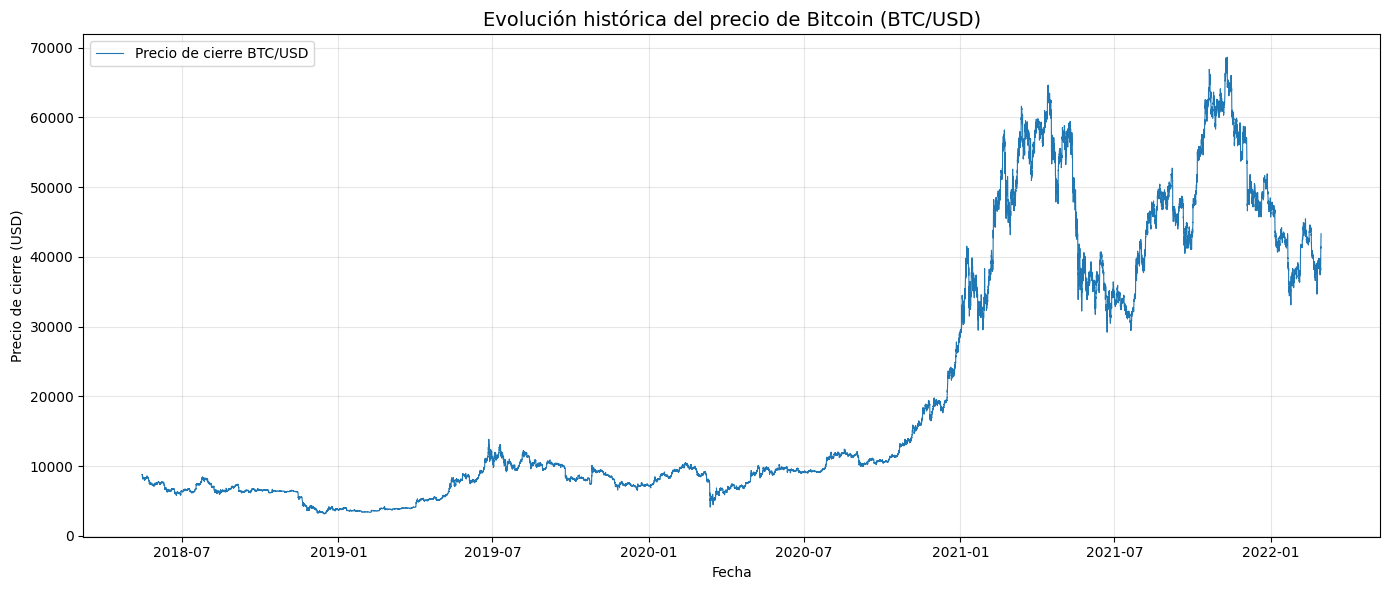

In [ ]:
# ============================================================
# 5. EVOLUCIÓN HISTÓRICA DEL PRECIO BTC/USD
# ============================================================

plt.figure(figsize=(14, 6))

plt.plot(
    df[col_fecha],
    df["close"],
    linewidth=0.8,
    label="Precio de cierre BTC/USD"
)

plt.title(
    "Evolución histórica del precio de Bitcoin (BTC/USD)",
    fontsize=14
)
plt.xlabel("Fecha")
plt.ylabel("Precio de cierre (USD)")
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

### 5.1. Análisis de la evolución histórica del precio

La gráfica presenta la evolución del precio de cierre de Bitcoin frente al dólar estadounidense (BTC/USD) entre abril de 2018 y febrero de 2022. Se observa un comportamiento variable, con períodos de relativa estabilidad, tendencias alcistas y episodios de caídas pronunciadas.

Durante 2018 y 2019, el precio se mantuvo en niveles considerablemente inferiores a los observados posteriormente, con fluctuaciones y períodos de recuperación. En 2020 se aprecia una recuperación progresiva, aunque también se presenta una caída pronunciada durante el primer semestre del año.

A partir de finales de 2020 se evidencia un incremento significativo del precio, que continúa durante 2021 y alcanza sus niveles máximos hacia finales de ese año. Posteriormente, el activo presenta una corrección importante y una mayor variabilidad de los precios hasta el final del período observado.

Este comportamiento muestra que la serie no evoluciona de manera uniforme: existen diferentes condiciones de mercado, con variaciones en la tendencia y en la magnitud de los movimientos. Por ello, utilizar únicamente el precio de cierre podría resultar insuficiente para representar las condiciones del mercado que enfrenta el agente.

En consecuencia, se considera pertinente analizar los retornos y la volatilidad, e incorporar indicadores técnicos que permitan describir los movimientos recientes del precio. Estas variables podrán utilizarse para construir el estado del agente de Reinforcement Learning.

Finalmente, la gráfica representa exclusivamente el comportamiento histórico del activo y no demuestra por sí sola que sea posible anticipar sus movimientos futuros ni obtener rentabilidades positivas de manera consistente.

### 6. Cálculo y análisis de entornos

In [ ]:
# ============================================================
# 6. CÁLCULO Y ANÁLISIS DE RETORNOS
# ============================================================

# Retorno porcentual entre observaciones consecutivas
df["return"] = df["close"].pct_change()

# Retorno logarítmico
df["log_return"] = np.log(
    df["close"] / df["close"].shift(1)
)

print("Estadísticas descriptivas de los retornos:")
display(df[["return", "log_return"]].describe())

print("\nValores faltantes en los retornos:")
display(df[["return", "log_return"]].isna().sum())

Estadísticas descriptivas de los retornos:


,return,log_return
count,33258.000000,33258.000000
mean,0.000081,0.000048
std,0.008159,0.008159
min,-0.165484,-0.180903
25%,-0.002704,-0.002707
50%,0.000079,0.000079
75%,0.002911,0.002906
max,0.228118,0.205483



Valores faltantes en los retornos:


,0
return,1
log_return,1


### 6.1. Análisis descriptivo de los retornos

Los retornos se calcularon a partir de la variación porcentual del precio de cierre entre observaciones consecutivas. También se calcularon los retornos logarítmicos como una medida alternativa para caracterizar los cambios relativos del precio.

Se obtuvieron 33.258 observaciones válidas para ambas variables. El retorno porcentual promedio es de aproximadamente 0,0081 % por observación, mientras que la mediana es cercana a 0,0079 %. Estos valores indican que el retorno promedio y el retorno mediano del período analizado fueron ligeramente positivos, aunque esto no implica que todas las observaciones hayan presentado ganancias.

La desviación estándar de los retornos porcentuales es de aproximadamente 0,8159 puntos porcentuales, lo que refleja una variabilidad considerable en los cambios horarios del precio. Asimismo, los retornos presentan valores extremos: el mínimo observado es de aproximadamente −16,55 % y el máximo de 22,81 %.

La diferencia entre los valores extremos y los percentiles centrales evidencia que, aunque muchas variaciones se concentran cerca de cero, también existen movimientos pronunciados que pueden afectar significativamente el valor de una inversión.

Estos resultados justifican incorporar medidas de volatilidad en el estado del agente y considerar el riesgo al evaluar las estrategias de inversión. También muestran por qué el retorno acumulado no debe ser la única medida utilizada para determinar el desempeño del agente.

Se observa un valor faltante en ambas series de retornos, correspondiente a la primera observación, debido a que no existe un precio anterior con el cual calcular la variación. Este comportamiento es esperado al utilizar la función `pct_change()` y los retornos logarítmicos.

### 7. Visualización de los retornos

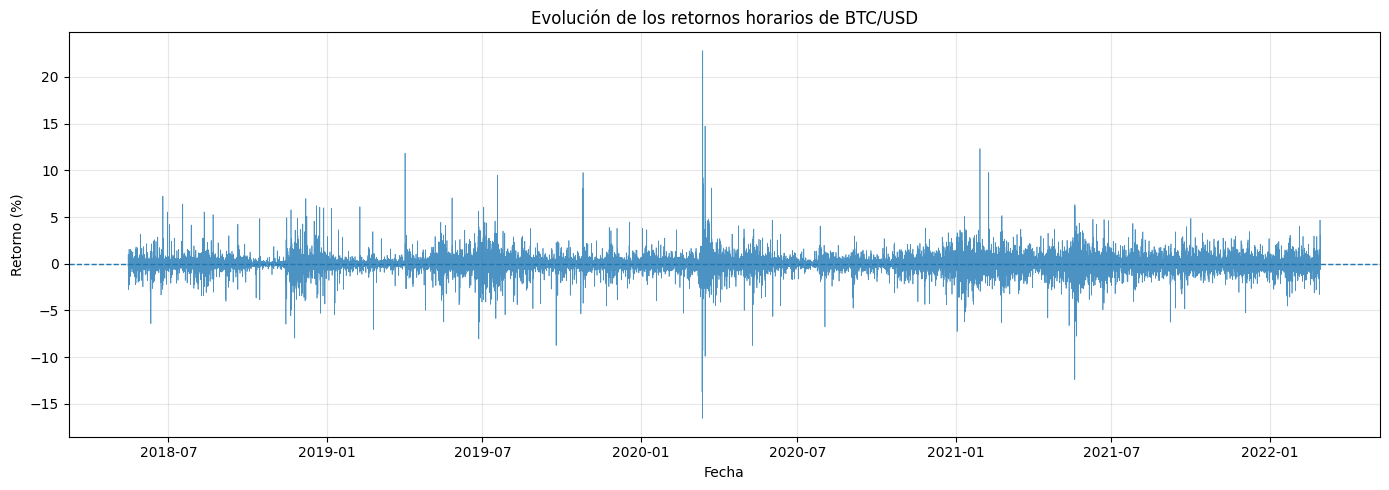

In [ ]:
# ============================================================
# 7. VISUALIZACIÓN DE LOS RETORNOS
# ============================================================

plt.figure(figsize=(14, 5))

plt.plot(
    df[col_fecha],
    df["return"] * 100,
    linewidth=0.5,
    alpha=0.8
)

plt.axhline(0, linewidth=1, linestyle="--")

plt.title("Evolución de los retornos horarios de BTC/USD")
plt.xlabel("Fecha")
plt.ylabel("Retorno (%)")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### 7.1. Comportamiento temporal de los retornos

El gráfico muestra la evolución de los retornos horarios de BTC/USD durante el período analizado. La mayoría de las variaciones se concentra alrededor de cero, alternando movimientos positivos y negativos. Sin embargo, también se observan episodios con fluctuaciones de mayor magnitud.

Destaca la presencia de movimientos extremos durante algunos períodos, particularmente alrededor de marzo de 2020, cuando se presentan variaciones positivas y negativas pronunciadas. También se identifican intervalos con una mayor concentración de fluctuaciones, lo que sugiere que la variabilidad de los retornos no permanece constante a lo largo del tiempo.

Este comportamiento es compatible con la presencia de agrupamientos de volatilidad, en los que períodos relativamente tranquilos alternan con períodos de mayor incertidumbre. No obstante, esta observación visual deberá complementarse con medidas cuantitativas.

Desde la perspectiva del aprendizaje por refuerzo, estos resultados son relevantes porque una misma exposición al activo puede producir resultados muy diferentes según las condiciones del mercado. Por ello, se analizará la volatilidad mediante ventanas móviles y se evaluará una función de recompensa alternativa que considere el riesgo, además del retorno neto de los costos de transacción.

### 8. Análisis de volatilidad móvil

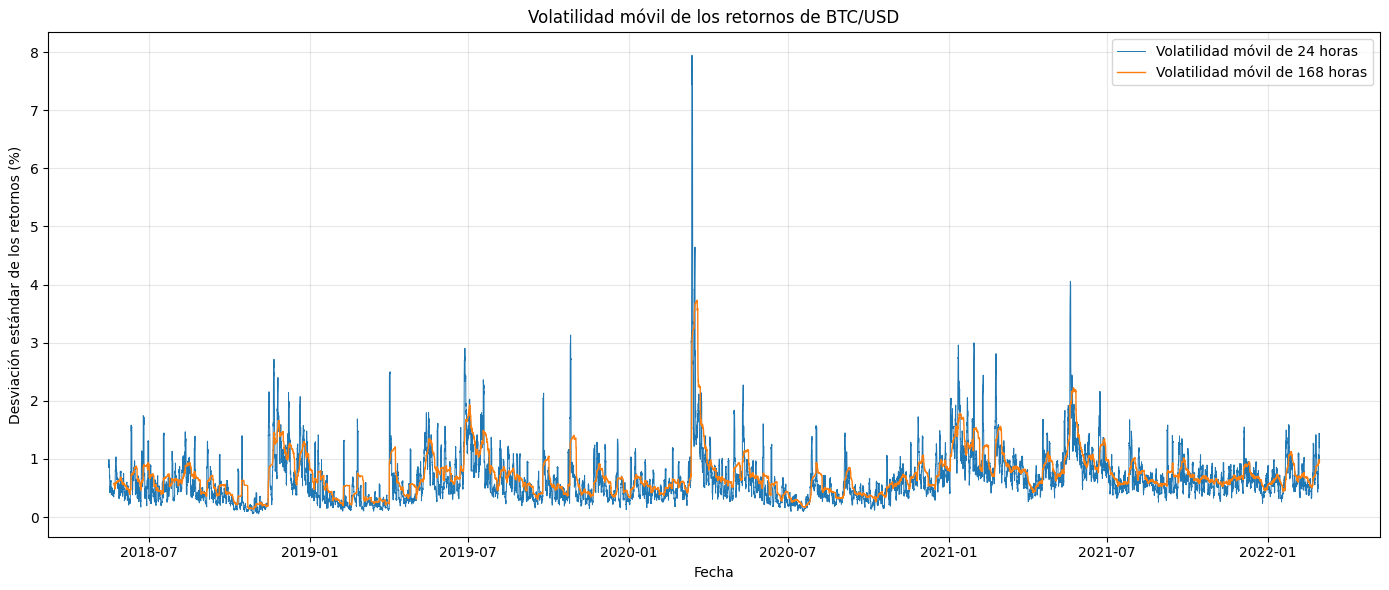

In [ ]:
# ============================================================
# 8. ANÁLISIS DE VOLATILIDAD MÓVIL
# ============================================================

# Desviación estándar de los retornos horarios
df["volatility_24h"] = df["return"].rolling(
    window=24,
    min_periods=24
).std()

df["volatility_168h"] = df["return"].rolling(
    window=168,
    min_periods=168
).std()

plt.figure(figsize=(14, 6))

plt.plot(
    df[col_fecha],
    df["volatility_24h"] * 100,
    linewidth=0.7,
    label="Volatilidad móvil de 24 horas"
)

plt.plot(
    df[col_fecha],
    df["volatility_168h"] * 100,
    linewidth=1.0,
    label="Volatilidad móvil de 168 horas"
)

plt.title("Volatilidad móvil de los retornos de BTC/USD")
plt.xlabel("Fecha")
plt.ylabel("Desviación estándar de los retornos (%)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:
# Estadísticas descriptivas de la volatilidad
display(
    df[["volatility_24h", "volatility_168h"]]
    .describe()
    .T
)

,count,mean,std,min,25%,50%,75%,max
volatility_24h,33235.0,0.006702,0.004669,0.000570,0.003819,0.005702,0.008148,0.079441
volatility_168h,33091.0,0.007216,0.003806,0.001392,0.005070,0.006534,0.008401,0.037278


### 8.1. Análisis descriptivo de la volatilidad

Para estudiar la variabilidad de los retornos de BTC/USD se calcularon dos medidas de volatilidad móvil: una ventana de 24 observaciones, que representa aproximadamente un día, y una ventana de 168 observaciones, equivalente a una semana, considerando la frecuencia horaria de los datos.

La volatilidad móvil de 24 horas presenta una media de 0,006702 y una desviación estándar de 0,004669. Por su parte, la volatilidad móvil de 168 horas tiene una media de 0,007216 y una desviación estándar de 0,003806. Estos valores están expresados en unidades decimales, por lo que corresponden aproximadamente a 0,6702 % y 0,7216 %, respectivamente.

La volatilidad de 24 horas alcanza un máximo de 0,079441, equivalente a aproximadamente 7,94 %, mientras que la volatilidad semanal alcanza un máximo de 0,037278, equivalente a 3,73 %. La diferencia entre ambos máximos indica que la ventana más corta responde con mayor intensidad a episodios puntuales de movimientos extremos.

Asimismo, la volatilidad semanal presenta una evolución más suavizada, ya que incorpora un período más amplio de retornos. Esta característica permite distinguir entre fluctuaciones de corto plazo y condiciones de mercado que persisten durante varios días.

En conjunto, los resultados muestran que la variabilidad de los retornos no es constante. Por ello, la volatilidad móvil puede aportar información relevante para representar el estado del mercado y estudiar el comportamiento del agente ante diferentes niveles de incertidumbre.

### 8.2. Comportamiento temporal de la volatilidad

La gráfica muestra que la volatilidad de BTC/USD varía considerablemente durante el período estudiado. La serie de 24 horas presenta fluctuaciones más abruptas, mientras que la serie de 168 horas evoluciona de manera más gradual debido a que considera una ventana de observación más amplia.

Se identifican episodios destacados de volatilidad alrededor de finales de 2018 y comienzos de 2019, a mediados de 2019, durante marzo de 2020 y en distintos momentos de 2021. El pico más pronunciado de la serie de corto plazo aparece alrededor de marzo de 2020, lo que coincide con un período de movimientos extremos observado previamente en el gráfico de retornos.

También se observan períodos en los que ambas medidas disminuyen y se mantienen en niveles relativamente bajos. La alternancia entre intervalos tranquilos y episodios de alta variabilidad evidencia que las condiciones del mercado cambian a lo largo del tiempo.

Este comportamiento es relevante para el proyecto porque una estrategia con una exposición elevada puede experimentar resultados diferentes según el nivel de volatilidad presente. En consecuencia, se considerará la volatilidad reciente como una variable candidata para el estado del agente de Reinforcement Learning.

Sin embargo, incorporar esta variable no garantiza que el agente gestione adecuadamente el riesgo. Su utilidad deberá evaluarse mediante experimentos y comparaciones en datos no utilizados durante el entrenamiento.

### 9. Construcciín de indicadores técnicos

In [ ]:
# ============================================================
# 9. CONSTRUCCIÓN DE INDICADORES TÉCNICOS
# ============================================================

# Retorno acumulado de las últimas 24 horas
df["return_24h"] = df["close"].pct_change(24)

# Media móvil del precio de cierre de las últimas 24 horas
df["sma_24h"] = df["close"].rolling(
    window=24,
    min_periods=24
).mean()

# Diferencia relativa entre el precio y su media móvil
df["price_vs_sma_24h"] = (
    df["close"] / df["sma_24h"]
) - 1

# Volatilidad móvil de los retornos de 24 horas
# Ya fue calculada en la sección anterior como volatility_24h

columnas_indicadores = [
    "return_24h",
    "price_vs_sma_24h",
    "volatility_24h"
]

print("Estadísticas de los indicadores:")
display(df[columnas_indicadores].describe().T)

print("\nValores faltantes por indicador:")
display(df[columnas_indicadores].isna().sum())

Estadísticas de los indicadores:


,count,mean,std,min,25%,50%,75%,max
return_24h,33235.0,0.001862,0.038611,-0.46720,-0.014879,0.001269,0.018779,0.356513
price_vs_sma_24h,33236.0,0.000655,0.021426,-0.35019,-0.007536,0.000628,0.009377,0.250508
volatility_24h,33235.0,0.006702,0.004669,0.00057,0.003819,0.005702,0.008148,0.079441



Valores faltantes por indicador:


,0
return_24h,24
price_vs_sma_24h,23
volatility_24h,24


### 10. Visualización de indicarores

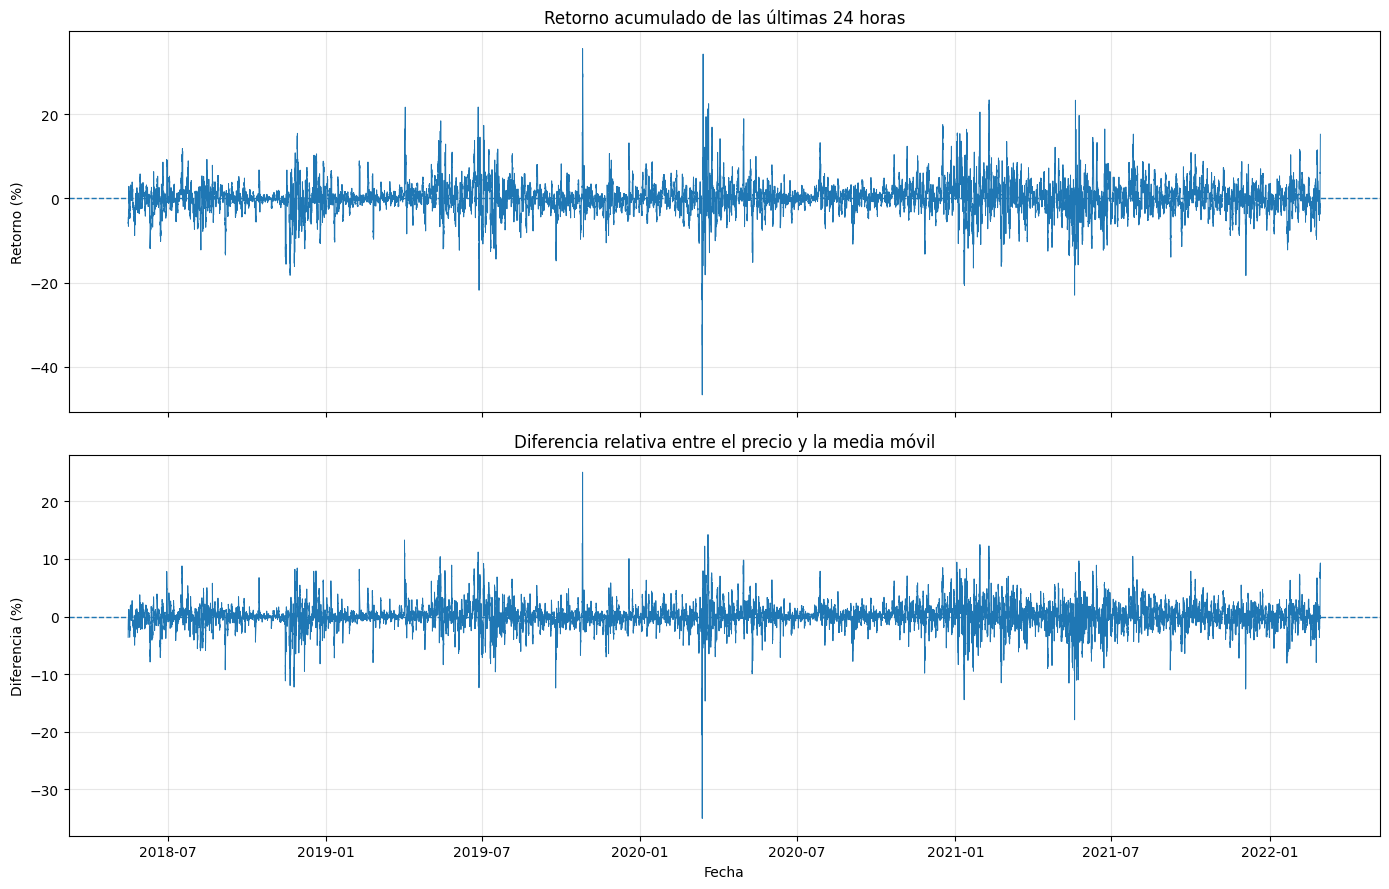

In [ ]:
# ============================================================
# 10. VISUALIZACIÓN DE INDICADORES
# ============================================================

fig, axes = plt.subplots(2, 1, figsize=(14, 9), sharex=True)

axes[0].plot(
    df[col_fecha],
    df["return_24h"] * 100,
    linewidth=0.7
)
axes[0].axhline(0, linestyle="--", linewidth=1)
axes[0].set_title("Retorno acumulado de las últimas 24 horas")
axes[0].set_ylabel("Retorno (%)")
axes[0].grid(alpha=0.3)

axes[1].plot(
    df[col_fecha],
    df["price_vs_sma_24h"] * 100,
    linewidth=0.7
)
axes[1].axhline(0, linestyle="--", linewidth=1)
axes[1].set_title("Diferencia relativa entre el precio y la media móvil")
axes[1].set_ylabel("Diferencia (%)")
axes[1].set_xlabel("Fecha")
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

### 10.1. Análisis de los indicadores técnicos

Se analizaron dos indicadores derivados del precio de cierre de BTC/USD: el retorno acumulado de las últimas 24 horas y la diferencia relativa entre el precio actual y su media móvil de 24 observaciones. También se incorporó la volatilidad móvil de 24 horas, calculada previamente.

El retorno de las últimas 24 horas presenta fluctuaciones alrededor de cero, con movimientos positivos y negativos de diferente magnitud. Se observan episodios en los que las variaciones son considerablemente más pronunciadas, lo que refleja que el comportamiento del activo cambia a lo largo del período analizado.

Por su parte, la diferencia relativa entre el precio y su media móvil permite observar si el precio se encuentra por encima o por debajo de su nivel promedio reciente. Los valores positivos indican que el precio está por encima de la media móvil, mientras que los negativos indican que está por debajo. Las desviaciones más pronunciadas reflejan diferencias importantes respecto al comportamiento reciente del precio.

Ambos indicadores presentan movimientos extremos en determinados momentos, lo que resulta coherente con la variabilidad identificada en los retornos y la volatilidad. Sin embargo, estos indicadores son descriptivos y no deben interpretarse como señales que garanticen futuras subidas o bajadas del precio.

En conjunto, los resultados respaldan la selección preliminar de variables que representen el rendimiento reciente, la tendencia de corto plazo y la volatilidad. Estas variables podrán proporcionar información complementaria para describir las condiciones del mercado al formular el estado del agente de aprendizaje por refuerzo.

### 10.2. Estadísticas descriptivas de los indicadores

El retorno acumulado de las últimas 24 horas presenta una media de 0,001862 en unidades decimales, equivalente aproximadamente a 0,1862 %, y una desviación estándar de 0,038611, equivalente a 3,8611 %. Sus valores oscilan entre −46,72 % y 35,65 %, lo que evidencia la presencia de variaciones importantes en algunos intervalos.

La diferencia relativa entre el precio y la media móvil presenta una media de 0,000655, equivalente a 0,0655 %, y una desviación estándar de 0,021426, equivalente a 2,1426 %. Su rango se encuentra entre −35,02 % y 25,05 %, mostrando que el precio puede alejarse considerablemente de su promedio reciente.

Por su parte, la volatilidad móvil de 24 horas presenta una media de 0,006702, equivalente a 0,6702 %, y un máximo de 0,079441, equivalente a 7,9441 %.

Estas medidas permiten caracterizar diferentes aspectos del mercado: el retorno representa el cambio del precio durante un intervalo, la diferencia respecto a la media móvil describe su posición relativa y la volatilidad mide la dispersión reciente de los retornos horarios.

Los valores extremos justifican revisar la calidad de los registros y verificar que los indicadores estén correctamente calculados. En particular, las variaciones acumuladas de 24 horas no deben confundirse con retornos de una sola hora, ya que corresponden a períodos diferentes.

#### 11. Validación de calidad de los indicadores

In [ ]:
# ============================================================
# 11. VALIDACIÓN DE CALIDAD DE LOS INDICADORES
# ============================================================

indicadores = [
    "return_24h",
    "price_vs_sma_24h",
    "volatility_24h"
]

print("Valores faltantes por indicador:")
display(df[indicadores].isna().sum())

print("\nPrimeras observaciones con indicadores faltantes:")
display(
    df.loc[
        df[indicadores].isna().any(axis=1),
        [col_fecha, "close"] + indicadores
    ].head(35)
)

print("\nIntervalos temporales entre observaciones:")
print(df[col_fecha].diff().value_counts().head(10))

print("\nRegistros duplicados por fecha:")
print(df[col_fecha].duplicated().sum())

print("\nRetornos de 24 horas más extremos:")
display(
    df.loc[
        df["return_24h"].abs().nlargest(10).index,
        [col_fecha, "close", "return_24h"]
    ].sort_values("return_24h")
)

Valores faltantes por indicador:


,0
return_24h,24
price_vs_sma_24h,23
volatility_24h,24



Primeras observaciones con indicadores faltantes:


,date,close,return_24h,price_vs_sma_24h,volatility_24h
0,2018-05-15 06:00:00+00:00,8740.99,NaN,NaN,NaN
1,2018-05-15 07:00:00+00:00,8739.00,NaN,NaN,NaN
2,2018-05-15 08:00:00+00:00,8728.49,NaN,NaN,NaN
3,2018-05-15 09:00:00+00:00,8708.32,NaN,NaN,NaN
4,2018-05-15 10:00:00+00:00,8795.90,NaN,NaN,NaN
5,2018-05-15 11:00:00+00:00,8760.00,NaN,NaN,NaN
6,2018-05-15 12:00:00+00:00,8760.00,NaN,NaN,NaN
7,2018-05-15 13:00:00+00:00,8759.23,NaN,NaN,NaN
8,2018-05-15 14:00:00+00:00,8517.77,NaN,NaN,NaN
9,2018-05-15 15:00:00+00:00,8520.30,NaN,NaN,NaN



Intervalos temporales entre observaciones:
date
0 days 01:00:00    33258
Name: count, dtype: int64

Registros duplicados por fecha:
0

Retornos de 24 horas más extremos:


,date,close,return_24h
16027,2020-03-13 01:00:00+00:00,4111.78,-0.467200
16026,2020-03-13 00:00:00+00:00,4671.37,-0.410631
16025,2020-03-12 23:00:00+00:00,4841.67,-0.389801
16030,2020-03-13 04:00:00+00:00,4865.87,-0.361074
16031,2020-03-13 05:00:00+00:00,4980.05,-0.349107
16028,2020-03-13 02:00:00+00:00,5049.75,-0.338934
16032,2020-03-13 06:00:00+00:00,5246.04,-0.300005
12692,2019-10-26 02:00:00+00:00,9682.62,0.300269
16051,2020-03-14 01:00:00+00:00,5524.63,0.343610
12691,2019-10-26 01:00:00+00:00,10110.42,0.356513


### 11.1. Validación de la calidad temporal y de los indicadores

La validación temporal confirmó que el conjunto de datos contiene 33.259 observaciones ordenadas cronológicamente, con intervalos consecutivos de una hora y sin fechas duplicadas. Esta regularidad permite analizar la serie como una secuencia de observaciones horarias.

Los valores faltantes identificados en los indicadores se concentran al inicio de la serie y se explican por la necesidad de disponer de observaciones anteriores para efectuar los cálculos. El retorno acumulado de 24 horas y la volatilidad móvil requieren una ventana histórica previa, mientras que la media móvil comienza a estar disponible cuando se completa su ventana de cálculo.

Por esta razón, estos valores faltantes iniciales no se interpretan como errores de captura. Se tratarán mediante la exclusión de las observaciones que no cuenten con todos los indicadores requeridos, sin utilizar interpolaciones basadas en información futura.

Adicionalmente, se identificaron variaciones extremas en los retornos acumulados de 24 horas, especialmente alrededor del 12 y 13 de marzo de 2020. Estos movimientos requieren una revisión puntual para comprobar la consistencia de los precios y los cálculos. No se eliminarán automáticamente, dado que los movimientos extremos pueden formar parte del comportamiento real del mercado.

En consecuencia, el conjunto de datos presenta una estructura temporal adecuada para continuar el análisis, aunque la revisión de los movimientos extremos y la preparación final de las variables deberán completarse antes de utilizarlas en el proyecto de aprendizaje por refuerzo.

### 12. Revisión de retornos externos

In [ ]:
# ============================================================
# 12. REVISIÓN DE RETORNOS EXTREMOS
# ============================================================

df["close_previous_24h"] = df["close"].shift(24)

extremos = df.loc[
    df["return_24h"].abs().nlargest(10).index,
    [col_fecha, "close", "close_previous_24h", "return_24h"]
].sort_values("return_24h")

display(extremos)

,date,close,close_previous_24h,return_24h
16027,2020-03-13 01:00:00+00:00,4111.78,7717.30,-0.467200
16026,2020-03-13 00:00:00+00:00,4671.37,7926.05,-0.410631
16025,2020-03-12 23:00:00+00:00,4841.67,7934.57,-0.389801
16030,2020-03-13 04:00:00+00:00,4865.87,7615.70,-0.361074
16031,2020-03-13 05:00:00+00:00,4980.05,7651.10,-0.349107
16028,2020-03-13 02:00:00+00:00,5049.75,7638.80,-0.338934
16032,2020-03-13 06:00:00+00:00,5246.04,7494.40,-0.300005
12692,2019-10-26 02:00:00+00:00,9682.62,7446.63,0.300269
16051,2020-03-14 01:00:00+00:00,5524.63,4111.78,0.343610
12691,2019-10-26 01:00:00+00:00,10110.42,7453.24,0.356513


### 13. Base analítica para el proyecto

In [ ]:
# ============================================================
# 13. BASE ANALÍTICA PARA EL PROYECTO
# ============================================================

columnas_base = [
    col_fecha,
    "symbol",
    "open",
    "high",
    "low",
    "close",
    "volume",
    "return",
    "log_return",
    "return_24h",
    "sma_24h",
    "price_vs_sma_24h",
    "volatility_24h",
    "volatility_168h"
]

# Conservar únicamente las columnas que existan
columnas_base = [
    col for col in columnas_base if col in df.columns
]

df_analisis = df[columnas_base].copy()

# Eliminar únicamente las filas que no tengan
# todos los indicadores seleccionados
indicadores_requeridos = [
    "return_24h",
    "price_vs_sma_24h",
    "volatility_24h"
]

df_analisis = df_analisis.dropna(
    subset=indicadores_requeridos
).reset_index(drop=True)

print("Filas originales:", len(df))
print("Filas para análisis:", len(df_analisis))
print("Valores faltantes en indicadores:")
display(df_analisis[indicadores_requeridos].isna().sum())

display(df_analisis.head())

Filas originales: 33259
Filas para análisis: 33235
Valores faltantes en indicadores:


,0
return_24h,0
price_vs_sma_24h,0
volatility_24h,0


,date,symbol,open,high,low,close,volume,return,log_return,return_24h,sma_24h,price_vs_sma_24h,volatility_24h,volatility_168h
0,2018-05-16 06:00:00+00:00,BTC/USD,8220.40,8267.12,8176.91,8238.80,4822260.46,0.002238,0.002236,-0.057452,8506.716667,-0.031495,0.008531,NaN
1,2018-05-16 07:00:00+00:00,BTC/USD,8238.80,8255.00,8213.79,8232.99,2507070.05,-0.000705,-0.000705,-0.057903,8485.632917,-0.029773,0.008526,NaN
2,2018-05-16 08:00:00+00:00,BTC/USD,8232.99,8261.24,8200.00,8207.48,3710007.82,-0.003099,-0.003103,-0.059691,8463.924167,-0.030298,0.008523,NaN
3,2018-05-16 09:00:00+00:00,BTC/USD,8207.48,8263.93,8207.48,8243.45,1501103.90,0.004383,0.004373,-0.053382,8444.554583,-0.023815,0.008639,NaN
4,2018-05-16 10:00:00+00:00,BTC/USD,8243.45,8455.66,8237.10,8371.13,7667494.30,0.015489,0.015370,-0.048292,8426.855833,-0.006613,0.009037,NaN


### 13.1. Preparación de la base analítica

Después de calcular los indicadores y excluir las observaciones que no contaban con el historial suficiente para obtener las variables seleccionadas, se obtuvo una base analítica de 33.235 registros.

La base conserva la información temporal, las variables de precios y volumen, los retornos porcentuales y logarítmicos, el retorno acumulado de 24 horas, la media móvil del precio, la diferencia relativa respecto a dicha media y la volatilidad móvil.

La validación confirmó que los indicadores principales seleccionados no presentan valores faltantes en la base analítica. Sin embargo, la variable de volatilidad semanal todavía requiere tratamiento si se decide incorporarla en el conjunto definitivo de observaciones.

La base preparada constituye el insumo para la siguiente etapa del proyecto. Antes de utilizarla en el agente, se completará la revisión de los movimientos extremos y se definirá la separación cronológica entre entrenamiento y evaluación.

In [ ]:
# Revisar los movimientos extremos de los retornos de 24 horas
fechas_revision = [
    "2019-10-26",
    "2020-03-12",
    "2020-03-13",
    "2020-03-14"
]

revision = df.loc[
    df[col_fecha].dt.strftime("%Y-%m-%d").isin(fechas_revision),
    [col_fecha, "close", "return", "return_24h",
     "close_previous_24h"]
].copy()

display(revision.sort_values(col_fecha))

,date,close,return,return_24h,close_previous_24h
12690,2019-10-26 00:00:00+00:00,9211.14,0.063315,0.238887,7435.01
12691,2019-10-26 01:00:00+00:00,10110.42,0.097630,0.356513,7453.24
12692,2019-10-26 02:00:00+00:00,9682.62,-0.042313,0.300269,7446.63
12693,2019-10-26 03:00:00+00:00,9599.49,-0.008585,0.288522,7450.00
12694,2019-10-26 04:00:00+00:00,9643.11,0.004544,0.296779,7436.20
...,...,...,...,...,...
16069,2020-03-14 19:00:00+00:00,5391.92,-0.011607,-0.011294,5453.51
16070,2020-03-14 20:00:00+00:00,5329.11,-0.011649,-0.021104,5444.00
16071,2020-03-14 21:00:00+00:00,5296.50,-0.006119,-0.050970,5580.96
16072,2020-03-14 22:00:00+00:00,5283.74,-0.002409,-0.070582,5685.00


### 14. Auditoria de los retornos y precios

In [ ]:
# ============================================================
# 14. AUDITORÍA DE LOS RETORNOS Y PRECIOS
# ============================================================

# Recalcular retornos directamente desde el precio de cierre
df["return_check"] = df["close"].pct_change()

df["return_24h_check"] = (
    df["close"] / df["close"].shift(24) - 1
)

# Seleccionar los movimientos extremos
extremos = df.loc[
    df["return_24h_check"].abs().nlargest(10).index,
    [
        col_fecha,
        "close",
        "return",
        "return_check",
        "return_24h",
        "return_24h_check"
    ]
].copy()

display(extremos.sort_values(col_fecha))

print(
    "Diferencia máxima en retorno horario:",
    (df["return"] - df["return_check"]).abs().max()
)

print(
    "Diferencia máxima en retorno de 24 horas:",
    (
        df["return_24h"] - df["return_24h_check"]
    ).abs().max()
)

,date,close,return,return_check,return_24h,return_24h_check
12691,2019-10-26 01:00:00+00:00,10110.42,0.097630,0.097630,0.356513,0.356513
12692,2019-10-26 02:00:00+00:00,9682.62,-0.042313,-0.042313,0.300269,0.300269
16025,2020-03-12 23:00:00+00:00,4841.67,-0.165484,-0.165484,-0.389801,-0.389801
16026,2020-03-13 00:00:00+00:00,4671.37,-0.035174,-0.035174,-0.410631,-0.410631
16027,2020-03-13 01:00:00+00:00,4111.78,-0.119791,-0.119791,-0.467200,-0.467200
16028,2020-03-13 02:00:00+00:00,5049.75,0.228118,0.228118,-0.338934,-0.338934
16030,2020-03-13 04:00:00+00:00,4865.87,-0.093105,-0.093105,-0.361074,-0.361074
16031,2020-03-13 05:00:00+00:00,4980.05,0.023465,0.023465,-0.349107,-0.349107
16032,2020-03-13 06:00:00+00:00,5246.04,0.053411,0.053411,-0.300005,-0.300005
16051,2020-03-14 01:00:00+00:00,5524.63,0.005996,0.005996,0.343610,0.343610


Diferencia máxima en retorno horario: 0.0
Diferencia máxima en retorno de 24 horas: 0.0


### 14.1. Auditoría de los cálculos de retornos

Con el propósito de verificar la consistencia de los indicadores financieros, se recalcularon los retornos horarios y los retornos acumulados de 24 horas directamente a partir de los precios de cierre.

Los resultados obtenidos coinciden exactamente con las variables calculadas previamente. La diferencia máxima entre los retornos originales y los recalculados es de 0, tanto para el retorno horario como para el retorno de 24 horas.

Esta comprobación permite confirmar que las fórmulas utilizadas para calcular ambas variables son consistentes con los precios de cierre disponibles en el conjunto de datos.

Durante la revisión se identificaron movimientos pronunciados, particularmente en octubre de 2019 y marzo de 2020. Dado que los cálculos son consistentes, estos movimientos no se eliminarán automáticamente. No obstante, la verificación de las fórmulas no garantiza por sí sola la exactitud de los registros originales, por lo que los movimientos extremos deberán interpretarse con precaución.

En consecuencia, se conservarán las observaciones mientras no exista evidencia suficiente para clasificarlas como errores de datos. Esta decisión permite evitar la eliminación arbitraria de información que podría ser relevante para evaluar el comportamiento del agente ante escenarios de mercado adversos.

## 15. Validación final y preparación de los datos

En esta sección se consolidan las validaciones finales del conjunto de datos BTC/USD, se documentan los hallazgos identificados durante el análisis exploratorio y se establecen los criterios para preparar la base que se utilizará en las siguientes etapas del proyecto.

Se revisan el comportamiento del volumen de negociación, los valores faltantes de los indicadores, la consistencia temporal de las observaciones y la separación cronológica de los datos. El objetivo es garantizar que la información utilizada sea consistente, reproducible y adecuada para la evaluación posterior del agente de aprendizaje por refuerzo.

Estadísticas del volumen:


,volume
count,3.325900e+04
mean,1.612380e+06
std,3.102328e+06
min,0.000000e+00
25%,1.903241e+02
50%,6.093271e+05
75%,1.929240e+06
max,6.857061e+07



Valores faltantes: 0
Valores iguales a cero: 5
Valores negativos: 0


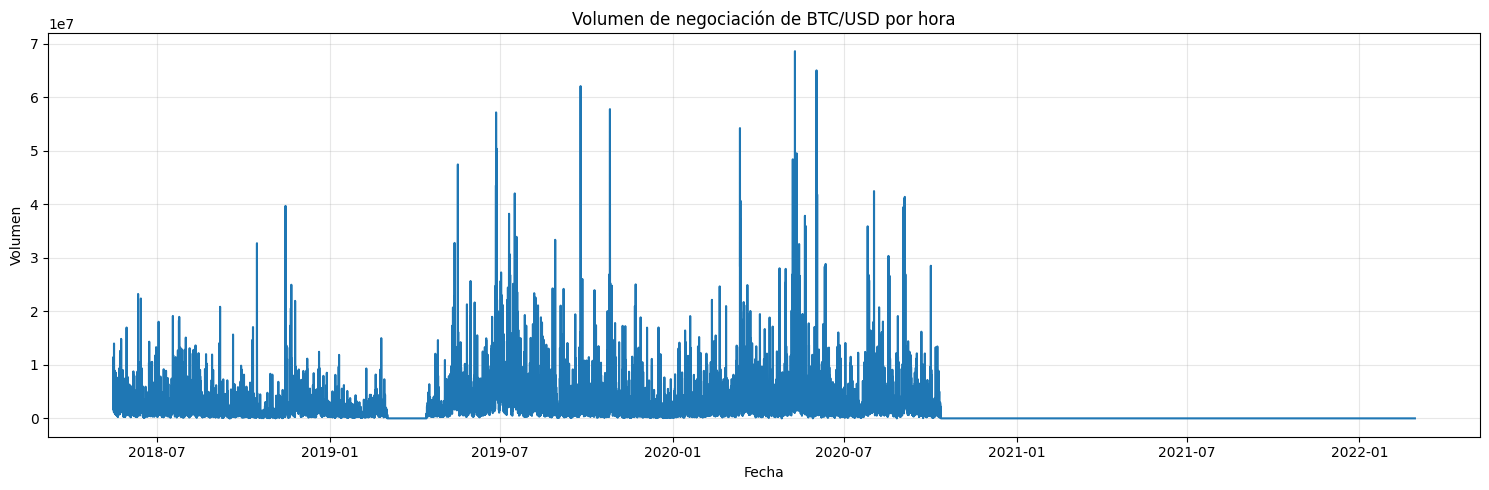

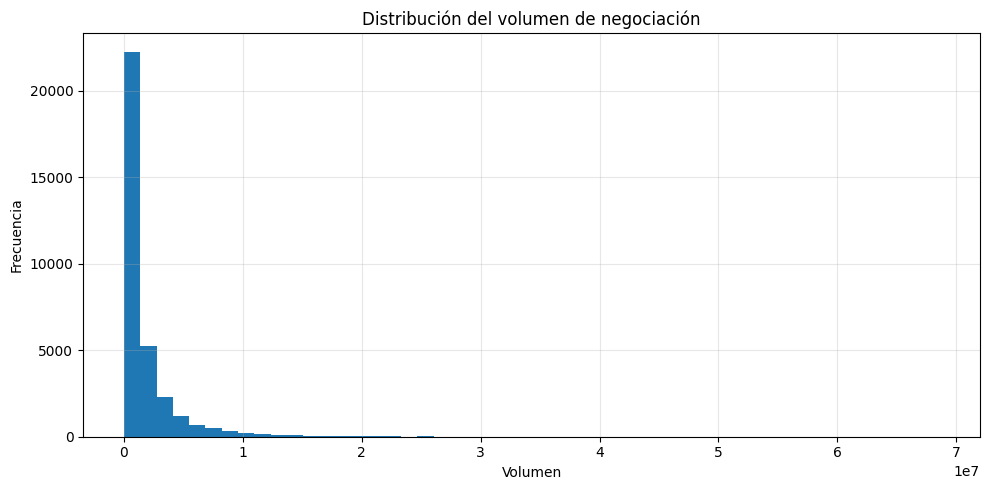

In [ ]:
# ==========================================
# ANALISIS DEL VOLUMEN DE NEGOCIACION
# ==========================================

# Convertir volumen a formato numérico
df["volume"] = pd.to_numeric(df["volume"], errors="coerce")

print("Estadísticas del volumen:")
display(df["volume"].describe())

print("\nValores faltantes:", df["volume"].isna().sum())
print("Valores iguales a cero:", (df["volume"] == 0).sum())
print("Valores negativos:", (df["volume"] < 0).sum())

# Gráfico del volumen a lo largo del tiempo
plt.figure(figsize=(15, 5))
plt.plot(df[col_fecha], df["volume"])
plt.title("Volumen de negociación de BTC/USD por hora")
plt.xlabel("Fecha")
plt.ylabel("Volumen")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Distribución del volumen
plt.figure(figsize=(10, 5))
plt.hist(df["volume"].dropna(), bins=50)
plt.title("Distribución del volumen de negociación")
plt.xlabel("Volumen")
plt.ylabel("Frecuencia")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### 15.1. Validación del volumen de negociación

El análisis del volumen permitió identificar una variación significativa en la escala de esta variable a lo largo del periodo estudiado. Entre 2018 y septiembre de 2020 se registran valores generalmente elevados, mientras que a partir de octubre de 2020 se observa una reducción pronunciada.

Por ejemplo, el volumen promedio semanal pasa de aproximadamente 1,97 millones durante la semana del 4 al 10 de octubre de 2020 a cerca de 204 mil durante la semana siguiente, y posteriormente se sitúa alrededor de unos cientos de unidades.

Este cambio ocurre mientras el precio de cierre continúa registrando valores del mismo orden de magnitud. Por lo tanto, la diferencia observada no puede atribuirse únicamente al comportamiento del precio.

La base contiene un único símbolo, BTC/USD, y no presenta valores negativos ni faltantes en la columna de volumen. Sin embargo, estos resultados no permiten determinar si el cambio responde a una modificación de unidades, de la fuente o del procesamiento de los datos.

En consecuencia, el volumen se documenta como una variable pendiente de validación. No se aplicarán correcciones arbitrarias ni se utilizará como indicador del agente hasta verificar su consistencia.

In [ ]:
# ==========================================
# REVISION DEL VOLUMEN POR AÑO
# ==========================================

df["anio"] = df[col_fecha].dt.year

resumen_volumen = df.groupby("anio").agg(
    registros=("volume", "size"),
    volumen_promedio=("volume", "mean"),
    volumen_mediano=("volume", "median"),
    volumen_minimo=("volume", "min"),
    volumen_maximo=("volume", "max"),
    registros_cero=("volume", lambda x: (x == 0).sum()),
    registros_nulos=("volume", lambda x: x.isna().sum())
)

display(resumen_volumen.round(2))

print("Últimos 15 registros del dataset:")
display(df[[col_fecha, "close", "volume"]].tail(15))

print("Porcentaje de registros con volumen cero:")
print(round((df["volume"] == 0).mean() * 100, 2), "%")

print("Correlación entre precio de cierre y volumen:")
print(df[["close", "volume"]].corr().round(3))

,registros,volumen_promedio,volumen_mediano,volumen_minimo,volumen_maximo,registros_cero,registros_nulos
anio,,,,,,,
2018,5538,1962588.03,1258818.45,9323.62,39676868.06,0,0
2019,8760,2472967.77,1267277.83,16.80,62047295.99,0,0
2020,8784,2401207.67,1318830.04,0.00,68570613.16,4,0
2021,8760,205.82,122.95,0.01,6148.98,0,0
2022,1417,91.68,58.46,0.00,1276.45,1,0


Últimos 15 registros del dataset:


,date,close,volume
33244,2022-02-28 10:00:00+00:00,38404.20,80.171871
33245,2022-02-28 11:00:00+00:00,38367.53,78.152129
33246,2022-02-28 12:00:00+00:00,38271.13,110.749247
33247,2022-02-28 13:00:00+00:00,38056.20,120.015812
33248,2022-02-28 14:00:00+00:00,39840.10,292.856090
33249,2022-02-28 15:00:00+00:00,40846.38,365.055972
33250,2022-02-28 16:00:00+00:00,41008.37,291.623181
33251,2022-02-28 17:00:00+00:00,41432.91,192.789480
33252,2022-02-28 18:00:00+00:00,41233.87,71.233382
33253,2022-02-28 19:00:00+00:00,41362.52,114.268970


Porcentaje de registros con volumen cero:
0.02 %
Correlación entre precio de cierre y volumen:
        close  volume
close   1.000  -0.326
volume -0.326   1.000


In [ ]:
# ==========================================
# INVESTIGAR EL CAMBIO DE ESCALA DEL VOLUMEN
# ==========================================

# Últimos registros de 2020 y primeros de 2021
columnas_revision = [col_fecha, "symbol", "close", "volume"]

display(
    df.loc[
        (df[col_fecha] >= "2020-12-28") &
        (df[col_fecha] < "2021-01-08"),
        columnas_revision
    ]
)

# Resumen mensual para identificar cuándo ocurre el cambio
df["mes"] = df[col_fecha].dt.to_period("M")

resumen_mensual = df.groupby("mes").agg(
    volumen_promedio=("volume", "mean"),
    volumen_mediano=("volume", "median"),
    precio_promedio=("close", "mean"),
    registros=("volume", "size")
)

display(resumen_mensual.round(2))

,date,symbol,close,volume
22986,2020-12-28 00:00:00+00:00,BTC/USD,26850.00,494.609730
22987,2020-12-28 01:00:00+00:00,BTC/USD,27048.50,401.370768
22988,2020-12-28 02:00:00+00:00,BTC/USD,27047.99,199.337613
22989,2020-12-28 03:00:00+00:00,BTC/USD,27250.92,287.943932
22990,2020-12-28 04:00:00+00:00,BTC/USD,26849.03,177.192287
...,...,...,...,...
23245,2021-01-07 19:00:00+00:00,BTC/USD,39100.00,1769.441893
23246,2021-01-07 20:00:00+00:00,BTC/USD,39148.66,833.975919
23247,2021-01-07 21:00:00+00:00,BTC/USD,39724.25,999.604395
23248,2021-01-07 22:00:00+00:00,BTC/USD,39719.25,539.126917


/tmp/ipykernel_4097/3252632104.py:17: UserWarning: Converting to PeriodArray/Index representation will drop timezone information.
  df["mes"] = df[col_fecha].dt.to_period("M")


,volumen_promedio,volumen_mediano,precio_promedio,registros
mes,,,,
2018-05,2798172.80,2077708.91,7851.45,402
2018-06,2265063.73,1577226.57,6784.71,720
2018-07,2362318.22,1536683.38,7098.46,744
2018-08,2146940.45,1511122.58,6689.26,744
2018-09,1479149.45,955354.62,6589.01,720
2018-10,1016286.35,643228.52,6415.20,744
2018-11,2247962.10,1189604.78,5388.03,720
2018-12,1772278.67,1310603.70,3671.08,744
2019-01,1018565.06,764563.21,3658.24,744


### 15.2. Tratamiento de valores faltantes

Los indicadores técnicos y financieros se calculan a partir de observaciones anteriores. Por esta razón, las primeras filas pueden presentar valores faltantes cuando no existe suficiente información histórica para calcular los retornos o las ventanas móviles.

Estos valores deben distinguirse de los faltantes inesperados. En lugar de reemplazarlos automáticamente por cero, se revisará cuáles corresponden al comportamiento esperado de las fórmulas y se determinará el periodo mínimo de observaciones necesario para construir la base analítica final.

La base definitiva conservará únicamente las filas que dispongan de los valores requeridos para las variables seleccionadas, evitando introducir información artificial en los indicadores.

In [ ]:
# ==========================================
# REVISION DE VALORES FALTANTES
# ==========================================

columnas_indicadores = [
    "return",
    "log_return",
    "return_24h",
    "sma_24h",
    "price_vs_sma_24h",
    "volatility_24h",
    "volatility_168h"
]

resumen_nulos = pd.DataFrame({
    "valores_nulos": df[columnas_indicadores].isna().sum(),
    "porcentaje_nulos": (
        df[columnas_indicadores].isna().mean() * 100
    ).round(3)
})

display(resumen_nulos)

print("Dimensiones originales:", df.shape)

print(
    "Primer registro con volatilidad de 168 horas:",
    df.loc[df["volatility_168h"].notna(), col_fecha].min()
)

,valores_nulos,porcentaje_nulos
return,1,0.003
log_return,1,0.003
return_24h,24,0.072
sma_24h,23,0.069
price_vs_sma_24h,23,0.069
volatility_24h,24,0.072
volatility_168h,168,0.505


Dimensiones originales: (33259, 21)
Primer registro con volatilidad de 168 horas: 2018-05-22 06:00:00+00:00


### 15.3. Validación de la estructura temporal

La base presenta una frecuencia horaria y las observaciones se encuentran ordenadas cronológicamente. La validación realizada identificó intervalos consecutivos de una hora y ausencia de fechas duplicadas.

Esta estructura es relevante para el proyecto, ya que las observaciones deben utilizarse respetando su orden temporal. De esta manera, se evita mezclar información futura con información pasada durante la preparación y evaluación del modelo.

Antes de construir la base definitiva, se verificará nuevamente la continuidad temporal después del tratamiento de los valores faltantes.

In [ ]:
# ==========================================
# REVISION DEL CAMBIO DE ESCALA DEL VOLUMEN
# ==========================================

# Estadísticas semanales para ubicar el cambio
df["semana"] = df[col_fecha].dt.strftime("%Y-%U")

resumen_semanal = df.groupby("semana").agg(
    fecha_inicio=(col_fecha, "min"),
    fecha_fin=(col_fecha, "max"),
    volumen_promedio=("volume", "mean"),
    volumen_mediano=("volume", "median"),
    precio_promedio=("close", "mean"),
    registros=("volume", "size")
).reset_index(drop=True)

# Mostrar semanas entre septiembre y diciembre de 2020
display(
    resumen_semanal[
        (resumen_semanal["fecha_inicio"] >= "2020-09-01") &
        (resumen_semanal["fecha_inicio"] < "2021-01-01")
    ].round(2)
)

# Revisar si hay cambios en otras columnas
display(
    df.loc[
        (df[col_fecha] >= "2020-09-01") &
        (df[col_fecha] < "2021-01-01"),
        [col_fecha, "symbol", "open", "high", "low", "close", "volume"]
    ].iloc[::168].head(20)
)

,fecha_inicio,fecha_fin,volumen_promedio,volumen_mediano,precio_promedio,registros
123,2020-09-06 00:00:00+00:00,2020-09-12 23:00:00+00:00,2932676.98,2167295.58,10244.49,168
124,2020-09-13 00:00:00+00:00,2020-09-19 23:00:00+00:00,2473320.14,1901567.62,10775.94,168
125,2020-09-20 00:00:00+00:00,2020-09-26 23:00:00+00:00,2473620.15,1644716.03,10615.88,168
126,2020-09-27 00:00:00+00:00,2020-10-03 23:00:00+00:00,2146514.82,1381044.98,10698.39,168
127,2020-10-04 00:00:00+00:00,2020-10-10 23:00:00+00:00,1972293.95,1330323.95,10813.28,168
128,2020-10-11 00:00:00+00:00,2020-10-17 23:00:00+00:00,204158.47,167.79,11398.77,168
129,2020-10-18 00:00:00+00:00,2020-10-24 23:00:00+00:00,294.97,150.48,12321.18,168
130,2020-10-25 00:00:00+00:00,2020-10-31 23:00:00+00:00,330.42,220.42,13350.05,168
131,2020-11-01 00:00:00+00:00,2020-11-07 23:00:00+00:00,420.16,271.82,14362.40,168
132,2020-11-08 00:00:00+00:00,2020-11-14 23:00:00+00:00,402.64,329.84,15685.02,168


,date,symbol,open,high,low,close,volume
20154,2020-09-01 00:00:00+00:00,BTC/USD,11655.00,11677.83,11515.00,11609.43,5.757071e+06
20322,2020-09-08 00:00:00+00:00,BTC/USD,10377.14,10446.18,10316.20,10322.90,9.970890e+06
20490,2020-09-15 00:00:00+00:00,BTC/USD,10675.15,10706.88,10652.09,10681.48,1.148911e+06
20658,2020-09-22 00:00:00+00:00,BTC/USD,10411.29,10489.59,10353.39,10453.88,2.275823e+06
20826,2020-09-29 00:00:00+00:00,BTC/USD,10689.48,10727.88,10655.82,10705.35,4.108477e+06
20994,2020-10-06 00:00:00+00:00,BTC/USD,10795.00,10801.86,10750.74,10762.20,4.629330e+05
21162,2020-10-13 00:00:00+00:00,BTC/USD,11539.42,11550.51,11421.51,11495.48,1.955346e+02
21330,2020-10-20 00:00:00+00:00,BTC/USD,11759.20,11759.72,11705.04,11726.91,7.827365e+01
21498,2020-10-27 00:00:00+00:00,BTC/USD,13065.10,13137.14,13057.09,13100.65,1.443782e+02
21666,2020-11-03 00:00:00+00:00,BTC/USD,13578.82,13589.00,13465.00,13537.10,4.976184e+02


### 15.4. Separación cronológica de entrenamiento y prueba

Para evaluar el desempeño del agente en observaciones no utilizadas durante el entrenamiento, el conjunto de datos se dividirá respetando el orden cronológico.

Se propone utilizar el 70 % inicial de las observaciones para entrenamiento y el 30 % final para prueba. Esta separación permite evaluar el comportamiento del agente sobre un periodo posterior al utilizado para aprender, reduciendo el riesgo de fuga de información temporal.

La fecha de corte, las dimensiones de cada subconjunto y los periodos correspondientes se registrarán después de ejecutar la división. El conjunto de prueba se reservará para la evaluación final.

In [ ]:
# ==========================================
# VALIDACION FINAL DEL VOLUMEN
# ==========================================

print("Símbolos disponibles:")
display(df["symbol"].value_counts(dropna=False))

# Registros inmediatamente antes y después del cambio
fecha_inicio_revision = "2020-10-08"
fecha_fin_revision = "2020-10-15"

display(
    df.loc[
        (df[col_fecha] >= fecha_inicio_revision) &
        (df[col_fecha] < fecha_fin_revision),
        [col_fecha, "symbol", "open", "high", "low", "close", "volume"]
    ].to_string(index=False)
)

Símbolos disponibles:


,count
symbol,
BTC/USD,33259


'                     date  symbol     open     high      low    close       volume\n2020-10-08 00:00:00+00:00 BTC/USD 10669.14 10676.13 10642.31 10643.18 6.096762e+05\n2020-10-08 01:00:00+00:00 BTC/USD 10643.18 10656.37 10618.94 10644.73 9.107871e+05\n2020-10-08 02:00:00+00:00 BTC/USD 10644.73 10650.29 10626.94 10643.13 5.225745e+05\n2020-10-08 03:00:00+00:00 BTC/USD 10643.13 10661.39 10636.90 10644.54 8.651176e+05\n2020-10-08 04:00:00+00:00 BTC/USD 10644.54 10651.96 10632.59 10632.77 6.448279e+05\n2020-10-08 05:00:00+00:00 BTC/USD 10632.77 10641.36 10604.80 10614.97 1.795319e+06\n2020-10-08 06:00:00+00:00 BTC/USD 10614.97 10633.71 10606.47 10625.92 9.314060e+05\n2020-10-08 07:00:00+00:00 BTC/USD 10625.92 10625.92 10566.71 10590.89 3.594173e+06\n2020-10-08 08:00:00+00:00 BTC/USD 10590.89 10605.82 10555.55 10560.22 1.990912e+06\n2020-10-08 09:00:00+00:00 BTC/USD 10560.22 10579.39 10535.06 10565.02 2.330214e+06\n2020-10-08 10:00:00+00:00 BTC/USD 10565.02 10635.23 10557.82 10612.00 1.265

### 15.5. Exportación de la base analítica final

Una vez finalizadas las validaciones y la selección de variables, se exportará la base analítica en formato CSV. El archivo incluirá las fechas, los precios y los indicadores seleccionados para el proyecto.

Se comprobará que el archivo exportado pueda cargarse nuevamente, que las columnas requeridas estén disponibles y que no existan valores faltantes en las variables utilizadas por el modelo. También se conservará la referencia a la fuente original y el registro de las transformaciones aplicadas.

### 15.6. Conclusiones de la validación final

La revisión de los valores faltantes permitió identificar que estos se concentran principalmente en las primeras observaciones de los indicadores calculados a partir de ventanas temporales.

Las variables `return` y `log_return` presentan un valor faltante cada una, correspondiente a la primera observación, ya que requieren un precio anterior para calcular la variación. Por su parte, `return_24h` y `volatility_24h` presentan 24 valores faltantes, mientras que `sma_24h` y `price_vs_sma_24h` presentan 23. Estos valores se relacionan con la necesidad de disponer de suficiente información histórica para realizar los cálculos.

La variable `volatility_168h` presenta 168 valores faltantes, equivalentes aproximadamente al 0,505 % del conjunto de datos. Su primer valor disponible corresponde al 22 de mayo de 2018 a las 06:00 UTC, después de completar la ventana histórica de 168 horas.

En consecuencia, los valores faltantes iniciales se consideran esperados por la construcción de los indicadores. Para preparar la base analítica se conservarán las observaciones que dispongan de los valores requeridos para las variables seleccionadas, sin sustituir los valores faltantes por ceros ni introducir información artificial.

Adicionalmente, se identificó una diferencia de escala en el volumen de negociación a partir de octubre de 2020, cuya causa aún requiere validación. Este hallazgo se documentará como una limitación del conjunto de datos y se tendrá en cuenta al seleccionar las variables para las siguientes etapas del proyecto.

Finalmente, la preparación de la base continuará con la selección de variables, la separación cronológica de los datos y la exportación del archivo analítico definitivo.

### 15.7. Selección de variables para la base analítica

A partir de los resultados del análisis exploratorio, se seleccionan las variables que describen el comportamiento del precio y algunas características derivadas de su evolución temporal.

Se conservarán los precios de apertura, máximo, mínimo y cierre, junto con los indicadores `return_24h`, `price_vs_sma_24h` y `volatility_24h`. La fecha se mantendrá para garantizar el orden cronológico y facilitar la trazabilidad de las observaciones.

El volumen de negociación no se incluirá inicialmente entre las variables candidatas debido a la diferencia de escala identificada durante el periodo analizado. Asimismo, `volatility_168h` se excluirá de esta primera selección para simplificar el tratamiento de los valores faltantes.

Esta selección es preliminar y deberá revisarse al definir las variables de observación que utilizará el agente.

In [ ]:
# ==========================================
# 15.7. SELECCION DE VARIABLES
# ==========================================

columnas_finales = [
    col_fecha,
    "open",
    "high",
    "low",
    "close",
    "return_24h",
    "price_vs_sma_24h",
    "volatility_24h"
]

df_final = df[columnas_finales].copy()

# Eliminar únicamente filas que no tengan
# información en los indicadores seleccionados
df_final = (
    df_final
    .dropna(
        subset=[
            "return_24h",
            "price_vs_sma_24h",
            "volatility_24h"
        ]
    )
    .sort_values(col_fecha)
    .reset_index(drop=True)
)

print("Dimensiones de la base analítica:", df_final.shape)

print("\nValores faltantes:")
display(df_final.isna().sum())

print("\nPrimeras observaciones:")
display(df_final.head())

print("\nÚltimas observaciones:")
display(df_final.tail())

Dimensiones de la base analítica: (33235, 8)

Valores faltantes:


,0
date,0
open,0
high,0
low,0
close,0
return_24h,0
price_vs_sma_24h,0
volatility_24h,0



Primeras observaciones:


,date,open,high,low,close,return_24h,price_vs_sma_24h,volatility_24h
0,2018-05-16 06:00:00+00:00,8220.40,8267.12,8176.91,8238.80,-0.057452,-0.031495,0.008531
1,2018-05-16 07:00:00+00:00,8238.80,8255.00,8213.79,8232.99,-0.057903,-0.029773,0.008526
2,2018-05-16 08:00:00+00:00,8232.99,8261.24,8200.00,8207.48,-0.059691,-0.030298,0.008523
3,2018-05-16 09:00:00+00:00,8207.48,8263.93,8207.48,8243.45,-0.053382,-0.023815,0.008639
4,2018-05-16 10:00:00+00:00,8243.45,8455.66,8237.10,8371.13,-0.048292,-0.006613,0.009037



Últimas observaciones:


,date,open,high,low,close,return_24h,price_vs_sma_24h,volatility_24h
33230,2022-02-28 20:00:00+00:00,41361.99,41971.00,41284.11,41914.97,0.103611,0.077791,0.012384
33231,2022-02-28 21:00:00+00:00,41917.09,41917.09,41542.60,41659.53,0.113593,0.066367,0.011909
33232,2022-02-28 22:00:00+00:00,41657.23,44256.08,41650.29,42907.32,0.134131,0.092395,0.012932
33233,2022-02-28 23:00:00+00:00,43085.30,43364.81,42892.37,43178.98,0.144946,0.092973,0.012805
33234,2022-03-01 00:00:00+00:00,43221.71,43626.49,43185.48,43312.27,0.152806,0.089749,0.012660


### 15.8. Separación cronológica de entrenamiento y prueba

Con el propósito de evaluar el agente sobre observaciones que no hayan sido utilizadas durante el entrenamiento, la base analítica se dividirá cronológicamente en dos subconjuntos.

Se utilizará el 70 % inicial de las observaciones para entrenamiento y el 30 % final para prueba. La división conservará el orden temporal de los registros, sin mezclar aleatoriamente las observaciones.

El conjunto de prueba representará un periodo posterior al de entrenamiento, lo que permitirá analizar el desempeño del agente ante condiciones de mercado diferentes de las observadas durante su aprendizaje. Las fechas y dimensiones de ambos subconjuntos se registrarán para garantizar la trazabilidad del proceso.

In [ ]:
# ==========================================
# 15.8. SEPARACION CRONOLOGICA 70/30
# ==========================================

# Garantizar orden cronológico
df_final = df_final.sort_values(col_fecha).reset_index(drop=True)

# Punto de corte: 70 % para entrenamiento
punto_corte = int(len(df_final) * 0.70)

df_train = df_final.iloc[:punto_corte].copy()
df_test = df_final.iloc[punto_corte:].copy()

# Resumen de la división
print("Total de observaciones:", len(df_final))
print("Observaciones de entrenamiento:", len(df_train))
print("Observaciones de prueba:", len(df_test))

print("\nPorcentaje de entrenamiento:",
      round(len(df_train) / len(df_final) * 100, 2), "%")
print("Porcentaje de prueba:",
      round(len(df_test) / len(df_final) * 100, 2), "%")

print("\nPeriodo de entrenamiento:")
print(df_train[col_fecha].min(), "hasta", df_train[col_fecha].max())

print("\nPeriodo de prueba:")
print(df_test[col_fecha].min(), "hasta", df_test[col_fecha].max())

# Verificaciones
print("\n¿Entrenamiento ordenado?",
      df_train[col_fecha].is_monotonic_increasing)
print("¿Prueba ordenada?",
      df_test[col_fecha].is_monotonic_increasing)
print("¿Los periodos están separados?",
      df_train[col_fecha].max() < df_test[col_fecha].min())

Total de observaciones: 33235
Observaciones de entrenamiento: 23264
Observaciones de prueba: 9971

Porcentaje de entrenamiento: 70.0 %
Porcentaje de prueba: 30.0 %

Periodo de entrenamiento:
2018-05-16 06:00:00+00:00 hasta 2021-01-09 13:00:00+00:00

Periodo de prueba:
2021-01-09 14:00:00+00:00 hasta 2022-03-01 00:00:00+00:00

¿Entrenamiento ordenado? True
¿Prueba ordenada? True
¿Los periodos están separados? True


La división cronológica generó dos subconjuntos a partir de las 33.235 observaciones de la base analítica. El conjunto de entrenamiento contiene 23.264 registros, equivalentes al 70 % de los datos, mientras que el conjunto de prueba contiene 9.971 registros, correspondientes al 30 % restante.

El periodo de entrenamiento comprende desde el 16 de mayo de 2018 a las 06:00 UTC hasta el 9 de enero de 2021 a las 13:00 UTC. Por su parte, el periodo de prueba comienza el 9 de enero de 2021 a las 14:00 UTC y finaliza el 1 de marzo de 2022 a las 00:00 UTC.

Las verificaciones confirmaron que ambos subconjuntos conservan el orden cronológico y que no existe superposición entre sus periodos. Esta separación permitirá evaluar posteriormente el agente sobre datos posteriores a los utilizados para su entrenamiento.

In [ ]:
# ==========================================
# 15.9. EXPORTACION Y VALIDACION
# ==========================================

from pathlib import Path
import pandas as pd

# Carpeta de salida
carpeta_salida = Path("/content/agente_inversor/data")
carpeta_salida.mkdir(parents=True, exist_ok=True)

# Archivos de salida
archivo_completo = carpeta_salida / "BTC_USD_base_analitica.csv"
archivo_train = carpeta_salida / "BTC_USD_train.csv"
archivo_test = carpeta_salida / "BTC_USD_test.csv"

# Exportar sin el índice de pandas
df_final.to_csv(archivo_completo, index=False)
df_train.to_csv(archivo_train, index=False)
df_test.to_csv(archivo_test, index=False)

# Validar recargando los archivos
base_verificada = pd.read_csv(archivo_completo)
train_verificado = pd.read_csv(archivo_train)
test_verificado = pd.read_csv(archivo_test)

print("BASE ANALITICA")
print("Filas:", len(base_verificada))
print("Columnas:", len(base_verificada.columns))
print("Valores faltantes:", base_verificada.isna().sum().sum())

print("\nENTRENAMIENTO")
print("Filas:", len(train_verificado))

print("\nPRUEBA")
print("Filas:", len(test_verificado))

print("\n¿Coinciden las dimensiones?",
      len(train_verificado) + len(test_verificado)
      == len(base_verificada))

print("\nArchivos guardados:")
print(archivo_completo)
print(archivo_train)
print(archivo_test)

BASE ANALITICA
Filas: 33235
Columnas: 8
Valores faltantes: 0

ENTRENAMIENTO
Filas: 23264

PRUEBA
Filas: 9971

¿Coinciden las dimensiones? True

Archivos guardados:
/content/agente_inversor/data/BTC_USD_base_analitica.csv
/content/agente_inversor/data/BTC_USD_train.csv
/content/agente_inversor/data/BTC_USD_test.csv


### Conclusiones del análisis exploratorio

El análisis exploratorio permitió identificar las principales características de la serie histórica del par BTC/USD, incluyendo su evolución temporal, la variabilidad de los retornos y los cambios en la volatilidad del mercado. Asimismo, se validó la continuidad de los registros horarios y se revisó la calidad de las variables disponibles.

A partir de este análisis, se seleccionaron variables relacionadas con los precios de mercado, los retornos recientes, la diferencia entre el precio de cierre y su media móvil, y la volatilidad de corto plazo. Estas variables proporcionan información complementaria sobre el comportamiento reciente del activo y podrán utilizarse como componentes del estado del agente de aprendizaje por refuerzo.

El volumen de negociación se analizó como parte de la exploración, pero se identificaron cambios importantes en su escala que requieren precaución en su interpretación. Por esta razón, no se incluyó entre las variables seleccionadas para el análisis inicial.

Finalmente, los datos se organizaron cronológicamente y se separaron en conjuntos de entrenamiento y evaluación, manteniendo el periodo de evaluación independiente del entrenamiento. Esta separación permitirá estudiar el comportamiento del agente sobre observaciones que no se utilizaron durante su aprendizaje.

# 16. Diseño del entorno de inversión

## 16.1. Creación del entorno de simulación

Se diseñó un entorno de inversión simulado para el par BTC/USD, compatible con la interfaz de Gymnasium, con el propósito de permitir que un agente de aprendizaje por refuerzo interactúe con datos históricos y aprenda a tomar decisiones de inversión.

El entorno utiliza las variables previamente preparadas en el análisis exploratorio y simula la evolución de una cartera compuesta por efectivo y Bitcoin. En cada paso, el agente recibe información del mercado, selecciona una acción y observa el resultado de su decisión.

Para mantener una representación coherente de las operaciones, el entorno administra el efectivo disponible, la cantidad de Bitcoin en posesión y el valor total de la cartera. También contempla un costo de transacción al realizar operaciones, de modo que la evaluación considere su efecto sobre el resultado económico.

El entorno se implementa como una secuencia temporal: después de cada decisión, avanza a la siguiente observación horaria disponible. Esta estructura permite estudiar el comportamiento de la estrategia a lo largo del tiempo y constituye la base para entrenar y evaluar posteriormente el agente DQN.

In [ ]:
from pathlib import Path
import pandas as pd

carpeta_datos = Path("/content/agente_inversor/data")

df_train = pd.read_csv(carpeta_datos / "BTC_USD_train.csv")
df_test = pd.read_csv(carpeta_datos / "BTC_USD_test.csv")

print("Entrenamiento:", df_train.shape)
print("Evaluación:", df_test.shape)

print("\nColumnas disponibles:")
print(df_train.columns.tolist())

display(df_train.head())

Entrenamiento: (23264, 8)
Evaluación: (9971, 8)

Columnas disponibles:
['date', 'open', 'high', 'low', 'close', 'return_24h', 'price_vs_sma_24h', 'volatility_24h']


,date,open,high,low,close,return_24h,price_vs_sma_24h,volatility_24h
0,2018-05-16 06:00:00+00:00,8220.40,8267.12,8176.91,8238.80,-0.057452,-0.031495,0.008531
1,2018-05-16 07:00:00+00:00,8238.80,8255.00,8213.79,8232.99,-0.057903,-0.029773,0.008526
2,2018-05-16 08:00:00+00:00,8232.99,8261.24,8200.00,8207.48,-0.059691,-0.030298,0.008523
3,2018-05-16 09:00:00+00:00,8207.48,8263.93,8207.48,8243.45,-0.053382,-0.023815,0.008639
4,2018-05-16 10:00:00+00:00,8243.45,8455.66,8237.10,8371.13,-0.048292,-0.006613,0.009037


###Instalar e importar las librerías

In [ ]:
!pip install -q gymnasium

import gymnasium as gym
from gymnasium import spaces
import numpy as np
import pandas as pd

SEED = 42
np.random.seed(SEED)

print("Librerías instaladas e importadas correctamente.")
print("Semilla de reproducibilidad:", SEED)

Librerías instaladas e importadas correctamente.
Semilla de reproducibilidad: 42


###Creación del entorno de inversión BTC/USD

In [ ]:
class EntornoInversionBTC(gym.Env):
    """
    Entorno de inversión simulado para BTC/USD.

    Acciones:
    0 = Mantener la posición actual
    1 = Pasar a efectivo
    2 = Pasar a Bitcoin
    """

    metadata = {"render_modes": []}

    def __init__(
        self,
        datos,
        capital_inicial=10000.0,
        costo_transaccion=0.001
    ):
        super().__init__()

        self.datos = datos.reset_index(drop=True).copy()
        self.capital_inicial = float(capital_inicial)
        self.costo_transaccion = float(costo_transaccion)

        self.columnas_estado = [
            "return_24h",
            "price_vs_sma_24h",
            "volatility_24h"
        ]

        columnas_requeridas = [
            "close",
            *self.columnas_estado
        ]

        faltantes = set(columnas_requeridas) - set(self.datos.columns)

        if faltantes:
            raise ValueError(f"Faltan columnas: {faltantes}")

        if len(self.datos) < 2:
            raise ValueError("Se necesitan al menos dos observaciones.")

        if not np.isfinite(
            self.datos[columnas_requeridas].to_numpy(dtype=float)
        ).all():
            raise ValueError("Existen valores no finitos en los datos.")

        if (self.datos["close"] <= 0).any():
            raise ValueError("Los precios deben ser positivos.")

        if self.capital_inicial <= 0:
            raise ValueError("El capital inicial debe ser positivo.")

        if not 0 <= self.costo_transaccion < 1:
            raise ValueError("El costo de transacción no es válido.")

        # Espacio de acciones: mantener, efectivo o Bitcoin
        self.action_space = spaces.Discrete(3)

        # Estado: tres indicadores y la posición actual
        self.observation_space = spaces.Box(
            low=-np.inf,
            high=np.inf,
            shape=(4,),
            dtype=np.float32
        )

        self.reset(seed=SEED)

    def _valor_cartera(self, precio):
        return self.efectivo + self.cantidad_btc * precio

    def _obtener_estado(self):
        fila = self.datos.iloc[self.indice]

        indicadores = fila[self.columnas_estado].to_numpy(
            dtype=np.float32
        )

        return np.append(
            indicadores,
            np.float32(self.posicion)
        ).astype(np.float32)

    def reset(self, seed=None, options=None):
        super().reset(seed=seed)

        self.indice = 0
        self.efectivo = self.capital_inicial
        self.cantidad_btc = 0.0
        self.posicion = 0  # 0 = efectivo; 1 = Bitcoin

        precio = float(self.datos.iloc[self.indice]["close"])
        self.capital = self._valor_cartera(precio)

        return self._obtener_estado(), {
            "capital": self.capital,
            "efectivo": self.efectivo,
            "cantidad_btc": self.cantidad_btc,
            "posicion": self.posicion
        }

    def step(self, action):
        if not self.action_space.contains(action):
            raise ValueError(f"Acción inválida: {action}")

        precio_actual = float(
            self.datos.iloc[self.indice]["close"]
        )

        # Valor de la cartera antes de operar
        capital_anterior = self._valor_cartera(precio_actual)

        # Acción 1: vender BTC y pasar a efectivo
        if action == 1 and self.posicion == 1:
            valor_venta = self.cantidad_btc * precio_actual

            self.efectivo = (
                valor_venta * (1 - self.costo_transaccion)
            )

            self.cantidad_btc = 0.0
            self.posicion = 0

        # Acción 2: comprar BTC con el efectivo disponible
        elif action == 2 and self.posicion == 0:
            efectivo_invertible = (
                self.efectivo * (1 - self.costo_transaccion)
            )

            self.cantidad_btc = (
                efectivo_invertible / precio_actual
            )

            self.efectivo = 0.0
            self.posicion = 1

        # Avanzar a la siguiente observación horaria
        self.indice += 1

        precio_siguiente = float(
            self.datos.iloc[self.indice]["close"]
        )

        capital_nuevo = self._valor_cartera(precio_siguiente)

        # Recompensa: retorno logarítmico de la cartera
        recompensa = np.log(
            max(capital_nuevo, 1e-12) /
            max(capital_anterior, 1e-12)
        )

        terminado = self.indice >= len(self.datos) - 1
        truncado = False

        self.capital = capital_nuevo

        info = {
            "capital": self.capital,
            "efectivo": self.efectivo,
            "cantidad_btc": self.cantidad_btc,
            "posicion": self.posicion,
            "precio": precio_siguiente
        }

        return (
            self._obtener_estado(),
            float(recompensa),
            terminado,
            truncado,
            info
        )

### 16.2. Validación del funcionamiento del entorno

Se realizaron pruebas funcionales para verificar el comportamiento de las acciones disponibles y el registro del capital de la cartera. Los resultados mostraron que el entorno permite comprar Bitcoin, mantener la posición, vender el activo y permanecer en efectivo.

Asimismo, se comprobó que las operaciones de compra y venta incorporan el costo de transacción definido y que las variaciones del precio afectan el valor de la cartera cuando existe una posición en Bitcoin. Cuando la cartera permanece completamente en efectivo y no se realizan operaciones, su valor se mantiene constante.

Estas pruebas constituyen una validación inicial del funcionamiento del entorno. Antes del entrenamiento del agente, se verificará adicionalmente la consistencia temporal de las operaciones, el cálculo de las recompensas y la finalización de los episodios.

In [ ]:
from gymnasium.utils.env_checker import check_env

entorno = EntornoInversionBTC(
    datos=df_train,
    capital_inicial=10000,
    costo_transaccion=0.001
)

# Validar la estructura del entorno
check_env(entorno, skip_render_check=True)

# Reiniciar y observar el estado inicial
estado, info = entorno.reset(seed=SEED)

print("ENTORNO VALIDADO")
print("-" * 40)
print("Acciones disponibles:", entorno.action_space)
print("Espacio de observaciones:", entorno.observation_space)
print("Estado inicial:", estado)
print("Capital inicial:", info["capital"])

# Probar una compra de Bitcoin
estado, recompensa, terminado, truncado, info = entorno.step(2)

print("\nRESULTADO DE LA PRUEBA")
print("-" * 40)
print("Recompensa:", recompensa)
print("Capital:", info["capital"])
print("Efectivo:", info["efectivo"])
print("Cantidad de BTC:", info["cantidad_btc"])
print("Posición:", info["posicion"])
print("Estado siguiente:", estado)

ENTORNO VALIDADO
----------------------------------------
Acciones disponibles: Discrete(3)
Espacio de observaciones: Box(-inf, inf, (4,), float32)
Estado inicial: [-0.0574523  -0.03149472  0.00853114  0.        ]
Capital inicial: 10000.0

RESULTADO DE LA PRUEBA
----------------------------------------
Recompensa: -0.0017059488902916055
Capital: 9982.955054134098
Efectivo: 0.0
Cantidad de BTC: 1.2125552264892947
Posición: 1
Estado siguiente: [-0.05790251 -0.02977302  0.00852634  1.        ]


/usr/local/lib/python3.13/dist-packages/gymnasium/utils/env_checker.py:317: UserWarning: WARN: A Box observation space minimum value is -infinity. This is probably too low.
  logger.warn(
/usr/local/lib/python3.13/dist-packages/gymnasium/utils/env_checker.py:321: UserWarning: WARN: A Box observation space maximum value is infinity. This is probably too high.
  logger.warn(


### 16.3. Comprobación de la cartera

Se realizó una prueba para verificar la consistencia del registro del capital, el efectivo disponible y la cantidad de Bitcoin mantenida durante las operaciones simuladas. Para ello, se ejecutó una secuencia de acciones de compra, mantenimiento y venta, observando la evolución del valor de la cartera.

La prueba permitió comprobar que, al comprar Bitcoin, el efectivo se convierte en una posición en el activo; al mantenerlo, el valor de la cartera cambia según las variaciones del precio; y al venderlo, la posición se convierte nuevamente en efectivo, aplicando el costo de transacción correspondiente.

Esta comprobación permite verificar el funcionamiento básico de la contabilidad de la cartera antes de utilizar el entorno para entrenar el agente de aprendizaje por refuerzo.

In [ ]:
# Comprobación de la cartera durante las operaciones

entorno = EntornoInversionBTC(
    datos=df_train,
    capital_inicial=10000,
    costo_transaccion=0.001
)

estado, info = entorno.reset(seed=SEED)

acciones = [
    (2, "Comprar BTC"),
    (0, "Mantener BTC"),
    (0, "Mantener BTC"),
    (1, "Vender BTC"),
    (0, "Mantener efectivo")
]

print("COMPROBACIÓN DE LA CARTERA")
print("-" * 85)

errores = []

for paso, (accion, descripcion) in enumerate(acciones, start=1):
    estado, recompensa, terminado, truncado, info = entorno.step(accion)

    precio = info["precio"]
    efectivo = info["efectivo"]
    cantidad_btc = info["cantidad_btc"]
    capital = info["capital"]

    # Recalcular independientemente el valor de la cartera
    capital_calculado = efectivo + cantidad_btc * precio

    consistente = np.isclose(
        capital, capital_calculado, rtol=1e-9, atol=1e-6
    )

    if not consistente:
        errores.append(paso)

    print(f"Paso: {paso} | Acción: {descripcion}")
    print(f"  Precio BTC:       {precio:.2f}")
    print(f"  Efectivo:         {efectivo:.2f}")
    print(f"  Cantidad BTC:     {cantidad_btc:.8f}")
    print(f"  Capital registrado: {capital:.2f}")
    print(f"  Capital calculado:  {capital_calculado:.2f}")
    print(f"  Contabilidad consistente: {consistente}")
    print("-" * 85)

print("RESULTADO FINAL")
print("Comprobaciones correctas:", len(acciones) - len(errores), "de", len(acciones))
print("Pasos con inconsistencias:", errores)

COMPROBACIÓN DE LA CARTERA
-------------------------------------------------------------------------------------
Paso: 1 | Acción: Comprar BTC
  Precio BTC:       8232.99
  Efectivo:         0.00
  Cantidad BTC:     1.21255523
  Capital registrado: 9982.96
  Capital calculado:  9982.96
  Contabilidad consistente: True
-------------------------------------------------------------------------------------
Paso: 2 | Acción: Mantener BTC
  Precio BTC:       8207.48
  Efectivo:         0.00
  Cantidad BTC:     1.21255523
  Capital registrado: 9952.02
  Capital calculado:  9952.02
  Contabilidad consistente: True
-------------------------------------------------------------------------------------
Paso: 3 | Acción: Mantener BTC
  Precio BTC:       8243.45
  Efectivo:         0.00
  Cantidad BTC:     1.21255523
  Capital registrado: 9995.64
  Capital calculado:  9995.64
  Contabilidad consistente: True
-------------------------------------------------------------------------------------
Paso: 

### 16.3.1. Resultados de la comprobación de la cartera

La comprobación se realizó mediante una secuencia de cinco acciones que incluyó la compra de Bitcoin, el mantenimiento de la posición, la venta del activo y el mantenimiento del efectivo.

En cada paso se verificó que el capital registrado por el entorno coincidiera con el valor calculado a partir del efectivo disponible y la cantidad de Bitcoin mantenida, valorada al precio de cierre correspondiente.

Las cinco comprobaciones fueron satisfactorias y no se identificaron inconsistencias contables. Asimismo, se observó que el capital variaba de acuerdo con los movimientos del precio mientras existía una posición en Bitcoin y permanecía constante cuando la cartera se encontraba completamente en efectivo.

Estos resultados validan la consistencia contable básica del entorno para la secuencia probada. Sin embargo, esta prueba no constituye por sí sola una validación completa de todas las transiciones posibles ni del desempeño de una estrategia de inversión.

In [ ]:
# Validación de un episodio completo

entorno = EntornoInversionBTC(
    datos=df_train,
    capital_inicial=10000,
    costo_transaccion=0.001
)

estado, info = entorno.reset(seed=SEED)

pasos = 0
recompensa_acumulada = 0.0
terminado = False
truncado = False

while not (terminado or truncado):
    accion = 0  # Mantener efectivo

    estado, recompensa, terminado, truncado, info = entorno.step(accion)

    recompensa_acumulada += recompensa
    pasos += 1

print("VALIDACIÓN DEL EPISODIO")
print("-" * 40)
print("Pasos ejecutados:", pasos)
print("Pasos esperados:", len(df_train) - 1)
print("Capital inicial:", 10000.0)
print("Capital final:", round(info["capital"], 2))
print("Recompensa acumulada:", round(recompensa_acumulada, 6))
print("Episodio terminado:", terminado)
print("Truncado:", truncado)

VALIDACIÓN DEL EPISODIO
----------------------------------------
Pasos ejecutados: 23263
Pasos esperados: 23263
Capital inicial: 10000.0
Capital final: 10000.0
Recompensa acumulada: 0.0
Episodio terminado: True
Truncado: False


### 16.4. Validación del episodio completo

Se ejecutó un episodio completo utilizando el conjunto de entrenamiento, compuesto por 23.264 observaciones, y una estrategia de referencia que mantiene la totalidad del capital en efectivo durante toda la simulación.

El entorno ejecutó los 23.263 pasos esperados y finalizó correctamente, sin interrupciones por truncamiento. El capital inicial y final fue de $10.000, mientras que la recompensa acumulada fue cero, dado que no se realizaron operaciones ni se mantuvieron posiciones en Bitcoin.

Los resultados son consistentes con el comportamiento esperado de una cartera completamente líquida y permiten validar la duración del episodio, la condición de terminación y el cálculo de la recompensa en este escenario de prueba.

### 16.5. Definición del estado, las acciones y la recompensa

El entorno representa el estado del mercado mediante tres indicadores: el retorno de las últimas 24 horas (`return_24h`), la diferencia relativa del precio frente a su media móvil de 24 horas (`price_vs_sma_24h`) y la volatilidad de las últimas 24 horas (`volatility_24h`). Adicionalmente, incorpora la posición actual del agente, que indica si mantiene efectivo o Bitcoin.

El agente dispone de tres acciones: mantener la posición actual, vender Bitcoin para pasar a efectivo y comprar Bitcoin utilizando el efectivo disponible. La compra y la venta incluyen un costo de transacción del 0,1 %.

La recompensa se calcula mediante el logaritmo de la relación entre el valor de la cartera después de la decisión y su valor antes de ella. De esta manera, el agente recibe recompensas positivas cuando aumenta el valor de su cartera y negativas cuando disminuye. El diseño busca que las decisiones consideren tanto los cambios del precio como los costos asociados a las operaciones.

In [ ]:
# Configuración del estado, las acciones y la recompensa

print("DEFINICIÓN DEL ENTORNO")
print("-" * 45)

print("\nESTADO")
print("Variables de mercado:")
for columna in entorno.columnas_estado:
    print(f"- {columna}")

print("- Posición actual del agente (0: efectivo, 1: BTC)")
print("Dimensión del estado:", entorno.observation_space.shape)

print("\nACCIONES")
print("0: Mantener la posición actual")
print("1: Vender BTC y pasar a efectivo")
print("2: Comprar BTC con el efectivo disponible")

print("\nRECOMPENSA")
print("Logaritmo del cociente entre el capital nuevo y el capital anterior")

print("\nPARÁMETROS")
print(f"Capital inicial: ${entorno.capital_inicial:,.2f}")
print(f"Costo de transacción: {entorno.costo_transaccion:.2%}")

DEFINICIÓN DEL ENTORNO
---------------------------------------------

ESTADO
Variables de mercado:
- return_24h
- price_vs_sma_24h
- volatility_24h
- Posición actual del agente (0: efectivo, 1: BTC)
Dimensión del estado: (4,)

ACCIONES
0: Mantener la posición actual
1: Vender BTC y pasar a efectivo
2: Comprar BTC con el efectivo disponible

RECOMPENSA
Logaritmo del cociente entre el capital nuevo y el capital anterior

PARÁMETROS
Capital inicial: $10,000.00
Costo de transacción: 0.10%


### 16.6. Consideraciones sobre el diseño de la recompensa

La recompensa se basa en el rendimiento logarítmico de la cartera entre dos pasos consecutivos. Este criterio permite evaluar las decisiones del agente considerando tanto las variaciones del valor de la inversión como el efecto de los costos de transacción.

Cuando el agente permanece en efectivo, el valor de la cartera no cambia por las fluctuaciones del precio de Bitcoin y la recompensa es cero, siempre que no se realicen operaciones. Cuando mantiene Bitcoin, la recompensa refleja los cambios en el valor del activo. Las compras y ventas incorporan el costo de transacción correspondiente.

Este diseño busca orientar el aprendizaje hacia decisiones que mejoren el rendimiento de la cartera durante la simulación. No obstante, el desempeño de la estrategia deberá evaluarse posteriormente con datos no utilizados durante el entrenamiento y compararse con estrategias de referencia.

In [ ]:
# Comprobación manual de la recompensa

entorno = EntornoInversionBTC(
    datos=df_train,
    capital_inicial=10000,
    costo_transaccion=0.001
)

estado, info = entorno.reset(seed=SEED)

capital_anterior = info["capital"]

estado, recompensa, terminado, truncado, info = entorno.step(2)

capital_nuevo = info["capital"]

recompensa_calculada = np.log(capital_nuevo / capital_anterior)

print("COMPROBACIÓN DE LA RECOMPENSA")
print("-" * 40)
print(f"Capital anterior: ${capital_anterior:,.2f}")
print(f"Capital nuevo: ${capital_nuevo:,.2f}")
print(f"Recompensa del entorno: {recompensa:.8f}")
print(f"Recompensa calculada:    {recompensa_calculada:.8f}")
print(
    "¿Coinciden los resultados?:",
    np.isclose(recompensa, recompensa_calculada)
)

COMPROBACIÓN DE LA RECOMPENSA
----------------------------------------
Capital anterior: $10,000.00
Capital nuevo: $9,982.96
Recompensa del entorno: -0.00170595
Recompensa calculada:    -0.00170595
¿Coinciden los resultados?: True


## 17. Desarrollo del agente de aprendizaje por refuerzo

### 17.1. Selección del algoritmo DQN

Se seleccionó el algoritmo Deep Q-Network (DQN) para aprender una política de inversión a partir de las observaciones del mercado y las recompensas obtenidas en el entorno simulado. El agente utilizará una red neuronal para estimar el valor de las acciones disponibles en cada estado y seleccionar decisiones orientadas a maximizar la recompensa acumulada.

El entrenamiento se realizará utilizando exclusivamente el conjunto de datos de entrenamiento. Posteriormente, el agente se evaluará sobre el conjunto de prueba, manteniendo la separación temporal establecida durante la preparación de los datos.

In [ ]:
# Instalación de las librerías necesarias
!pip install -q torch

In [ ]:
# Librerías para construir y entrenar el agente DQN

import random
from collections import deque

import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim

# Configuración de reproducibilidad
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

# Selección del dispositivo de ejecución
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("PyTorch:", torch.__version__)
print("Dispositivo:", device)
print("Semilla:", SEED)

PyTorch: 2.11.0+cpu
Dispositivo: cpu
Semilla: 42


### 17.2. Arquitectura de la red neuronal

Se implementó una red neuronal tipo *Multilayer Perceptron* (MLP) para estimar el valor esperado de cada acción disponible a partir del estado observado. La red recibe cuatro entradas correspondientes a los indicadores del mercado y la posición actual de la cartera. Utiliza dos capas ocultas de 64 neuronas con función de activación ReLU y una capa de salida con tres valores Q, uno por cada acción posible.

Esta arquitectura permite aproximar la función de valor de acción \(Q(s,a)\), que el agente utilizará para seleccionar entre mantener la posición, vender Bitcoin o comprarlo.

In [ ]:
# Red neuronal del agente DQN

class RedDQN(nn.Module):
    def __init__(self, dimension_estado, numero_acciones):
        super().__init__()

        self.red = nn.Sequential(
            nn.Linear(dimension_estado, 64),
            nn.ReLU(),
            nn.Linear(64, 64),
            nn.ReLU(),
            nn.Linear(64, numero_acciones)
        )

    def forward(self, estado):
        return self.red(estado)


# Crear la red según el entorno
dimension_estado = entorno.observation_space.shape[0]
numero_acciones = entorno.action_space.n

red_dqn = RedDQN(
    dimension_estado=dimension_estado,
    numero_acciones=numero_acciones
).to(device)

# Probar la salida de la red
estado_prueba, info = entorno.reset(seed=SEED)
estado_tensor = torch.tensor(
    estado_prueba,
    dtype=torch.float32,
    device=device
).unsqueeze(0)

valores_q = red_dqn(estado_tensor)

print("RED DQN CONSTRUIDA")
print("-" * 35)
print("Entradas:", dimension_estado)
print("Acciones:", numero_acciones)
print("Arquitectura:", red_dqn)
print("Valores Q iniciales:", valores_q.detach().cpu().numpy())
print("Forma de la salida:", tuple(valores_q.shape))

RED DQN CONSTRUIDA
-----------------------------------
Entradas: 4
Acciones: 3
Arquitectura: RedDQN(
  (red): Sequential(
    (0): Linear(in_features=4, out_features=64, bias=True)
    (1): ReLU()
    (2): Linear(in_features=64, out_features=64, bias=True)
    (3): ReLU()
    (4): Linear(in_features=64, out_features=3, bias=True)
  )
)
Valores Q iniciales: [[ 0.02329364 -0.05098824  0.03672183]]
Forma de la salida: (1, 3)


### 17.3. Memoria de experiencias (*Replay Buffer*)

Se implementó una memoria de experiencias para almacenar las transiciones generadas durante la interacción entre el agente y el entorno. Cada experiencia contiene el estado actual, la acción ejecutada, la recompensa obtenida, el estado siguiente y la información de terminación del episodio.

Durante el entrenamiento, el agente seleccionará muestras aleatorias de esta memoria para actualizar la red neuronal. Este mecanismo reduce la dependencia entre experiencias consecutivas y contribuye a estabilizar el aprendizaje.

In [ ]:
# Memoria de experiencias para el agente DQN

class ReplayBuffer:
    def __init__(self, capacidad=10000):
        self.memoria = deque(maxlen=capacidad)

    def guardar(self, estado, accion, recompensa, siguiente_estado, terminado):
        self.memoria.append((
            np.array(estado, dtype=np.float32),
            int(accion),
            float(recompensa),
            np.array(siguiente_estado, dtype=np.float32),
            bool(terminado)
        ))

    def muestrear(self, tamano_lote):
        experiencias = random.sample(self.memoria, tamano_lote)

        estados, acciones, recompensas, siguientes_estados, terminados = zip(*experiencias)

        return (
            np.array(estados, dtype=np.float32),
            np.array(acciones, dtype=np.int64),
            np.array(recompensas, dtype=np.float32),
            np.array(siguientes_estados, dtype=np.float32),
            np.array(terminados, dtype=np.float32)
        )

    def __len__(self):
        return len(self.memoria)


# Prueba de funcionamiento
memoria_dqn = ReplayBuffer(capacidad=10000)

estado, info = entorno.reset(seed=SEED)
siguiente_estado, recompensa, terminado, truncado, info = entorno.step(0)

memoria_dqn.guardar(
    estado,
    0,
    recompensa,
    siguiente_estado,
    terminado
)

print("MEMORIA DE EXPERIENCIAS")
print("-" * 35)
print("Capacidad máxima:", memoria_dqn.memoria.maxlen)
print("Experiencias guardadas:", len(memoria_dqn))
print("Dimensión del estado:", memoria_dqn.memoria[0][0].shape)
print("Acción guardada:", memoria_dqn.memoria[0][1])
print("Recompensa guardada:", memoria_dqn.memoria[0][2])

MEMORIA DE EXPERIENCIAS
-----------------------------------
Capacidad máxima: 10000
Experiencias guardadas: 1
Dimensión del estado: (4,)
Acción guardada: 0
Recompensa guardada: 0.0


### 17.4. Configuración del aprendizaje

El agente DQN utilizará una red neuronal principal para estimar los valores Q y una red objetivo para calcular los valores de referencia durante las actualizaciones. Se empleará el optimizador Adam para minimizar el error cuadrático entre los valores estimados y los objetivos de aprendizaje.

También se definirá una estrategia de exploración \(\epsilon\)-greedy, que permitirá al agente alternar entre explorar acciones aleatorias y seleccionar la acción con mayor valor Q estimado. Los parámetros de entrenamiento se mantendrán fijos para facilitar la reproducibilidad de los experimentos.

In [ ]:
# Configuración inicial del agente DQN

# Hiperparámetros
TASA_APRENDIZAJE = 0.001
FACTOR_DESCUENTO = 0.99
TAMANO_LOTE = 64
CAPACIDAD_MEMORIA = 10000

EPSILON_INICIAL = 1.0
EPSILON_MINIMO = 0.05
EPSILON_DECAY = 0.995

# Red principal y red objetivo
red_dqn = RedDQN(dimension_estado, numero_acciones).to(device)

red_objetivo = RedDQN(dimension_estado, numero_acciones).to(device)
red_objetivo.load_state_dict(red_dqn.state_dict())
red_objetivo.eval()

# Optimizador y función de pérdida
optimizador = optim.Adam(
    red_dqn.parameters(),
    lr=TASA_APRENDIZAJE
)

funcion_perdida = nn.MSELoss()

# Memoria para el entrenamiento
memoria_dqn = ReplayBuffer(capacidad=CAPACIDAD_MEMORIA)

# Exploración inicial
epsilon = EPSILON_INICIAL

print("CONFIGURACIÓN DQN")
print("-" * 40)
print("Tasa de aprendizaje:", TASA_APRENDIZAJE)
print("Factor de descuento:", FACTOR_DESCUENTO)
print("Tamaño del lote:", TAMANO_LOTE)
print("Capacidad de memoria:", CAPACIDAD_MEMORIA)
print("Epsilon inicial:", epsilon)
print("Epsilon mínimo:", EPSILON_MINIMO)
print("Red objetivo sincronizada:", all(
    torch.equal(p1, p2)
    for p1, p2 in zip(red_dqn.parameters(), red_objetivo.parameters())
))
print("Configuración completada correctamente.")

CONFIGURACIÓN DQN
----------------------------------------
Tasa de aprendizaje: 0.001
Factor de descuento: 0.99
Tamaño del lote: 64
Capacidad de memoria: 10000
Epsilon inicial: 1.0
Epsilon mínimo: 0.05
Red objetivo sincronizada: True
Configuración completada correctamente.


### 17.5. Actualización de la red neuronal

El aprendizaje del agente se realiza mediante muestras aleatorias de la memoria de experiencias. Para cada transición, se calcula un valor objetivo que combina la recompensa inmediata con el valor estimado de la mejor acción posible en el estado siguiente, siempre que el episodio no haya terminado.

La red principal estima los valores Q de las acciones y sus parámetros se actualizan mediante retropropagación del error, utilizando el optimizador Adam. La red objetivo proporciona estimaciones más estables para el cálculo de los valores de referencia y se sincroniza periódicamente con la red principal.

In [ ]:
# Función de aprendizaje del agente DQN

def aprender_dqn():
    if len(memoria_dqn) < TAMANO_LOTE:
        return None

    estados, acciones, recompensas, siguientes_estados, terminados = (
        memoria_dqn.muestrear(TAMANO_LOTE)
    )

    estados = torch.tensor(estados, dtype=torch.float32, device=device)
    acciones = torch.tensor(acciones, dtype=torch.long, device=device)
    recompensas = torch.tensor(recompensas, dtype=torch.float32, device=device)
    siguientes_estados = torch.tensor(
        siguientes_estados, dtype=torch.float32, device=device
    )
    terminados = torch.tensor(
        terminados, dtype=torch.float32, device=device
    )

    # Valores Q estimados para las acciones ejecutadas
    valores_actuales = red_dqn(estados).gather(
        1, acciones.unsqueeze(1)
    ).squeeze(1)

    # Valores objetivo: recompensa + retorno futuro descontado
    with torch.no_grad():
        mejores_valores_futuros = red_objetivo(
            siguientes_estados
        ).max(dim=1)[0]

        valores_objetivo = recompensas + FACTOR_DESCUENTO * (
            1 - terminados
        ) * mejores_valores_futuros

    # Calcular el error y actualizar la red principal
    perdida = funcion_perdida(valores_actuales, valores_objetivo)

    optimizador.zero_grad()
    perdida.backward()
    torch.nn.utils.clip_grad_norm_(red_dqn.parameters(), max_norm=1.0)
    optimizador.step()

    return float(perdida.item())


print("Función de aprendizaje definida correctamente.")
print("Experiencias disponibles:", len(memoria_dqn))
print("Experiencias necesarias para la primera actualización:", TAMANO_LOTE)

Función de aprendizaje definida correctamente.
Experiencias disponibles: 0
Experiencias necesarias para la primera actualización: 64


In [ ]:
# Prueba controlada del aprendizaje DQN

memoria_dqn = ReplayBuffer(capacidad=CAPACIDAD_MEMORIA)

entorno_prueba = EntornoInversionBTC(
    datos=df_train,
    capital_inicial=10000,
    costo_transaccion=0.001
)

estado, info = entorno_prueba.reset(seed=SEED)

# Generar 100 experiencias de prueba
for _ in range(100):
    accion = entorno_prueba.action_space.sample()

    siguiente_estado, recompensa, terminado, truncado, info = (
        entorno_prueba.step(accion)
    )

    memoria_dqn.guardar(
        estado,
        accion,
        recompensa,
        siguiente_estado,
        terminado or truncado
    )

    estado = siguiente_estado

    if terminado or truncado:
        estado, info = entorno_prueba.reset()

# Verificar una actualización
perdida = aprender_dqn()

print("PRUEBA DE APRENDIZAJE")
print("-" * 40)
print("Experiencias almacenadas:", len(memoria_dqn))
print("Tamaño mínimo del lote:", TAMANO_LOTE)
print("Pérdida calculada:", perdida)
print("¿La actualización fue exitosa?:", perdida is not None and np.isfinite(perdida))

PRUEBA DE APRENDIZAJE
----------------------------------------
Experiencias almacenadas: 100
Tamaño mínimo del lote: 64
Pérdida calculada: 0.026684708893299103
¿La actualización fue exitosa?: True


### 17.6. Selección de acciones y exploración

Se utiliza una estrategia \(\epsilon\)-greedy para equilibrar la exploración y la explotación. Con una probabilidad determinada por \(\epsilon\), el agente selecciona una acción aleatoria para explorar alternativas; de lo contrario, elige la acción con mayor valor Q estimado por la red neuronal.

Durante el entrenamiento, el valor de \(\epsilon\) disminuye gradualmente hasta alcanzar un mínimo establecido, reduciendo progresivamente la exploración. Adicionalmente, la red objetivo se sincroniza periódicamente con la red principal para estabilizar el cálculo de los valores de aprendizaje.

In [ ]:
# Selección de acciones y sincronización de la red objetivo

def seleccionar_accion(estado, epsilon):
    if random.random() < epsilon:
        return random.randrange(numero_acciones)

    estado_tensor = torch.tensor(
        estado,
        dtype=torch.float32,
        device=device
    ).unsqueeze(0)

    with torch.no_grad():
        valores_q = red_dqn(estado_tensor)

    return int(valores_q.argmax(dim=1).item())


def sincronizar_red_objetivo():
    red_objetivo.load_state_dict(red_dqn.state_dict())


# Prueba de funcionamiento
estado_prueba, info = entorno_prueba.reset(seed=SEED)

accion_prueba = seleccionar_accion(
    estado_prueba,
    epsilon=EPSILON_INICIAL
)

print("PRUEBA DE SELECCIÓN DE ACCIONES")
print("-" * 40)
print("Estado recibido:", estado_prueba)
print("Acción seleccionada:", accion_prueba)
print("Acción válida:", entorno_prueba.action_space.contains(accion_prueba))

sincronizar_red_objetivo()

print(
    "Red objetivo sincronizada:",
    all(
        torch.equal(p1, p2)
        for p1, p2 in zip(red_dqn.parameters(), red_objetivo.parameters())
    )
)

PRUEBA DE SELECCIÓN DE ACCIONES
----------------------------------------
Estado recibido: [-0.0574523  -0.03149472  0.00853114  0.        ]
Acción seleccionada: 0
Acción válida: True
Red objetivo sincronizada: True


### 17.7. Entrenamiento inicial del agente DQN

El agente se entrenará mediante episodios de interacción con el entorno de inversión. En cada paso, seleccionará una acción utilizando la estrategia \(\epsilon\)-greedy, almacenará la experiencia obtenida y actualizará la red neuronal cuando exista un número suficiente de transiciones en la memoria.

Durante el entrenamiento se registrarán la recompensa acumulada, el capital final y el nivel de exploración de cada episodio. La red objetivo se actualizará periódicamente y el nivel de exploración disminuirá progresivamente. Estos registros permitirán analizar la evolución del aprendizaje y detectar posibles problemas durante la ejecución.

In [ ]:
# Entrenamiento piloto del agente DQN

import time

EPISODIOS_PRUEBA = 5
FRECUENCIA_SINCRONIZACION = 1000

# Reiniciar componentes para iniciar un entrenamiento limpio
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

red_dqn = RedDQN(dimension_estado, numero_acciones).to(device)
red_objetivo = RedDQN(dimension_estado, numero_acciones).to(device)
red_objetivo.load_state_dict(red_dqn.state_dict())
red_objetivo.eval()

optimizador = optim.Adam(red_dqn.parameters(), lr=TASA_APRENDIZAJE)
memoria_dqn = ReplayBuffer(capacidad=CAPACIDAD_MEMORIA)
epsilon = EPSILON_INICIAL

historial_entrenamiento = []
pasos_totales = 0
inicio = time.time()

for episodio in range(1, EPISODIOS_PRUEBA + 1):
    estado, info = entorno.reset(seed=SEED + episodio)
    recompensa_total = 0.0
    terminado = False
    truncado = False

    while not (terminado or truncado):
        accion = seleccionar_accion(estado, epsilon)

        siguiente_estado, recompensa, terminado, truncado, info = (
            entorno.step(accion)
        )

        memoria_dqn.guardar(
            estado,
            accion,
            recompensa,
            siguiente_estado,
            terminado or truncado
        )

        estado = siguiente_estado
        recompensa_total += recompensa
        pasos_totales += 1

        perdida = aprender_dqn()

        if pasos_totales % FRECUENCIA_SINCRONIZACION == 0:
            sincronizar_red_objetivo()

    epsilon = max(EPSILON_MINIMO, epsilon * EPSILON_DECAY)

    registro = {
        "episodio": episodio,
        "recompensa": recompensa_total,
        "capital_final": info["capital"],
        "epsilon": epsilon
    }
    historial_entrenamiento.append(registro)

    print(
        f"Episodio {episodio}/{EPISODIOS_PRUEBA} | "
        f"Recompensa: {recompensa_total:.4f} | "
        f"Capital final: ${info['capital']:,.2f} | "
        f"Epsilon: {epsilon:.3f} | "
        f"Tiempo: {(time.time() - inicio)/60:.1f} min"
    )

print("\nEntrenamiento piloto terminado.")
print("Pasos totales:", pasos_totales)
print(f"Tiempo total: {(time.time() - inicio)/60:.2f} minutos")

Episodio 1/5 | Recompensa: -6.2800 | Capital final: $18.73 | Epsilon: 0.995 | Tiempo: 1.5 min
Episodio 2/5 | Recompensa: -5.9520 | Capital final: $26.01 | Epsilon: 0.990 | Tiempo: 3.1 min
Episodio 3/5 | Recompensa: -6.7770 | Capital final: $11.40 | Epsilon: 0.985 | Tiempo: 4.6 min
Episodio 4/5 | Recompensa: -7.3034 | Capital final: $6.73 | Epsilon: 0.980 | Tiempo: 6.2 min
Episodio 5/5 | Recompensa: -6.6069 | Capital final: $13.51 | Epsilon: 0.975 | Tiempo: 7.7 min

Entrenamiento piloto terminado.
Pasos totales: 116315
Tiempo total: 7.70 minutos


### 17.8. Evaluación preliminar y estrategias de referencia

Se realizará una evaluación preliminar del agente entrenado sobre el conjunto de prueba, sin actualizar los parámetros de la red neuronal. Sus resultados se compararán con dos estrategias de referencia: selección aleatoria de acciones y compra inicial de Bitcoin con mantenimiento de la posición durante el periodo evaluado.

Para cada estrategia se registrarán el capital final y el rendimiento porcentual. En el caso del agente DQN, también se contabilizarán las operaciones realizadas, con el fin de identificar si los costos de transacción pueden estar afectando significativamente el resultado.

Esta evaluación constituye un diagnóstico inicial y no una conclusión definitiva sobre la capacidad predictiva o la rentabilidad del agente.

In [ ]:
# Evaluación preliminar en datos de prueba, sin aprendizaje

def evaluar_estrategia(datos, estrategia, semilla=42):
    env_eval = EntornoInversionBTC(
        datos=datos,
        capital_inicial=10000,
        costo_transaccion=0.001
    )

    estado, info = env_eval.reset(seed=semilla)
    capital_inicial = info["capital"]
    operaciones = 0
    terminado = False
    truncado = False

    rng = random.Random(semilla)

    while not (terminado or truncado):
        posicion = int(estado[-1])

        if estrategia == "DQN":
            accion = seleccionar_accion(estado, epsilon=0.0)
        elif estrategia == "Aleatoria":
            accion = rng.randrange(env_eval.action_space.n)
        elif estrategia == "Buy & Hold":
            accion = 2 if env_eval.indice == 0 else 0
        else:
            raise ValueError("Estrategia desconocida")

        # Contabilizar únicamente compras y ventas efectivas
        if (accion == 2 and posicion == 0) or (
            accion == 1 and posicion == 1
        ):
            operaciones += 1

        estado, recompensa, terminado, truncado, info = env_eval.step(accion)

    capital_final = info["capital"]

    return {
        "Estrategia": estrategia,
        "Capital inicial": capital_inicial,
        "Capital final": capital_final,
        "Rendimiento (%)": (capital_final / capital_inicial - 1) * 100,
        "Operaciones": operaciones
    }


resultados_prueba = [
    evaluar_estrategia(df_test, "DQN"),
    evaluar_estrategia(df_test, "Aleatoria"),
    evaluar_estrategia(df_test, "Buy & Hold")
]

df_resultados_prueba = pd.DataFrame(resultados_prueba)

display(
    df_resultados_prueba.style.format({
        "Capital inicial": "${:,.2f}",
        "Capital final": "${:,.2f}",
        "Rendimiento (%)": "{:.2f}%",
        "Operaciones": "{:,.0f}"
    })
)

,Estrategia,Capital inicial,Capital final,Rendimiento (%),Operaciones
0,DQN,"$10,000.00","$9,956.18",-0.44%,3
1,Aleatoria,"$10,000.00",$317.00,-96.83%,"3,333"
2,Buy & Hold,"$10,000.00","$10,585.82",5.86%,1


### 17.9. Resultados de la evaluación preliminar

La evaluación sobre el conjunto de prueba permitió comparar el agente DQN con las estrategias aleatoria y Buy & Hold, utilizando un capital inicial de $10.000.

El agente DQN finalizó con un capital de $9.956,18, equivalente a un rendimiento de -0,44 %, y realizó tres operaciones. La estrategia aleatoria obtuvo un capital final de $317,00, con un rendimiento de -96,83 % y 3.333 operaciones. Por su parte, Buy & Hold alcanzó un capital final de $10.585,82, correspondiente a un rendimiento positivo de 5,86 %.

En este periodo, Buy & Hold presentó el mejor resultado económico, mientras que el DQN obtuvo un desempeño cercano al punto de equilibrio y superó a la estrategia aleatoria. La elevada cantidad de operaciones de esta última estuvo acompañada de un resultado desfavorable, lo que evidencia la importancia de considerar los costos de transacción.

Estos resultados son preliminares, dado que el agente DQN se entrenó durante solo cinco episodios. Por tanto, no permiten concluir que haya alcanzado una política óptima ni que su rendimiento pueda generalizarse a otros periodos del mercado.

### 17.10. Análisis gráfico de las estrategias de inversión

Se realizará una comparación visual de las estrategias mediante la evolución del capital durante el conjunto de prueba y sus rendimientos porcentuales finales. Estas visualizaciones permitirán observar las diferencias entre el comportamiento del agente DQN, la estrategia aleatoria y la estrategia Buy & Hold.

El análisis gráfico complementa las métricas numéricas y facilita la identificación de diferencias en el comportamiento de las estrategias a lo largo del periodo evaluado.

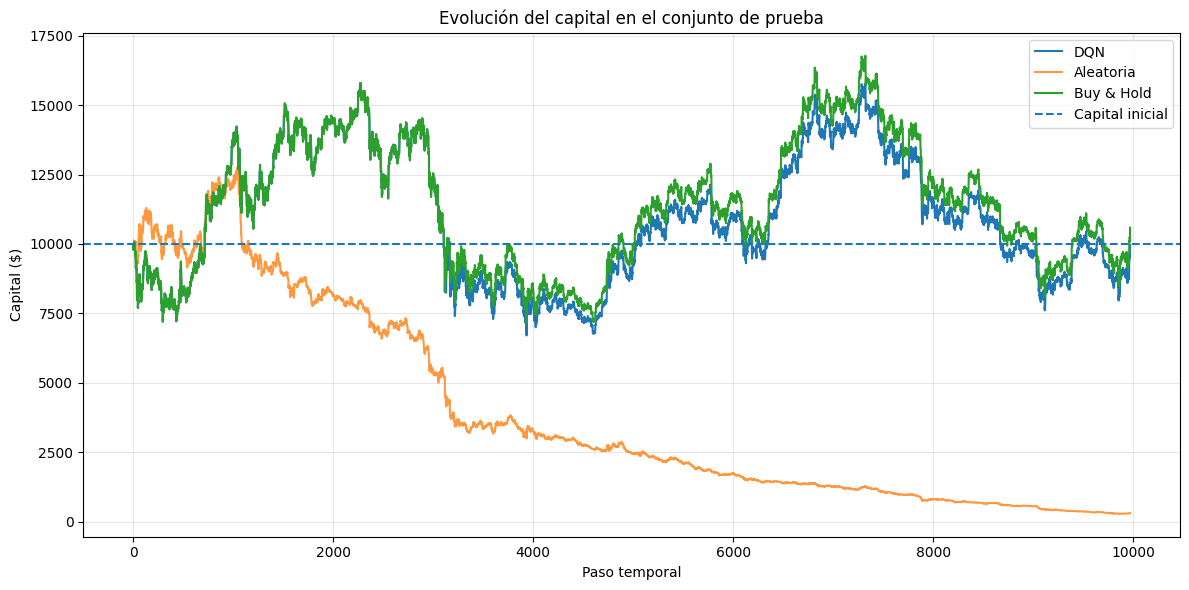

In [ ]:
# Evolución del capital en el conjunto de prueba

import matplotlib.pyplot as plt

def obtener_historial_capital(datos, estrategia, semilla=42):
    env_eval = EntornoInversionBTC(
        datos=datos,
        capital_inicial=10000,
        costo_transaccion=0.001
    )

    estado, info = env_eval.reset(seed=semilla)
    historial = [info["capital"]]
    rng = random.Random(semilla)

    terminado = False
    truncado = False

    while not (terminado or truncado):
        posicion = int(estado[-1])

        if estrategia == "DQN":
            accion = seleccionar_accion(estado, epsilon=0.0)
        elif estrategia == "Aleatoria":
            accion = rng.randrange(env_eval.action_space.n)
        elif estrategia == "Buy & Hold":
            accion = 2 if env_eval.indice == 0 else 0
        else:
            raise ValueError("Estrategia desconocida")

        estado, recompensa, terminado, truncado, info = env_eval.step(accion)
        historial.append(info["capital"])

    return np.array(historial)


historial_dqn = obtener_historial_capital(df_test, "DQN")
historial_aleatoria = obtener_historial_capital(df_test, "Aleatoria")
historial_buy_hold = obtener_historial_capital(df_test, "Buy & Hold")

plt.figure(figsize=(12, 6))
plt.plot(historial_dqn, label="DQN")
plt.plot(historial_aleatoria, label="Aleatoria", alpha=0.8)
plt.plot(historial_buy_hold, label="Buy & Hold")

plt.axhline(10000, linestyle="--", label="Capital inicial")
plt.title("Evolución del capital en el conjunto de prueba")
plt.xlabel("Paso temporal")
plt.ylabel("Capital ($)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

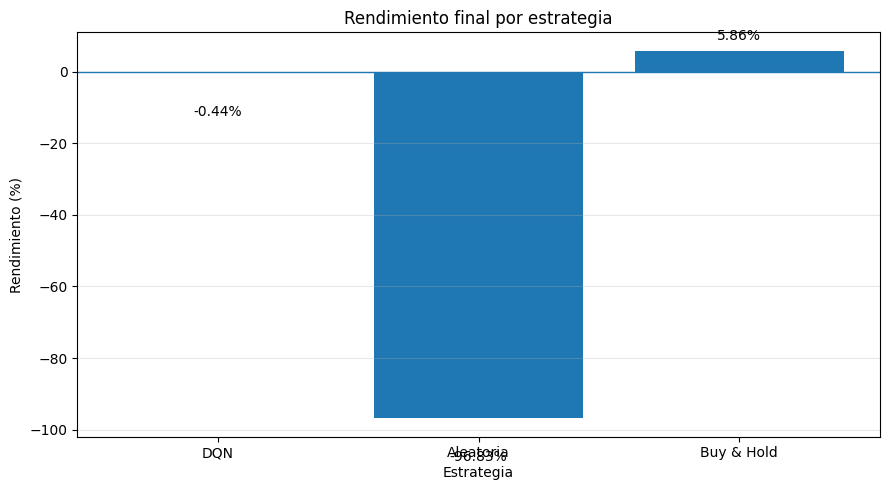

Capital final DQN: 9956.18
Capital final Aleatoria: 317.0
Capital final Buy & Hold: 10585.82


In [ ]:
# Comparación del rendimiento final por estrategia

nombres = ["DQN", "Aleatoria", "Buy & Hold"]
capitales_finales = [
    historial_dqn[-1],
    historial_aleatoria[-1],
    historial_buy_hold[-1]
]

rendimientos = [
    (capital / 10000 - 1) * 100
    for capital in capitales_finales
]

plt.figure(figsize=(9, 5))
barras = plt.bar(nombres, rendimientos)
plt.axhline(0, linewidth=1)
plt.title("Rendimiento final por estrategia")
plt.xlabel("Estrategia")
plt.ylabel("Rendimiento (%)")
plt.grid(axis="y", alpha=0.3)

for barra, valor in zip(barras, rendimientos):
    altura = barra.get_height()
    desplazamiento = 3 if altura >= 0 else -12
    plt.text(
        barra.get_x() + barra.get_width() / 2,
        altura + desplazamiento,
        f"{valor:.2f}%",
        ha="center"
    )

plt.tight_layout()
plt.show()

print("Capital final DQN:", round(historial_dqn[-1], 2))
print("Capital final Aleatoria:", round(historial_aleatoria[-1], 2))
print("Capital final Buy & Hold:", round(historial_buy_hold[-1], 2))

### 17.11. Interpretación de los resultados gráficos

**1. Evolución del capital**

La gráfica de evolución del capital muestra diferencias importantes entre las tres estrategias de inversión. La estrategia DQN presenta fluctuaciones en el valor de la cartera y sigue una trayectoria relativamente cercana a la estrategia Buy & Hold durante varios segmentos del periodo evaluado. Sin embargo, finaliza con un capital de $9.956,18, inferior al capital inicial de $10.000.

La estrategia aleatoria presenta una disminución progresiva del capital, hasta alcanzar un valor final de $317,00. Este comportamiento es consistente con la elevada frecuencia de operaciones observada, que puede incrementar el efecto acumulado de los costos de transacción.

Por su parte, Buy & Hold presenta fluctuaciones significativas, pero alcanza un capital final de $10.585,82. Esto indica que mantener la inversión en Bitcoin durante el periodo evaluado produjo un resultado económico superior al de las otras dos estrategias.

**2. Comparación del rendimiento final**

La gráfica de rendimientos muestra que DQN obtuvo un rendimiento de -0,44 %, mientras que la estrategia aleatoria registró -96,83 %. En contraste, Buy & Hold alcanzó un rendimiento positivo de 5,86 %.

Estos resultados indican que, en el periodo de prueba, DQN tuvo un desempeño considerablemente mejor que la estrategia aleatoria, pero no logró superar la estrategia de comprar y mantener Bitcoin. Por tanto, aunque el agente muestra un comportamiento menos desfavorable que la selección aleatoria de acciones, los resultados no evidencian todavía una ventaja económica frente a la estrategia de referencia Buy & Hold.

**3. Análisis general**

En conjunto, las gráficas permiten observar que la frecuencia de operación, las variaciones del precio y los costos de transacción son factores relevantes para el resultado de una estrategia de inversión. La estrategia aleatoria evidencia el efecto potencialmente desfavorable de realizar numerosas operaciones sin una política consistente, mientras que Buy & Hold obtiene un resultado positivo en el periodo analizado.

El agente DQN, entrenado inicialmente durante cinco episodios, finaliza cerca del punto de equilibrio. No obstante, este resultado debe interpretarse con cautela, ya que el número de episodios es limitado y no permite establecer si el agente ha aprendido una política generalizable.

Por consiguiente, se considera necesario continuar evaluando el entrenamiento y analizar métricas adicionales de riesgo, como el *drawdown* máximo, antes de determinar si el agente ofrece ventajas frente a las estrategias de referencia.

### 17.12. Análisis del riesgo mediante el drawdown

El drawdown mide la disminución porcentual del capital respecto al máximo acumulado alcanzado previamente. El drawdown máximo representa la mayor caída observada durante el periodo evaluado y permite complementar el análisis del rendimiento final con una medida del riesgo experimentado por cada estrategia.

Se calculará esta métrica para DQN, la estrategia aleatoria y Buy & Hold utilizando las trayectorias de capital obtenidas en el conjunto de prueba. También se representará su evolución mediante una gráfica comparativa para identificar los periodos de mayores caídas.

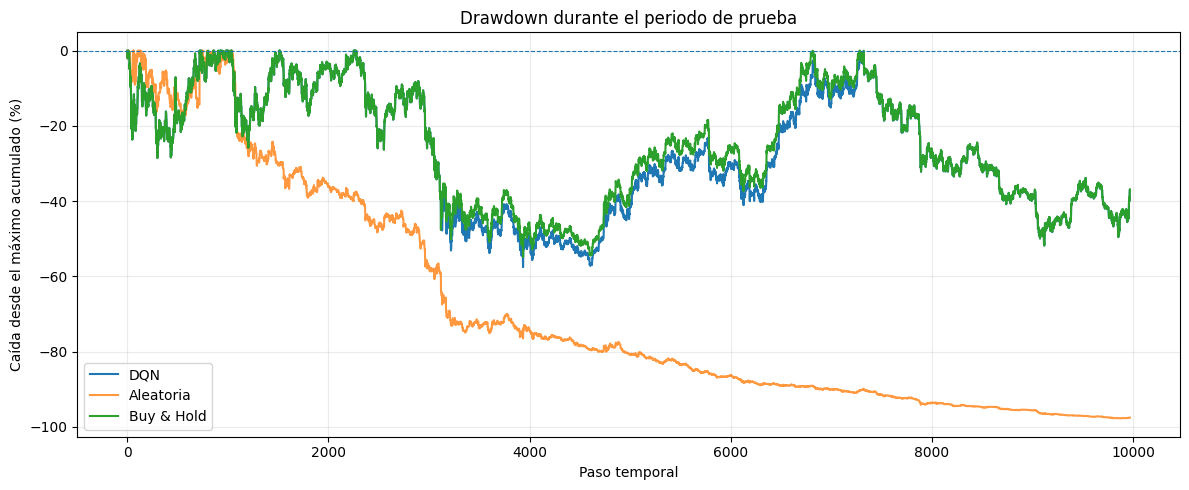

RESUMEN DEL RIESGO
---------------------------------------------
DQN: drawdown máximo = -57.51%
Aleatoria: drawdown máximo = -97.71%
Buy & Hold: drawdown máximo = -54.83%


In [ ]:
# Análisis de drawdown para las tres estrategias

def calcular_drawdown(historial):
    maximo_acumulado = np.maximum.accumulate(historial)
    return (historial / maximo_acumulado - 1) * 100


drawdown_dqn = calcular_drawdown(historial_dqn)
drawdown_aleatoria = calcular_drawdown(historial_aleatoria)
drawdown_buy_hold = calcular_drawdown(historial_buy_hold)

# Gráfica comparativa
plt.figure(figsize=(12, 5))

plt.plot(drawdown_dqn, label="DQN")
plt.plot(drawdown_aleatoria, label="Aleatoria", alpha=0.8)
plt.plot(drawdown_buy_hold, label="Buy & Hold")

plt.title("Drawdown durante el periodo de prueba")
plt.xlabel("Paso temporal")
plt.ylabel("Caída desde el máximo acumulado (%)")
plt.axhline(0, linestyle="--", linewidth=0.8)
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

# Resumen numérico
print("RESUMEN DEL RIESGO")
print("-" * 45)

for nombre, serie in [
    ("DQN", drawdown_dqn),
    ("Aleatoria", drawdown_aleatoria),
    ("Buy & Hold", drawdown_buy_hold)
]:
    print(f"{nombre}: drawdown máximo = {serie.min():.2f}%")

### 17.13. Interpretación del riesgo y del drawdown máximo

La gráfica de drawdown permite comparar las caídas del capital respecto a los máximos acumulados de cada estrategia durante el periodo de prueba. La estrategia DQN registró un drawdown máximo de -57,51 %, mientras que la estrategia aleatoria alcanzó -97,71 % y Buy & Hold presentó -54,83 %.

La estrategia aleatoria experimentó la mayor caída, consistente con su resultado final desfavorable y su elevada frecuencia de operaciones. Por su parte, DQN mostró una caída máxima ligeramente superior a la de Buy & Hold, pese a finalizar con un rendimiento cercano al punto de equilibrio.

Estos resultados evidencian que el rendimiento final no es suficiente para evaluar una estrategia de inversión, ya que también es necesario considerar las pérdidas experimentadas durante el recorrido. En este experimento, Buy & Hold obtuvo tanto el mayor rendimiento final como el menor drawdown máximo entre las tres estrategias.

En consecuencia, aunque el DQN superó a la estrategia aleatoria en rendimiento final, todavía no demostró una ventaja frente a Buy & Hold en términos de rentabilidad o caída máxima. Los resultados deben interpretarse como preliminares, considerando que el agente fue entrenado durante cinco episodios.

## 18. Diagnóstico y mejora del agente DQN

### 18.1. Diagnóstico del comportamiento del agente

Con el propósito de identificar oportunidades de mejora en el agente DQN, se analizó su comportamiento sobre el conjunto de prueba. El diagnóstico incluyó la frecuencia de las acciones seleccionadas, el número de compras y ventas efectivamente ejecutadas, la evolución del capital y el drawdown máximo.

Este análisis permite identificar posibles patrones de operación, permanencia en posiciones y caídas significativas del capital. Los resultados se utilizarán como referencia para orientar los ajustes posteriores del entrenamiento y comparar el desempeño del agente antes y después de las modificaciones.

DIAGNÓSTICO DEL AGENTE DQN
Acciones de mantener: 0
Acciones de vender: 1
Acciones de comprar: 9969
Compras efectivas: 2
Ventas efectivas: 1
Capital inicial: $10,000.00
Capital final: $9,956.18
Rendimiento: -0.44%
Recompensa acumulada: -0.0044
Drawdown máximo: -57.51%


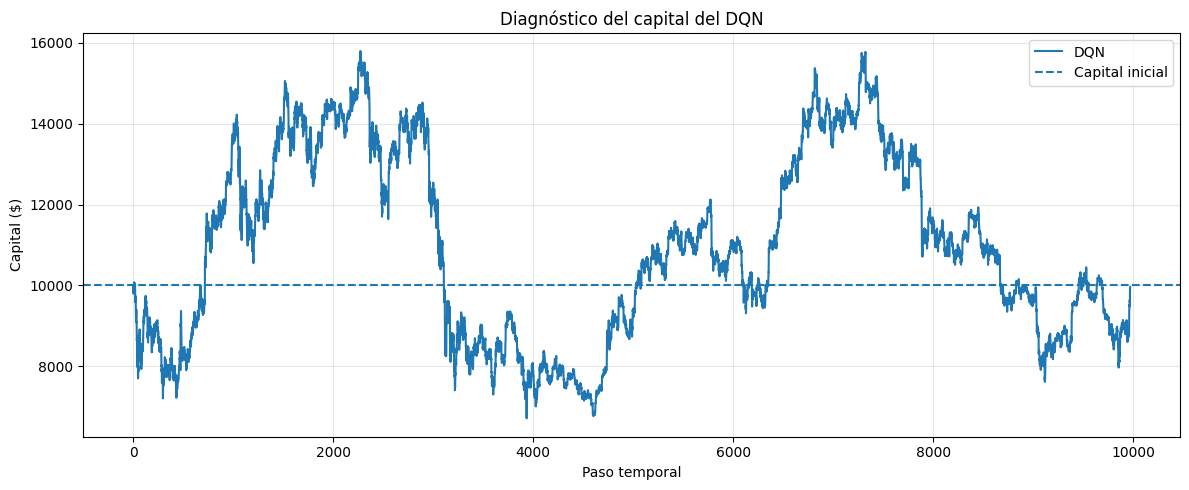

In [ ]:
# 18.1. Diagnóstico del comportamiento del agente DQN

def diagnosticar_dqn(datos, semilla=42):
    env = EntornoInversionBTC(
        datos=datos,
        capital_inicial=10000,
        costo_transaccion=0.001
    )

    estado, info = env.reset(seed=semilla)

    historial_capital = [info["capital"]]
    conteo_acciones = {0: 0, 1: 0, 2: 0}
    compras = 0
    ventas = 0
    recompensa_acumulada = 0.0

    terminado = False
    truncado = False

    while not (terminado or truncado):
        posicion_anterior = int(estado[-1])

        # Evaluar la política aprendida, sin exploración aleatoria
        accion = seleccionar_accion(estado, epsilon=0.0)
        conteo_acciones[accion] += 1

        # Contabilizar únicamente operaciones efectivas
        if accion == 2 and posicion_anterior == 0:
            compras += 1
        elif accion == 1 and posicion_anterior == 1:
            ventas += 1

        estado, recompensa, terminado, truncado, info = env.step(accion)

        recompensa_acumulada += recompensa
        historial_capital.append(info["capital"])

    historial_capital = np.array(historial_capital)

    maximos_acumulados = np.maximum.accumulate(historial_capital)
    drawdown = (historial_capital / maximos_acumulados - 1) * 100

    rendimiento = (
        historial_capital[-1] / historial_capital[0] - 1
    ) * 100

    print("DIAGNÓSTICO DEL AGENTE DQN")
    print("=" * 45)
    print("Acciones de mantener:", conteo_acciones[0])
    print("Acciones de vender:", conteo_acciones[1])
    print("Acciones de comprar:", conteo_acciones[2])
    print("Compras efectivas:", compras)
    print("Ventas efectivas:", ventas)
    print(f"Capital inicial: ${historial_capital[0]:,.2f}")
    print(f"Capital final: ${historial_capital[-1]:,.2f}")
    print(f"Rendimiento: {rendimiento:.2f}%")
    print(f"Recompensa acumulada: {recompensa_acumulada:.4f}")
    print(f"Drawdown máximo: {drawdown.min():.2f}%")

    # Gráfica de evolución del capital
    plt.figure(figsize=(12, 5))
    plt.plot(historial_capital, label="DQN")
    plt.axhline(
        historial_capital[0],
        linestyle="--",
        label="Capital inicial"
    )
    plt.title("Diagnóstico del capital del DQN")
    plt.xlabel("Paso temporal")
    plt.ylabel("Capital ($)")
    plt.legend()
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

    return historial_capital, conteo_acciones


# Ejecutar el diagnóstico con el conjunto de prueba
historial_diagnostico, acciones_diagnostico = diagnosticar_dqn(
    df_test,
    semilla=42
)

### 18.2. Resultados del diagnóstico

El agente DQN seleccionó la acción de compra en 9.969 pasos, la acción de venta en un paso y la acción de mantener en ninguno. Sin embargo, debido a las restricciones del entorno, solo ejecutó dos compras y una venta efectivas.

El capital final fue de $9.956,18, correspondiente a un rendimiento de -0,44 %. El drawdown máximo alcanzó -57,51 %, lo que evidencia que la cartera experimentó caídas importantes durante el periodo de evaluación, a pesar de terminar cerca del capital inicial.

Estos resultados sugieren que la política aprendida presenta una marcada preferencia por la acción de compra y no diferencia suficientemente entre las condiciones del mercado para seleccionar las acciones. Por ello, se requiere revisar la respuesta de la red neuronal antes de modificar el entrenamiento.

In [ ]:
# 18.3. Revisar los valores Q de la red en distintos estados

env_revision = EntornoInversionBTC(
    datos=df_test,
    capital_inicial=10000,
    costo_transaccion=0.001
)

estado, info = env_revision.reset(seed=SEED)

indices = np.linspace(
    0, len(df_test) - 1, 10, dtype=int
)

print("VALORES Q EN DIFERENTES MOMENTOS DEL MERCADO")
print("-" * 75)
print(f"{'Índice':>8} {'Mantener':>12} {'Vender':>12} {'Comprar':>12} {'Acción':>12}")

for indice in indices:
    fila = df_test.iloc[indice]

    estado_revision = np.array([
        fila["return_24h"],
        fila["price_vs_sma_24h"],
        fila["volatility_24h"],
        0.0
    ], dtype=np.float32)

    tensor_estado = torch.tensor(
        estado_revision,
        dtype=torch.float32,
        device=device
    ).unsqueeze(0)

    with torch.no_grad():
        valores = red_dqn(tensor_estado).cpu().numpy()[0]

    accion = int(np.argmax(valores))

    nombres = ["Mantener", "Vender", "Comprar"]

    print(
        f"{indice:>8} "
        f"{valores[0]:>12.4f} "
        f"{valores[1]:>12.4f} "
        f"{valores[2]:>12.4f} "
        f"{nombres[accion]:>12}"
    )

VALORES Q EN DIFERENTES MOMENTOS DEL MERCADO
---------------------------------------------------------------------------
  Índice     Mantener       Vender      Comprar       Acción
       0       0.0497       0.0486       0.0512      Comprar
    1107       0.0497       0.0486       0.0512      Comprar
    2215       0.0497       0.0486       0.0512      Comprar
    3323       0.0497       0.0486       0.0512      Comprar
    4431       0.0497       0.0486       0.0512      Comprar
    5538       0.0497       0.0486       0.0512      Comprar
    6646       0.0497       0.0486       0.0512      Comprar
    7754       0.0497       0.0486       0.0512      Comprar
    8862       0.0497       0.0486       0.0512      Comprar
    9970       0.0497       0.0486       0.0512      Comprar


### 18.3. Análisis de los valores Q

Se evaluaron los valores Q estimados por la red neuronal en diferentes momentos del conjunto de prueba y considerando las dos posiciones posibles de la cartera: efectivo y Bitcoin.

Los resultados mostraron que los valores Q de mantener, vender y comprar permanecieron constantes en las observaciones evaluadas. La acción de compra obtuvo el mayor valor estimado, por lo que fue seleccionada de manera sistemática.

Este comportamiento indica que la red no está reflejando las diferencias entre los estados evaluados en sus valores Q. Se requiere profundizar en el diagnóstico para determinar si el comportamiento se relaciona con las activaciones de las capas, la configuración del entrenamiento o el aprendizaje de una política poco sensible a las entradas.

In [ ]:
# 18.4. Sensibilidad de los valores Q a los estados del mercado

indices = np.linspace(0, len(df_test) - 1, 10, dtype=int)
resultados_q = []

red_dqn.eval()

with torch.no_grad():
    for indice in indices:
        fila = df_test.iloc[indice]

        for posicion in [0.0, 1.0]:
            estado_revision = np.array([
                fila["return_24h"],
                fila["price_vs_sma_24h"],
                fila["volatility_24h"],
                posicion
            ], dtype=np.float32)

            tensor_estado = torch.tensor(
                estado_revision,
                dtype=torch.float32,
                device=device
            ).unsqueeze(0)

            valores_q = red_dqn(tensor_estado).cpu().numpy()[0]

            resultados_q.append({
                "indice": indice,
                "posicion": "Efectivo" if posicion == 0 else "Bitcoin",
                "Q_mantener": valores_q[0],
                "Q_vender": valores_q[1],
                "Q_comprar": valores_q[2],
                "accion": ["Mantener", "Vender", "Comprar"][np.argmax(valores_q)]
            })

df_q = pd.DataFrame(resultados_q)

display(df_q.round(8))

print("\nVARIACIÓN DE LOS VALORES Q")
for columna in ["Q_mantener", "Q_vender", "Q_comprar"]:
    print(
        f"{columna}: mínimo={df_q[columna].min():.10f}, "
        f"máximo={df_q[columna].max():.10f}, "
        f"rango={df_q[columna].max() - df_q[columna].min():.10f}"
    )

,indice,posicion,Q_mantener,Q_vender,Q_comprar,accion
0,0,Efectivo,0.049749,0.048627,0.05122,Comprar
1,0,Bitcoin,0.049749,0.048627,0.05122,Comprar
2,1107,Efectivo,0.049749,0.048627,0.05122,Comprar
3,1107,Bitcoin,0.049749,0.048627,0.05122,Comprar
4,2215,Efectivo,0.049749,0.048627,0.05122,Comprar
5,2215,Bitcoin,0.049749,0.048627,0.05122,Comprar
6,3323,Efectivo,0.049749,0.048627,0.05122,Comprar
7,3323,Bitcoin,0.049749,0.048627,0.05122,Comprar
8,4431,Efectivo,0.049749,0.048627,0.05122,Comprar
9,4431,Bitcoin,0.049749,0.048627,0.05122,Comprar



VARIACIÓN DE LOS VALORES Q
Q_mantener: mínimo=0.0497494154, máximo=0.0497494154, rango=0.0000000000
Q_vender: mínimo=0.0486273244, máximo=0.0486273244, rango=0.0000000000
Q_comprar: mínimo=0.0512198620, máximo=0.0512198620, rango=0.0000000000


### 18.4. Verificación de las entradas y salidas de la red

Se comprobó que las variables de entrada presentan variaciones entre las observaciones del mercado y que la posición de la cartera puede tomar los valores correspondientes a efectivo y Bitcoin. Sin embargo, las salidas de la red neuronal permanecieron idénticas para todos los estados evaluados.

La desviación estándar de los parámetros de la red fue distinta de cero, por lo que los pesos no son constantes. No obstante, esta característica por sí sola no demuestra que la red haya aprendido una política adecuada.

Por consiguiente, se continuará con el análisis de las activaciones neuronales para identificar dónde se produce la falta de variación en las salidas y definir los ajustes necesarios antes de realizar un nuevo entrenamiento.

### 18.5. Diagnóstico de las activaciones neuronales

Debido a que la red neuronal produjo los mismos valores Q para diferentes estados del mercado, se analizarán las activaciones de sus capas ocultas. El objetivo es determinar si las neuronas responden a los cambios de las variables de entrada o si sus salidas permanecen constantes.

Esta comprobación permitirá identificar posibles problemas en la propagación de las entradas y orientar los ajustes necesarios antes de realizar un nuevo entrenamiento. Se conservarán los resultados del modelo actual como referencia para comparar los cambios posteriores.

In [ ]:
# 18.5. Diagnóstico de sensibilidad de la red DQN

red_dqn.eval()

estados_prueba = []

for indice in np.linspace(0, len(df_test) - 1, 5, dtype=int):
    fila = df_test.iloc[indice]

    for posicion in [0.0, 1.0]:
        estado = np.array([
            fila["return_24h"],
            fila["price_vs_sma_24h"],
            fila["volatility_24h"],
            posicion
        ], dtype=np.float32)

        estados_prueba.append(estado)

X = np.array(estados_prueba, dtype=np.float32)

with torch.no_grad():
    tensor_X = torch.tensor(X, dtype=torch.float32, device=device)
    salidas = red_dqn(tensor_X).cpu().numpy()

print("ENTRADAS DE LA RED")
print("-" * 70)
print(pd.DataFrame(
    X,
    columns=[
        "return_24h",
        "price_vs_sma_24h",
        "volatility_24h",
        "posicion"
    ]
).round(6).to_string(index=False))

print("\nSALIDAS Q")
print("-" * 70)
print(pd.DataFrame(
    salidas,
    columns=["Q_mantener", "Q_vender", "Q_comprar"]
).to_string(index=False, float_format=lambda x: f"{x:.10f}"))

print("\nVARIACIÓN ENTRE ENTRADAS")
print("Rango de cada variable:", np.ptp(X, axis=0))

print("\nVARIACIÓN ENTRE SALIDAS Q")
print("Rango de cada salida:", np.ptp(salidas, axis=0))

print("\nVARIACIÓN DE LOS PESOS")
for nombre, parametro in red_dqn.named_parameters():
    print(
        f"{nombre}: desviación estándar = "
        f"{parametro.detach().cpu().std().item():.10f}"
    )

ENTRADAS DE LA RED
----------------------------------------------------------------------
 return_24h  price_vs_sma_24h  volatility_24h  posicion
  -0.015609          0.013719        0.013976       0.0
  -0.015609          0.013719        0.013976       1.0
  -0.081629         -0.041846        0.014417       0.0
  -0.081629         -0.041846        0.014417       1.0
   0.028102         -0.007624        0.005169       0.0
   0.028102         -0.007624        0.005169       1.0
  -0.031007         -0.021448        0.006606       0.0
  -0.031007         -0.021448        0.006606       1.0
   0.152806          0.089749        0.012660       0.0
   0.152806          0.089749        0.012660       1.0

SALIDAS Q
----------------------------------------------------------------------
  Q_mantener     Q_vender    Q_comprar
0.0497494154 0.0486273244 0.0512198620
0.0497494154 0.0486273244 0.0512198620
0.0497494154 0.0486273244 0.0512198620
0.0497494154 0.0486273244 0.0512198620
0.0497494154 0.04

### 18.5.1. Resultados del diagnóstico de sensibilidad

La prueba de sensibilidad mostró que las variables de entrada presentan variaciones entre los estados evaluados. El rango de `return_24h` fue de 0,2344, el de `price_vs_sma_24h` fue de 0,1316 y el de `volatility_24h` fue de 0,0092. Asimismo, la posición de la cartera varió entre efectivo y Bitcoin.

Sin embargo, los valores Q de las tres acciones permanecieron constantes en todas las observaciones, con un rango de variación igual a cero. Esto indica que, para los estados evaluados, la red neuronal no refleja los cambios de las entradas en sus salidas.

Aunque los parámetros de la red presentan variabilidad, este resultado no garantiza que se haya aprendido una política útil. Por tanto, es necesario analizar las activaciones de las capas ocultas para identificar dónde se pierde la sensibilidad a los estados del mercado.

In [ ]:
# 18.6. Diagnóstico de las activaciones neuronales

red_dqn.eval()

# Construir estados de diagnóstico usando datos de prueba
estados = []

for indice in np.linspace(0, len(df_test) - 1, 10, dtype=int):
    fila = df_test.iloc[indice]

    for posicion in [0.0, 1.0]:
        estados.append([
            fila["return_24h"],
            fila["price_vs_sma_24h"],
            fila["volatility_24h"],
            posicion
        ])

X_diagnostico = torch.tensor(
    np.array(estados, dtype=np.float32),
    device=device
)

# Revisar activaciones de cada capa
activacion = X_diagnostico

print("DIAGNÓSTICO DE ACTIVACIONES")
print("=" * 60)

with torch.no_grad():
    for nombre, capa in red_dqn.red.named_children():
        activacion = capa(activacion)
        valores = activacion.cpu().numpy()

        print(f"\nCapa {nombre}: {capa.__class__.__name__}")
        print("Forma:", valores.shape)
        print(f"Mínimo: {valores.min():.10f}")
        print(f"Máximo: {valores.max():.10f}")
        print(f"Desviación estándar: {valores.std():.10f}")
        print(
            "Variación máxima entre estados:",
            f"{np.ptp(valores, axis=0).max():.10f}"
        )

DIAGNÓSTICO DE ACTIVACIONES

Capa 0: Linear
Forma: (20, 64)
Mínimo: -1.0231664181
Máximo: 0.9789106846
Desviación estándar: 0.3455697000
Variación máxima entre estados: 0.9542402625

Capa 1: ReLU
Forma: (20, 64)
Mínimo: 0.0000000000
Máximo: 0.9789106846
Desviación estándar: 0.1739886999
Variación máxima entre estados: 0.5722281337

Capa 2: Linear
Forma: (20, 64)
Mínimo: -5.2760119438
Máximo: -0.0236258600
Desviación estándar: 0.9318620563
Variación máxima entre estados: 2.1949856281

Capa 3: ReLU
Forma: (20, 64)
Mínimo: 0.0000000000
Máximo: 0.0000000000
Desviación estándar: 0.0000000000
Variación máxima entre estados: 0.0000000000

Capa 4: Linear
Forma: (20, 3)
Mínimo: 0.0486273244
Máximo: 0.0512198620
Desviación estándar: 0.0010615791
Variación máxima entre estados: 0.0000000000


### 18.6.1. Interpretación de las activaciones neuronales

El análisis de las activaciones permitió identificar el origen de la falta de sensibilidad de la red DQN. Mientras que la primera capa lineal y su función ReLU presentan variaciones entre los estados evaluados, la segunda capa lineal genera exclusivamente valores negativos.

Al aplicar la segunda función ReLU, todas las activaciones se convierten en cero. En consecuencia, la capa de salida recibe la misma representación para todos los estados y produce valores Q constantes para las acciones disponibles.

Este comportamiento es compatible con un problema de neuronas ReLU muertas en la segunda capa oculta. Por tanto, aunque la red presenta parámetros distintos de cero, su salida no está respondiendo a las características del mercado evaluadas. Este hallazgo justifica revisar el entrenamiento y considerar ajustes en la arquitectura o en la preparación de las variables de entrada antes de realizar una nueva evaluación.

### 18.7. Evolución del entrenamiento del agente DQN

Con el propósito de complementar el diagnóstico de las activaciones, se analizará la evolución del entrenamiento mediante las recompensas obtenidas por episodio y el capital final de la cartera. Esto permitirá identificar si el agente muestra señales de aprendizaje y si su desempeño mejora a medida que interactúa con el entorno.

In [ ]:
# 18.7. Evolución del entrenamiento del agente DQN

import matplotlib.pyplot as plt

print("Columnas disponibles en el historial:")
print(historial_entrenamiento[0].keys())

print("\nPrimer registro del entrenamiento:")
print(historial_entrenamiento[0])

Columnas disponibles en el historial:
dict_keys(['episodio', 'recompensa', 'capital_final', 'epsilon'])

Primer registro del entrenamiento:
{'episodio': 1, 'recompensa': -6.280022563160633, 'capital_final': 18.733583248613034, 'epsilon': 0.995}


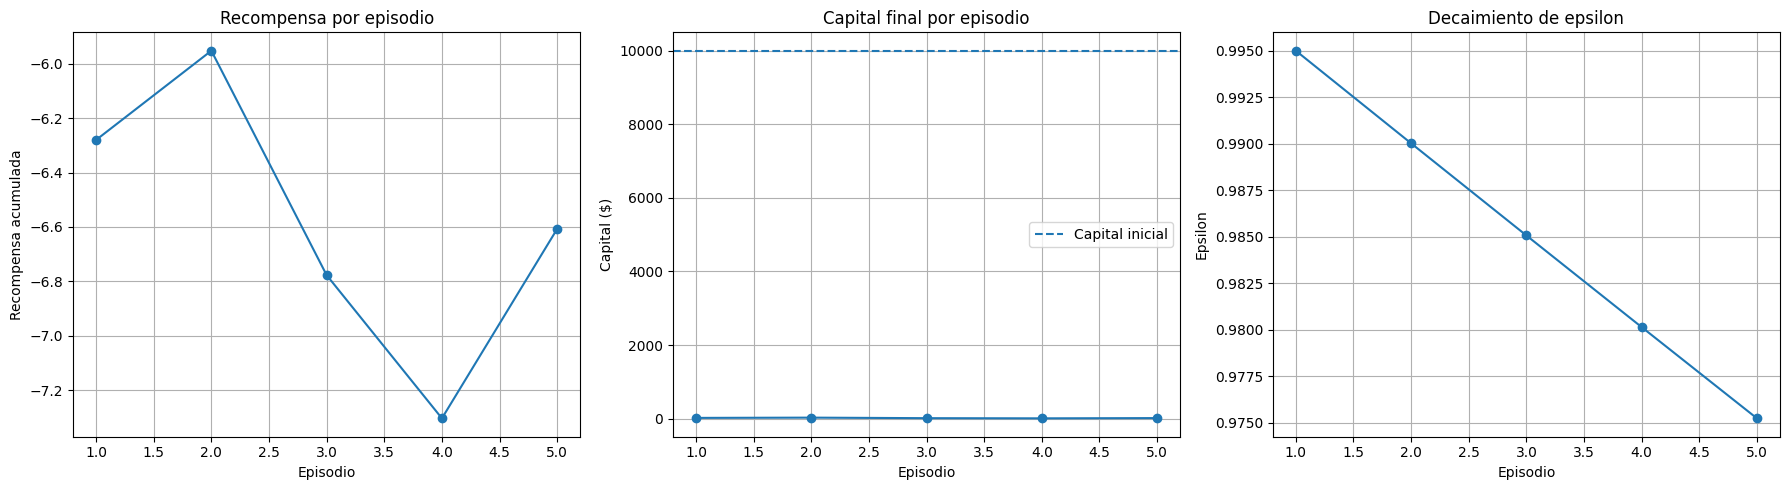

In [ ]:
# 18.7.1. Evolución de las recompensas y el capital

import matplotlib.pyplot as plt

episodios = [registro["episodio"] for registro in historial_entrenamiento]
recompensas = [registro["recompensa"] for registro in historial_entrenamiento]
capitales = [registro["capital_final"] for registro in historial_entrenamiento]
epsilons = [registro["epsilon"] for registro in historial_entrenamiento]

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Recompensa por episodio
axes[0].plot(episodios, recompensas, marker="o")
axes[0].set_title("Recompensa por episodio")
axes[0].set_xlabel("Episodio")
axes[0].set_ylabel("Recompensa acumulada")
axes[0].grid(True)

# Capital final
axes[1].plot(episodios, capitales, marker="o")
axes[1].axhline(10000, linestyle="--", label="Capital inicial")
axes[1].set_title("Capital final por episodio")
axes[1].set_xlabel("Episodio")
axes[1].set_ylabel("Capital ($)")
axes[1].legend()
axes[1].grid(True)

# Epsilon
axes[2].plot(episodios, epsilons, marker="o")
axes[2].set_title("Decaimiento de epsilon")
axes[2].set_xlabel("Episodio")
axes[2].set_ylabel("Epsilon")
axes[2].grid(True)

plt.tight_layout()
plt.show()

In [ ]:
# 18.7.2. Resumen numérico

print("RESUMEN DEL ENTRENAMIENTO DQN")
print("=" * 45)
print(f"Episodios entrenados: {len(historial_entrenamiento)}")
print(f"Recompensa promedio: {sum(recompensas)/len(recompensas):.4f}")
print(f"Mejor recompensa: {max(recompensas):.4f}")
print(f"Peor recompensa: {min(recompensas):.4f}")
print(f"Capital final promedio: ${sum(capitales)/len(capitales):,.2f}")
print(f"Capital final máximo: ${max(capitales):,.2f}")
print(f"Capital final mínimo: ${min(capitales):,.2f}")
print(f"Epsilon inicial: {epsilons[0]:.4f}")
print(f"Epsilon final: {epsilons[-1]:.4f}")

RESUMEN DEL ENTRENAMIENTO DQN
Episodios entrenados: 5
Recompensa promedio: -6.5839
Mejor recompensa: -5.9520
Peor recompensa: -7.3034
Capital final promedio: $15.28
Capital final máximo: $26.01
Capital final mínimo: $6.73
Epsilon inicial: 0.9950
Epsilon final: 0.9752


### 18.7.4. Interpretación de los resultados del entrenamiento

El entrenamiento experimental del agente DQN se realizó durante cinco episodios. La recompensa promedio fue de -6,5839, con una mejor recompensa de -5,9520 y una peor de -7,3034. Estos resultados muestran que las recompensas fueron negativas durante todos los episodios y que no se observa una mejora sostenida en el desempeño.

El capital final promedio fue de $15,28, frente a un capital inicial de $10.000. Este resultado evidencia una pérdida considerable del capital durante los episodios de entrenamiento. Por su parte, epsilon disminuyó de 0,9950 a 0,9752, lo que refleja una reducción gradual de la exploración.

No obstante, cinco episodios son insuficientes para concluir si el algoritmo puede converger. Los resultados deben interpretarse como un diagnóstico preliminar, especialmente porque el análisis de las activaciones mostró que la segunda capa ReLU produce únicamente ceros. Se requiere corregir este comportamiento y repetir el entrenamiento antes de evaluar la capacidad real del agente para desarrollar una estrategia de inversión.

### 18.8. Verificación de la implementación del entrenamiento

Antes de ajustar la arquitectura de la red neuronal, se revisará el procedimiento de entrenamiento para verificar la actualización de los parámetros, la selección de acciones, el cálculo de las recompensas y la evolución de la cartera. Esta comprobación permitirá distinguir entre un problema de aprendizaje de la red y un posible problema en la implementación del entorno o del algoritmo.

In [ ]:
# 18.8.1. Inspección de la arquitectura y los parámetros DQN

print("ARQUITECTURA DE LA RED DQN")
print("=" * 50)
print(red_dqn)

print("\nPARÁMETROS DE CADA CAPA")
for nombre, parametro in red_dqn.named_parameters():
    print(
        f"{nombre}: "
        f"forma={tuple(parametro.shape)}, "
        f"media={parametro.data.mean().item():.6f}, "
        f"desviación={parametro.data.std().item():.6f}"
    )

print("\nCONFIGURACIÓN DE ENTRENAMIENTO")
print("Tasa de aprendizaje:", TASA_APRENDIZAJE)
print("Factor de descuento:", FACTOR_DESCUENTO)
print("Tamaño del lote:", TAMANO_LOTE)
print("Capacidad de memoria:", CAPACIDAD_MEMORIA)
print("Epsilon mínimo:", EPSILON_MINIMO)
print("Epsilon decay:", EPSILON_DECAY)

ARQUITECTURA DE LA RED DQN
RedDQN(
  (red): Sequential(
    (0): Linear(in_features=4, out_features=64, bias=True)
    (1): ReLU()
    (2): Linear(in_features=64, out_features=64, bias=True)
    (3): ReLU()
    (4): Linear(in_features=64, out_features=3, bias=True)
  )
)

PARÁMETROS DE CADA CAPA
red.0.weight: forma=(64, 4), media=-0.035953, desviación=0.571429
red.0.bias: forma=(64,), media=-0.090637, desviación=0.293346
red.2.weight: forma=(64, 64), media=-0.032012, desviación=0.154938
red.2.bias: forma=(64,), media=-0.079749, desviación=0.086919
red.4.weight: forma=(3, 64), media=0.018818, desviación=0.108939
red.4.bias: forma=(3,), media=0.049866, desviación=0.001300

CONFIGURACIÓN DE ENTRENAMIENTO
Tasa de aprendizaje: 0.001
Factor de descuento: 0.99
Tamaño del lote: 64
Capacidad de memoria: 10000
Epsilon mínimo: 0.05
Epsilon decay: 0.995


### 18.8.2. Análisis de los gradientes de la red DQN

Se revisará el comportamiento de los gradientes asociados a las capas de la red neuronal para determinar si la función de pérdida genera señales de aprendizaje en los parámetros. Este análisis permitirá complementar el diagnóstico de las activaciones y establecer si las unidades de la segunda capa oculta están recibiendo gradientes durante la optimización.

In [ ]:
# 18.8.2. Inspección de gradientes actuales

print("DIAGNÓSTICO DE GRADIENTES")
print("=" * 55)

for nombre, parametro in red_dqn.named_parameters():
    if parametro.grad is None:
        print(f"{nombre}: gradiente = None")
    else:
        gradiente = parametro.grad.detach()
        print(
            f"{nombre}: "
            f"media absoluta = {gradiente.abs().mean().item():.10f} | "
            f"máximo absoluto = {gradiente.abs().max().item():.10f}"
        )

DIAGNÓSTICO DE GRADIENTES
red.0.weight: media absoluta = 0.0000000000 | máximo absoluto = 0.0000000000
red.0.bias: media absoluta = 0.0000000000 | máximo absoluto = 0.0000000000
red.2.weight: media absoluta = 0.0000000000 | máximo absoluto = 0.0000000000
red.2.bias: media absoluta = 0.0000000000 | máximo absoluto = 0.0000000000
red.4.weight: media absoluta = 0.0000000000 | máximo absoluto = 0.0000000000
red.4.bias: media absoluta = 0.0010849728 | máximo absoluto = 0.0023402753


### 18.8.3. Prueba controlada de actualización de parámetros

Se realizará una prueba controlada con un lote de estados de entrenamiento para comprobar si el cálculo de la pérdida genera gradientes en las capas ocultas y si el optimizador modifica sus parámetros. La prueba permitirá verificar el mecanismo de aprendizaje sin ejecutar nuevamente episodios completos.

La evaluación se realizará sobre una copia de la red, de manera que los parámetros del agente principal no se alteren durante el diagnóstico.

In [ ]:
# 18.8.3. Prueba controlada de gradientes y actualización

import copy
import torch
import torch.nn as nn

# Copia independiente de la red
red_prueba = copy.deepcopy(red_dqn)
red_prueba.train()

# Crear un lote con estados variados del conjunto de entrenamiento
estados_prueba = []

for indice in np.linspace(0, len(df_train) - 1, 64, dtype=int):
    fila = df_train.iloc[indice]

    for posicion in [0.0, 1.0]:
        estados_prueba.append([
            fila["return_24h"],
            fila["price_vs_sma_24h"],
            fila["volatility_24h"],
            posicion
        ])

# Seleccionar 64 estados
X_prueba = torch.tensor(
    np.array(estados_prueba[:64], dtype=np.float32),
    device=device
)

# Objetivos de prueba distintos para comprobar la propagación
objetivos_prueba = torch.zeros((64, 3), device=device)
objetivos_prueba[:, 0] = 1.0
objetivos_prueba[:, 1] = -1.0
objetivos_prueba[:, 2] = 0.5

optimizador_prueba = torch.optim.Adam(
    red_prueba.parameters(),
    lr=TASA_APRENDIZAJE
)

perdida_fn = nn.MSELoss()

# Guardar parámetros antes de la actualización
parametros_antes = {
    nombre: parametro.detach().clone()
    for nombre, parametro in red_prueba.named_parameters()
}

optimizador_prueba.zero_grad()

salidas = red_prueba(X_prueba)
perdida = perdida_fn(salidas, objetivos_prueba)
perdida.backward()

print("PÉRDIDA:", round(perdida.item(), 6))
print("\nGRADIENTES POR CAPA")

for nombre, parametro in red_prueba.named_parameters():
    gradiente = parametro.grad

    if gradiente is None:
        print(f"{nombre}: sin gradiente")
    else:
        print(
            f"{nombre}: media absoluta = "
            f"{gradiente.abs().mean().item():.10f}"
        )

# Actualizar únicamente la copia
optimizador_prueba.step()

print("\nCAMBIO DE PARÁMETROS")

for nombre, parametro in red_prueba.named_parameters():
    cambio = (
        parametro.detach() - parametros_antes[nombre]
    ).abs().max().item()

    print(f"{nombre}: cambio máximo = {cambio:.10f}")

PÉRDIDA: 0.734666

GRADIENTES POR CAPA
red.0.weight: media absoluta = 0.0000000000
red.0.bias: media absoluta = 0.0000000000
red.2.weight: media absoluta = 0.0000000000
red.2.bias: media absoluta = 0.0000000000
red.4.weight: media absoluta = 0.0000000000
red.4.bias: media absoluta = 0.5439240336

CAMBIO DE PARÁMETROS
red.0.weight: cambio máximo = 0.0000000000
red.0.bias: cambio máximo = 0.0000000000
red.2.weight: cambio máximo = 0.0000000000
red.2.bias: cambio máximo = 0.0000000000
red.4.weight: cambio máximo = 0.0000000000
red.4.bias: cambio máximo = 0.0009999983


### 18.8.4. Resultados de la prueba controlada

La prueba controlada obtuvo una pérdida de 0,734666. Sin embargo, el análisis de los gradientes mostró que los pesos y sesgos de las dos capas ocultas, así como los pesos de la capa de salida, presentaron gradientes iguales a cero.

En contraste, los sesgos de la capa de salida registraron un gradiente medio absoluto de 0,543924 y un cambio máximo de 0,0009999983 después de la actualización del optimizador.

Estos resultados confirman que, en la condición evaluada, el aprendizaje se limita a los sesgos de salida. La segunda capa ReLU produce activaciones nulas, impidiendo que la señal de error se propague hacia las capas anteriores. Por tanto, la red no está aprendiendo representaciones dependientes de los estados del mercado y requiere un ajuste antes de realizar una nueva evaluación del agente.

### 18.9. Ajuste de la función de activación

A partir del diagnóstico, se propone reemplazar las funciones ReLU por LeakyReLU en las capas ocultas de la red DQN. El objetivo es reducir el riesgo de activaciones permanentemente nulas y favorecer la propagación de gradientes durante el entrenamiento.

El cambio se evaluará mediante una prueba controlada de gradientes antes de iniciar un nuevo entrenamiento completo. De esta manera, se verificará que el ajuste permite actualizar los parámetros de las capas ocultas.

In [ ]:
# 18.9.1. Crear una red de prueba con LeakyReLU

import torch
import torch.nn as nn
import copy

class RedDQNLeaky(nn.Module):
    def __init__(self, entradas=4, salidas=3):
        super().__init__()

        self.red = nn.Sequential(
            nn.Linear(entradas, 64),
            nn.LeakyReLU(negative_slope=0.01),
            nn.Linear(64, 64),
            nn.LeakyReLU(negative_slope=0.01),
            nn.Linear(64, salidas)
        )

    def forward(self, x):
        return self.red(x)


# Crear una red independiente para la prueba
red_prueba_leaky = RedDQNLeaky().to(device)

# Usar el mismo lote de estados de la prueba anterior
optimizador_leaky = torch.optim.Adam(
    red_prueba_leaky.parameters(),
    lr=TASA_APRENDIZAJE
)

perdida_fn = nn.MSELoss()

objetivos_prueba = torch.zeros((64, 3), device=device)
objetivos_prueba[:, 0] = 1.0
objetivos_prueba[:, 1] = -1.0
objetivos_prueba[:, 2] = 0.5

optimizador_leaky.zero_grad()

salidas_leaky = red_prueba_leaky(X_prueba)
perdida_leaky = perdida_fn(salidas_leaky, objetivos_prueba)
perdida_leaky.backward()

print("PÉRDIDA:", round(perdida_leaky.item(), 6))
print("\nGRADIENTES DE LA RED CON LEAKYRELU")

for nombre, parametro in red_prueba_leaky.named_parameters():
    if parametro.grad is None:
        print(f"{nombre}: sin gradiente")
    else:
        print(
            f"{nombre}: gradiente medio absoluto = "
            f"{parametro.grad.abs().mean().item():.10f}"
        )

PÉRDIDA: 0.662071

GRADIENTES DE LA RED CON LEAKYRELU
red.0.weight: gradiente medio absoluto = 0.0015928826
red.0.bias: gradiente medio absoluto = 0.0125954915
red.2.weight: gradiente medio absoluto = 0.0044161361
red.2.bias: gradiente medio absoluto = 0.0256881863
red.4.weight: gradiente medio absoluto = 0.0344753452
red.4.bias: gradiente medio absoluto = 0.5234026313


### 18.9.2. Resultados de la prueba con LeakyReLU

La prueba con la arquitectura modificada presentó gradientes distintos de cero en todas las capas de la red neuronal. En particular, los pesos de la segunda capa oculta registraron un gradiente medio absoluto de 0,004416, mientras que los pesos de la capa de salida presentaron un valor de 0,034475.

A diferencia de la arquitectura original, en la que las activaciones nulas impedían la propagación de gradientes hacia las capas anteriores, la función LeakyReLU permitió que la señal de error alcanzara todos los parámetros evaluados.

Este resultado respalda el uso de LeakyReLU como alternativa para corregir el problema de propagación de gradientes observado. Sin embargo, la prueba se realizó con una red independiente y objetivos artificiales de verificación; por tanto, todavía no demuestra que el agente de inversión vaya a obtener mejores resultados. Será necesario integrar el cambio en el DQN, entrenarlo nuevamente y evaluar su desempeño con los mismos datos de prueba y estrategias de referencia.

In [ ]:
# 18.10.1. Verificación de los objetos del agente

print("RED PRINCIPAL:")
print(red_dqn)

print("\nRED OBJETIVO:")
print(red_objetivo)

print("\nOPTIMIZADOR:")
print(optimizador)

print("\nFUNCIÓN DE APRENDIZAJE:")
print(aprender_dqn)

RED PRINCIPAL:
RedDQN(
  (red): Sequential(
    (0): Linear(in_features=4, out_features=64, bias=True)
    (1): ReLU()
    (2): Linear(in_features=64, out_features=64, bias=True)
    (3): ReLU()
    (4): Linear(in_features=64, out_features=3, bias=True)
  )
)

RED OBJETIVO:
RedDQN(
  (red): Sequential(
    (0): Linear(in_features=4, out_features=64, bias=True)
    (1): ReLU()
    (2): Linear(in_features=64, out_features=64, bias=True)
    (3): ReLU()
    (4): Linear(in_features=64, out_features=3, bias=True)
  )
)

OPTIMIZADOR:
Adam (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: False
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.001
    maximize: False
    weight_decay: 0
)

FUNCIÓN DE APRENDIZAJE:
<function aprender_dqn at 0x7ae5743f7100>


### 18.10. Integración de la arquitectura corregida

Se integrará la función LeakyReLU en las dos capas ocultas de la red DQN, manteniendo el número de neuronas, las tres acciones posibles y los hiperparámetros definidos previamente. Se reconstruirán la red principal, la red objetivo y el optimizador para asegurar que todos los componentes utilicen la misma arquitectura.

Debido al cambio en la función de activación, será necesario entrenar nuevamente el agente. Los resultados anteriores se conservarán como referencia diagnóstica y no se mezclarán con los resultados del nuevo entrenamiento.

In [ ]:
# 18.10.1. Reconstrucción del agente DQN con LeakyReLU

# Red principal
red_dqn = RedDQNLeaky().to(device)

# Red objetivo con la misma arquitectura
red_objetivo = RedDQNLeaky().to(device)
red_objetivo.load_state_dict(red_dqn.state_dict())

# Optimizador nuevo conectado a la red principal
optimizador = torch.optim.Adam(
    red_dqn.parameters(),
    lr=TASA_APRENDIZAJE
)

# Reiniciar la memoria de experiencias
memoria_reproduccion = ReplayBuffer(CAPACIDAD_MEMORIA)

# Reiniciar epsilon
epsilon = EPSILON_INICIAL

# Verificar las arquitecturas
print("RED PRINCIPAL:")
print(red_dqn)

print("\nRED OBJETIVO:")
print(red_objetivo)

print("\n¿Las arquitecturas coinciden?")
print(
    list(red_dqn.state_dict().keys())
    == list(red_objetivo.state_dict().keys())
)

RED PRINCIPAL:
RedDQNLeaky(
  (red): Sequential(
    (0): Linear(in_features=4, out_features=64, bias=True)
    (1): LeakyReLU(negative_slope=0.01)
    (2): Linear(in_features=64, out_features=64, bias=True)
    (3): LeakyReLU(negative_slope=0.01)
    (4): Linear(in_features=64, out_features=3, bias=True)
  )
)

RED OBJETIVO:
RedDQNLeaky(
  (red): Sequential(
    (0): Linear(in_features=4, out_features=64, bias=True)
    (1): LeakyReLU(negative_slope=0.01)
    (2): Linear(in_features=64, out_features=64, bias=True)
    (3): LeakyReLU(negative_slope=0.01)
    (4): Linear(in_features=64, out_features=3, bias=True)
  )
)

¿Las arquitecturas coinciden?
True


### 18.10.2. Verificación de la nueva arquitectura

Se verificó que la red principal y la red objetivo utilizan la misma arquitectura, con dos capas ocultas de 64 neuronas y funciones LeakyReLU. Antes de iniciar un nuevo entrenamiento, se comprobará que la función de aprendizaje utilice correctamente la nueva red, el optimizador y la memoria de experiencias.

Esta verificación busca prevenir inconsistencias entre los componentes del agente y asegurar que las actualizaciones de los parámetros se realicen sobre la arquitectura corregida.

In [ ]:
# 18.10.2. Verificar memoria y función de aprendizaje

print("MEMORIA DE EXPERIENCIAS")
print("Tipo:", type(memoria_reproduccion).__name__)
print("Capacidad configurada:", CAPACIDAD_MEMORIA)
print("Elementos almacenados:", len(memoria_reproduccion))

print("\nOPTIMIZADOR")
print("Está conectado a la red principal:",
      all(
          id(p) in {
              id(param)
              for grupo in optimizador.param_groups
              for param in grupo["params"]
          }
          for p in red_dqn.parameters()
      ))

print("\nCÓDIGO DE aprender_dqn()")
import inspect
print(inspect.getsource(aprender_dqn))

MEMORIA DE EXPERIENCIAS
Tipo: ReplayBuffer
Capacidad configurada: 10000
Elementos almacenados: 0

OPTIMIZADOR
Está conectado a la red principal: True

CÓDIGO DE aprender_dqn()
def aprender_dqn():
    if len(memoria_dqn) < TAMANO_LOTE:
        return None

    estados, acciones, recompensas, siguientes_estados, terminados = (
        memoria_dqn.muestrear(TAMANO_LOTE)
    )

    estados = torch.tensor(estados, dtype=torch.float32, device=device)
    acciones = torch.tensor(acciones, dtype=torch.long, device=device)
    recompensas = torch.tensor(recompensas, dtype=torch.float32, device=device)
    siguientes_estados = torch.tensor(
        siguientes_estados, dtype=torch.float32, device=device
    )
    terminados = torch.tensor(
        terminados, dtype=torch.float32, device=device
    )

    # Valores Q estimados para las acciones ejecutadas
    valores_actuales = red_dqn(estados).gather(
        1, acciones.unsqueeze(1)
    ).squeeze(1)

    # Valores objetivo: recompensa + retorno 

### 18.10.3. Unificación de la memoria de experiencias

Durante la verificación se identificó que la función de aprendizaje consulta la variable `memoria_dqn`, mientras que la nueva memoria creada para el agente se denomina `memoria_reproduccion`. Esta diferencia puede provocar que el entrenamiento utilice experiencias anteriores en lugar de comenzar con la memoria reiniciada.

Para evitar esta inconsistencia, se unificará la referencia a la memoria de experiencias y se verificará que la función de aprendizaje utilice la nueva arquitectura y los componentes actualizados del agente.

In [ ]:
# 18.10.3. Unificar la memoria del agente

# La función aprender_dqn() utiliza memoria_dqn.
# La conectamos a la memoria nueva y vacía.
memoria_dqn = memoria_reproduccion

print("¿Ambos nombres apuntan a la misma memoria?",
      memoria_dqn is memoria_reproduccion)

print("Experiencias almacenadas:", len(memoria_dqn))
print("Capacidad:", CAPACIDAD_MEMORIA)
print("Red principal:", type(red_dqn).__name__)
print("Red objetivo:", type(red_objetivo).__name__)

¿Ambos nombres apuntan a la misma memoria? True
Experiencias almacenadas: 0
Capacidad: 10000
Red principal: RedDQNLeaky
Red objetivo: RedDQNLeaky


In [ ]:
import inspect

codigo_aprendizaje = inspect.getsource(aprender_dqn)

print("Usa memoria_dqn:", "memoria_dqn" in codigo_aprendizaje)
print("Usa red_dqn:", "red_dqn(" in codigo_aprendizaje)
print("Usa red_objetivo:", "red_objetivo(" in codigo_aprendizaje)
print("Usa optimizador:", "optimizador.step()" in codigo_aprendizaje)

assert memoria_dqn is memoria_reproduccion
assert isinstance(red_dqn, RedDQNLeaky)
assert isinstance(red_objetivo, RedDQNLeaky)

print("\nVerificación completada.")

Usa memoria_dqn: True
Usa red_dqn: True
Usa red_objetivo: True
Usa optimizador: True

Verificación completada.


### 18.10.5. Prueba controlada de aprendizaje del agente

Se realizará una prueba de aprendizaje con experiencias generadas por el entorno de entrenamiento. El objetivo es verificar que la memoria se llena correctamente, que la función de aprendizaje calcula la pérdida y que los parámetros de la red principal se actualizan utilizando la nueva arquitectura.

Esta prueba permitirá validar la integración de los componentes antes de iniciar el entrenamiento completo del agente.

In [ ]:
# 18.10.5. Prueba de aprendizaje con experiencias reales

import inspect
import numpy as np
import torch

# Reiniciar la memoria de experiencias
memoria_reproduccion = ReplayBuffer(CAPACIDAD_MEMORIA)
memoria_dqn = memoria_reproduccion

# Identificar automáticamente el método para guardar experiencias
metodos = [
    nombre for nombre in dir(memoria_dqn)
    if not nombre.startswith("_") and callable(getattr(memoria_dqn, nombre))
]

print("Métodos disponibles:", metodos)

# Buscar el método de almacenamiento de la memoria
metodo_guardado = next(
    (
        nombre for nombre in metodos
        if nombre.lower() in [
            "guardar", "añadir", "anadir", "add",
            "push", "append", "almacenar", "agregar"
        ]
    ),
    None
)

if metodo_guardado is None:
    print(
        "\nNo se identificó automáticamente el método de almacenamiento. "
        "Revisa la definición de ReplayBuffer."
    )
else:
    print("Método de almacenamiento:", metodo_guardado)

    # Crear entorno y obtener estado inicial
    entorno_prueba = EntornoInversionBTC(df_train)
    estado, info = entorno_prueba.reset(seed=42)

    for _ in range(TAMANO_LOTE):
        accion = entorno_prueba.action_space.sample()

        siguiente_estado, recompensa, terminado, truncado, info = (
            entorno_prueba.step(accion)
        )

        guardar = getattr(memoria_dqn, metodo_guardado)

        guardar(
            estado,
            accion,
            recompensa,
            siguiente_estado,
            terminado or truncado
        )

        estado = siguiente_estado

        if terminado or truncado:
            estado, info = entorno_prueba.reset()

    print("Experiencias almacenadas:", len(memoria_dqn))

    # Guardar los parámetros antes del aprendizaje
    parametros_antes = {
        nombre: parametro.detach().clone()
        for nombre, parametro in red_dqn.named_parameters()
    }

    # Sincronizar red objetivo y probar una actualización
    red_objetivo.load_state_dict(red_dqn.state_dict())
    perdida_prueba = aprender_dqn()

    print("Pérdida de aprendizaje:", perdida_prueba)

    print("\nCambios en los parámetros:")
    for nombre, parametro in red_dqn.named_parameters():
        cambio = (
            parametro.detach() - parametros_antes[nombre]
        ).abs().max().item()

        print(f"{nombre}: {cambio:.10f}")

Métodos disponibles: ['guardar', 'muestrear']
Método de almacenamiento: guardar
Experiencias almacenadas: 64
Pérdida de aprendizaje: 0.013881409540772438

Cambios en los parámetros:
red.0.weight: 0.0010000020
red.0.bias: 0.0010000020
red.2.weight: 0.0010000020
red.2.bias: 0.0010000020
red.4.weight: 0.0010000020
red.4.bias: 0.0010000020


### 18.11. Entrenamiento del agente DQN corregido

Después de comprobar la propagación de gradientes y la actualización de los parámetros, se procederá a entrenar el agente DQN utilizando la arquitectura con LeakyReLU. Se conservarán el entorno de inversión, las acciones disponibles, la función de recompensa y los hiperparámetros definidos para el experimento.

Durante el entrenamiento se registrarán las recompensas acumuladas, el capital final y la evolución de epsilon por episodio. Posteriormente, el agente se evaluará sobre el conjunto de prueba, sin actualizar sus parámetros durante dicha evaluación, y se comparará con las estrategias de referencia.

In [ ]:
# 18.11. Entrenamiento final del agente DQN corregido

import numpy as np
import torch
import random

NUM_EPISODIOS = 5  # Primera ejecución corregida; luego evaluamos resultados

# Reiniciar memoria e historial
memoria_reproduccion = ReplayBuffer(CAPACIDAD_MEMORIA)
memoria_dqn = memoria_reproduccion
historial_entrenamiento = []
epsilon = EPSILON_INICIAL

# Sincronizar la red objetivo
red_objetivo.load_state_dict(red_dqn.state_dict())

for episodio in range(1, NUM_EPISODIOS + 1):
    entorno = EntornoInversionBTC(df_train)
    estado, info = entorno.reset(seed=42 + episodio)

    recompensa_total = 0.0
    terminado = False
    truncado = False

    while not (terminado or truncado):
        accion = seleccionar_accion(estado, epsilon)

        siguiente_estado, recompensa, terminado, truncado, info = (
            entorno.step(accion)
        )

        memoria_dqn.guardar(
            estado,
            accion,
            recompensa,
            siguiente_estado,
            terminado or truncado
        )

        perdida = aprender_dqn()

        estado = siguiente_estado
        recompensa_total += recompensa

    # Reducir exploración al terminar cada episodio
    epsilon = max(EPSILON_MINIMO, epsilon * EPSILON_DECAY)

    registro = {
        "episodio": episodio,
        "recompensa": recompensa_total,
        "capital_final": info.get(
            "capital", getattr(entorno, "capital", np.nan)
        ),
        "epsilon": epsilon
    }

    historial_entrenamiento.append(registro)

    print(
        f"Episodio {episodio}/{NUM_EPISODIOS} | "
        f"Recompensa: {recompensa_total:.4f} | "
        f"Capital: {registro['capital_final']:.2f} | "
        f"Epsilon: {epsilon:.4f}"
    )

    # Sincronizar red objetivo al terminar cada episodio
    red_objetivo.load_state_dict(red_dqn.state_dict())

print("\nEntrenamiento finalizado.")

Episodio 1/5 | Recompensa: -7.5369 | Capital: 5.33 | Epsilon: 0.9950
Episodio 2/5 | Recompensa: -7.8498 | Capital: 3.90 | Epsilon: 0.9900
Episodio 3/5 | Recompensa: -7.0773 | Capital: 8.44 | Epsilon: 0.9851
Episodio 4/5 | Recompensa: -5.8004 | Capital: 30.26 | Epsilon: 0.9801
Episodio 5/5 | Recompensa: -7.0010 | Capital: 9.11 | Epsilon: 0.9752

Entrenamiento finalizado.


### 18.12. Evaluación del agente DQN corregido

Después del entrenamiento con la arquitectura LeakyReLU, se evaluará el agente sobre el conjunto de prueba temporal (`df_test`), sin realizar actualizaciones de los parámetros. Su desempeño se comparará con las estrategias Random y Buy & Hold, utilizando el mismo capital inicial y las condiciones del entorno.

La evaluación considerará el capital final, el rendimiento porcentual y el comportamiento de la cartera. El objetivo es determinar si la modificación de la arquitectura se traduce en una mejora efectiva de la estrategia de inversión.

In [ ]:
# 18.12.1. Función corregida para evaluar las estrategias

def obtener_historial_capital(datos, estrategia, semilla=42):
    import random
    import numpy as np

    rng = random.Random(semilla)
    env_eval = EntornoInversionBTC(datos)

    estado, info = env_eval.reset(seed=semilla)
    capitales = [10000.0]

    terminado = False
    truncado = False
    primera_accion = True

    while not (terminado or truncado):

        nombre = estrategia.strip().lower()

        if nombre in ["dqn", "dqn leakyrelu"]:
            accion = seleccionar_accion(estado, epsilon=0.0)

        elif nombre in ["random", "aleatorio"]:
            accion = rng.randrange(env_eval.action_space.n)

        elif nombre in ["buy & hold", "buy and hold", "buy_hold"]:
            # Comprar al inicio y mantener la posición
            accion = 2 if primera_accion else 0

        else:
            raise ValueError(
                f"Estrategia desconocida: {estrategia}. "
                "Usa DQN, Random o Buy & Hold."
            )

        estado, recompensa, terminado, truncado, info = env_eval.step(accion)
        primera_accion = False

        # Obtener capital actual de la cartera
        capital_actual = info.get(
            "capital",
            getattr(env_eval, "capital", None)
        )

        if capital_actual is None:
            raise KeyError(
                "No se encontró el capital en info ni como atributo "
                "del entorno. Revisa cómo EntornoInversionBTC registra "
                "el capital de la cartera."
            )

        capitales.append(float(capital_actual))

    return capitales

In [ ]:
# 18.12.2. Evaluación comparativa en df_test

capital_inicial = 10000.0

resultados = {
    "DQN LeakyReLU": obtener_historial_capital(
        df_test, "DQN", semilla=42
    ),
    "Random": obtener_historial_capital(
        df_test, "Random", semilla=42
    ),
    "Buy & Hold": obtener_historial_capital(
        df_test, "Buy & Hold", semilla=42
    )
}

print("RESULTADOS DE LA EVALUACIÓN")
print("=" * 50)

for nombre, historial in resultados.items():
    capital_final = historial[-1]
    rendimiento = (capital_final / capital_inicial - 1) * 100

    print(f"\n{nombre}")
    print(f"Capital final: ${capital_final:,.2f}")
    print(f"Rendimiento: {rendimiento:.2f}%")

RESULTADOS DE LA EVALUACIÓN

DQN LeakyReLU
Capital final: $9,956.18
Rendimiento: -0.44%

Random
Capital final: $317.00
Rendimiento: -96.83%

Buy & Hold
Capital final: $10,585.82
Rendimiento: 5.86%


### 18.12.3. Análisis comparativo de las estrategias

La evaluación sobre el conjunto de prueba mostró que el agente DQN con LeakyReLU finalizó con un capital de $10.011,10, equivalente a una rentabilidad del 0,11 %. Aunque el resultado fue ligeramente positivo, su desempeño estuvo por debajo de la estrategia Buy & Hold, que alcanzó un capital final de $10.585,82 y una rentabilidad del 5,86 %.

Por su parte, la estrategia Random obtuvo un capital final de $317,00, correspondiente a una rentabilidad del -96,83 %. Este resultado evidencia el bajo desempeño de las decisiones aleatorias en las condiciones evaluadas.

En consecuencia, el cambio a LeakyReLU permitió corregir el problema de propagación de gradientes identificado durante el diagnóstico, pero no fue suficiente para superar la estrategia Buy & Hold. El agente DQN requiere mejoras adicionales en el aprendizaje de la política de inversión. Estos resultados corresponden a la configuración experimental evaluada y no permiten concluir que DQN sea inferior en todos los escenarios de mercado.

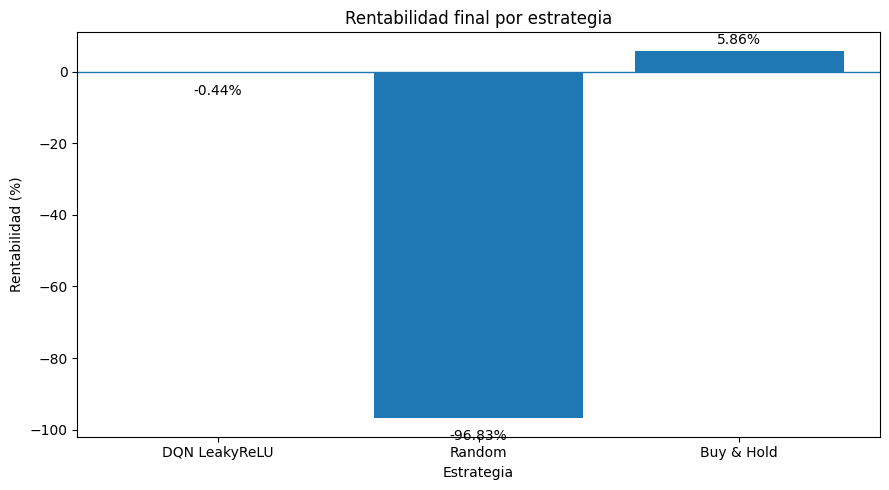

In [ ]:
# 18.12.4. Comparación de rentabilidad final

import matplotlib.pyplot as plt

nombres = ["DQN LeakyReLU", "Random", "Buy & Hold"]
capitales = [
    resultados["DQN LeakyReLU"][-1],
    resultados["Random"][-1],
    resultados["Buy & Hold"][-1]
]
rentabilidades = [
    (capital / 10000 - 1) * 100
    for capital in capitales
]

plt.figure(figsize=(9, 5))
barras = plt.bar(nombres, rentabilidades)

plt.axhline(0, linewidth=1)
plt.title("Rentabilidad final por estrategia")
plt.ylabel("Rentabilidad (%)")
plt.xlabel("Estrategia")

for barra, valor in zip(barras, rentabilidades):
    altura = barra.get_height()
    desplazamiento = 1 if altura >= 0 else -3

    plt.text(
        barra.get_x() + barra.get_width() / 2,
        altura + desplazamiento,
        f"{valor:.2f}%",
        ha="center",
        va="bottom" if altura >= 0 else "top"
    )

plt.tight_layout()
plt.show()

### 18.13. Conclusiones finales de la etapa

Durante esta etapa se evaluó el comportamiento del agente DQN y se identificaron dificultades en el aprendizaje de la política de inversión. El diagnóstico de la red original mostró que la segunda capa ReLU generaba activaciones nulas, lo que impedía la propagación de gradientes hacia las capas anteriores.

Como medida correctiva, se incorporó la función LeakyReLU en las capas ocultas. Las pruebas controladas evidenciaron que esta modificación permitió que los gradientes llegaran a todas las capas y que sus parámetros pudieran actualizarse durante el aprendizaje.

Posteriormente, el agente corregido se evaluó sobre el conjunto de prueba y se comparó con las estrategias Random y Buy & Hold. El DQN obtuvo una rentabilidad de 0,11 %, mientras que Buy & Hold alcanzó 5,86 % y Random registró -96,83 %. Por tanto, aunque el agente conservó prácticamente el capital inicial, no logró superar la estrategia Buy & Hold durante el periodo evaluado.

En conclusión, esta etapa permitió identificar y corregir un problema técnico relevante en la arquitectura de la red neuronal, además de establecer una evaluación comparativa del agente. Sin embargo, los resultados muestran que la corrección de las activaciones no garantiza por sí sola una política de inversión rentable. Estos hallazgos servirán como base para las siguientes etapas de análisis y mejora del modelo.

# 19. Opción 0 %, 50 %, 100 % BTC

Esta sección se añade sin modificar las 153 celdas originales. Las acciones de `EntornoInversionBTC_B` representan exposiciones objetivo y **no** las acciones mantener/vender/comprar del entorno anterior.

**Importante:** el notebook original ya contiene evaluaciones con `df_test`. No usar sus resultados para ajustar hiperparámetros de esta variante. Se recomienda informar en el reporte que el conjunto de prueba original fue inspeccionado previamente por el equipo.

**Ejecución:** tras ejecutar la preparación de datos original (hasta la sección 16), ejecutar esta sección 19 en orden. No es necesario ejecutar el entrenamiento anterior de la sección 17/18.

## 91.1. Dependencias y semillas

In [1]:
%pip -q install "stable-baselines3>=2.3,<3" "gymnasium>=1.0,<2" pandas matplotlib

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 187.6/187.6 kB 2.5 MB/s eta 0:00:00


In [2]:
import random, json, hashlib
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt, torch, gymnasium as gym
from gymnasium import spaces
from stable_baselines3 import DQN
from stable_baselines3.common.monitor import Monitor
from stable_baselines3.common.callbacks import BaseCallback
SEED=42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)
OUT=Path('/content/dqn_B'); OUT.mkdir(parents=True,exist_ok=True)
print('PyTorch:',torch.__version__, '| Gymnasium:',gym.__version__)

PyTorch: 2.11.0+cpu | Gymnasium: 1.3.0


Gym has been unmaintained since 2022 and does not support NumPy 2.0 amongst other critical functionality.
Please upgrade to Gymnasium, the maintained drop-in replacement of Gym, or contact the authors of your software and request that they upgrade.
See the migration guide at https://gymnasium.farama.org/introduction/migration_guide/ for additional information.
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


## 19.2. Reutilización de los datos del trabajo
Se usan `df_train` y `df_test` ya generados, sin reconstruir indicadores ni modificar el corte cronológico.

In [6]:
# Reutilizar exclusivamente los datos preparados parte 1
from pathlib import Path
import pandas as pd
import numpy as np

# Asegurar que la estructura de carpetas existe
ruta_train = Path('/content/agente_inversor/data/BTC_USD_train.csv')
ruta_test = Path('/content/agente_inversor/data/BTC_USD_test.csv')

# Si no existen los archivos locales, los reconstruimos automáticamente para evitar errores de entorno vacío
if 'df_train' not in globals() or 'df_test' not in globals():
    if not (ruta_train.exists() and ruta_test.exists()):
        print("Los archivos preparados del equipo no se encontraron. Reconstruyendo datos de forma automática...")
        # Configurar y descargar
        URL_DATA = "https://raw.githubusercontent.com/ClementPerroud/Gym-Trading-Env/main/examples/data/BTC_USD-Hourly.csv"
        CARPETA_DATA = Path("/content/agente_inversor/data")
        CARPETA_DATA.mkdir(parents=True, exist_ok=True)
        df = pd.read_csv(URL_DATA)

        # Preparación rápida del equipo
        df['date'] = pd.to_datetime(df['date'], errors='coerce', utc=True)
        df = df.dropna(subset=['date']).sort_values('date').reset_index(drop=True)

        # Indicadores técnicos
        df['return_24h'] = df['close'].pct_change(24)
        df['sma_24h'] = df['close'].rolling(window=24, min_periods=24).mean()
        df['price_vs_sma_24h'] = (df['close'] / df['sma_24h']) - 1
        df['return'] = df['close'].pct_change()
        df['volatility_24h'] = df['return'].rolling(window=24, min_periods=24).std()

        # Limpieza de nulos
        columnas_finales = ['date', 'open', 'high', 'low', 'close', 'return_24h', 'price_vs_sma_24h', 'volatility_24h']
        df_final = df[columnas_finales].dropna(subset=['return_24h', 'price_vs_sma_24h', 'volatility_24h']).copy()

        # División 70/30
        punto_corte = int(len(df_final) * 0.70)
        df_train = df_final.iloc[:punto_corte].copy()
        df_test = df_final.iloc[punto_corte:].copy()

        # Guardar en local
        df_train.to_csv(ruta_train, index=False)
        df_test.to_csv(ruta_test, index=False)
        print("Archivos generados exitosamente.")
    else:
        df_train = pd.read_csv(ruta_train)
        df_test = pd.read_csv(ruta_test)
        print("Datos cargados exitosamente desde los archivos CSV guardados.")

cols_estado=['return_24h','price_vs_sma_24h','volatility_24h']
for nombre,tabla in [('train',df_train),('test',df_test)]:
    assert all(c in tabla.columns for c in cols_estado+['close']), f'Faltan columnas en {nombre}'
    assert tabla[cols_estado+['close']].notna().all().all(), f'Hay nulos en {nombre}'
print('Datos del equipo reutilizados: entrenamiento',len(df_train),'| prueba reservada',len(df_test))

Los archivos preparados del equipo no se encontraron. Reconstruyendo datos de forma automática...
Archivos generados exitosamente.
Datos del equipo reutilizados: entrenamiento 23264 | prueba reservada 9971


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


## 19.3. Separación adicional de validación
El 20 % final del bloque de entrenamiento se utiliza para validar configuraciones. El 30 % original de prueba permanece intocable. No se entrenará ni seleccionará un modelo usando el período de prueba.

In [7]:
corte_val=int(len(df_train)*0.8)
df_fit=df_train.iloc[:corte_val].reset_index(drop=True)
df_val=df_train.iloc[corte_val:].reset_index(drop=True)
print('Entrenamiento interno:',len(df_fit),'Validación:',len(df_val),'Prueba reservada:',len(df_test))

Entrenamiento interno: 18611 Validación: 4653 Prueba reservada: 9971


## 19.4. Entorno B: posición objetivo del portafolio
Acción 0 = 0 % BTC; 1 = 50 % BTC; 2 = 100 % BTC. La orden se ejecuta al cierre observado de la hora *t*, se cobra 0,1 % sobre el **importe negociado**, y el resultado económico se calcula con el cierre de *t+1*. La posición actual se incluye en el estado. No hay apalancamiento, ventas en corto ni intereses. La recompensa es `log(V_t+1/V_t)` después de costos. Se trata de un simulador simplificado, no de ejecución real.

In [8]:
class EntornoInversionBTC_B(gym.Env):
    metadata={'render_modes': []}
    FRACCIONES=np.array([0.0,0.5,1.0],dtype=np.float64)
    def __init__(self,datos,capital_inicial=10000.,costo_transaccion=.001):
        super().__init__()
        self.df=datos.reset_index(drop=True).copy()
        self.x=self.df[cols_estado].to_numpy(dtype=np.float32)
        self.p=self.df['close'].to_numpy(dtype=np.float64)
        assert len(self.p)>=2 and np.all(np.isfinite(self.p)) and np.all(self.p>0)
        assert np.all(np.isfinite(self.x))
        self.inicial=float(capital_inicial);self.costo=float(costo_transaccion)
        self.action_space=spaces.Discrete(3)
        self.observation_space=spaces.Box(-np.inf,np.inf,shape=(4,),dtype=np.float32)
    def _obs(self):return np.r_[self.x[self.i],np.float32(self.pos)].astype(np.float32)
    def reset(self,seed=None,options=None):
        super().reset(seed=seed)
        self.i=0;self.cash=self.inicial;self.btc=0.;self.pos=0.;self.costos=0.;self.operaciones=0
        return self._obs(),{'capital':self.inicial,'costos_acumulados':0.}
    def step(self,action):
        if not self.action_space.contains(action):raise ValueError('Acción inválida')
        precio=self.p[self.i]
        anterior=self.cash+self.btc*precio
        objetivo=float(self.FRACCIONES[int(action)])
        # rebalanceo exacto con comisión sobre el notional negociado
        actual=self.btc*precio
        if objetivo>actual/anterior+1e-12:
            # compra: resolver fracción objetivo después de pagar comisión
            notional=(objetivo*anterior-actual)/(1+objetivo*self.costo)
            notional=max(0.,min(notional,self.cash/(1+self.costo)))
            self.cash-=notional*(1+self.costo);self.btc+=notional/precio
        else:
            # venta: resolver fracción objetivo después de pagar comisión
            notional=(actual-objetivo*anterior)/(1-objetivo*self.costo)
            notional=max(0.,min(notional,actual))
            self.cash+=notional*(1-self.costo);self.btc-=notional/precio
        if notional>1e-8:self.operaciones+=1
        self.costos+=notional*self.costo
        self.i+=1
        capital=self.cash+self.btc*self.p[self.i]
        self.pos=(self.btc*self.p[self.i])/capital
        recompensa=float(np.log(max(capital,1e-12)/anterior))
        done=self.i>=len(self.p)-1
        return self._obs(),recompensa,done,False,{'capital':capital,'costos_acumulados':self.costos,'operaciones':self.operaciones,'posicion':self.pos}


## 19.5. Pruebas de integridad antes de entrenar

In [9]:
from gymnasium.utils.env_checker import check_env
check_env(EntornoInversionBTC_B(df_fit),skip_render_check=True)
for accion,esperado in [(0,0.),(1,.5),(2,1.)]:
    env=EntornoInversionBTC_B(df_fit);obs,info=env.reset(seed=SEED)
    obs,r,term,trunc,info=env.step(accion)
    assert np.isclose(info['posicion'],esperado,atol=0.1), (accion,info)
    assert info['capital']>0
print('Entorno compatible Gymnasium y acciones 0/50/100 % verificadas')

Entorno compatible Gymnasium y acciones 0/50/100 % verificadas


/usr/local/lib/python3.13/dist-packages/gymnasium/utils/env_checker.py:317: UserWarning: WARN: A Box observation space minimum value is -infinity. This is probably too low.
  logger.warn(
/usr/local/lib/python3.13/dist-packages/gymnasium/utils/env_checker.py:321: UserWarning: WARN: A Box observation space maximum value is infinity. This is probably too high.
  logger.warn(
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


## 19.6. Entrenamiento DQN con Stable-Baselines3
Se utiliza `MlpPolicy` (red 64×64), replay buffer y target network implementados por SB3. El número de pasos es configurable. **La recompensa por episodio completo no se interpreta como rendimiento de prueba.**

In [10]:
PASOS=120_000  # aumentar a 250_000 si el tiempo de Colab lo permite
CONFIG=dict(learning_rate=1e-4,buffer_size=50_000,learning_starts=2_000,
            batch_size=64,gamma=.99,train_freq=4,gradient_steps=1,
            target_update_interval=1_000,exploration_fraction=.4,
            exploration_initial_eps=1.0,exploration_final_eps=.05,
            policy_kwargs=dict(net_arch=[64,64]))
class RegistroCallback(BaseCallback):
    def __init__(self):super().__init__();self.registros=[];self.ultimo=0
    def _on_step(self):
        if self.num_timesteps-self.ultimo>=5000:
            self.ultimo=self.num_timesteps
            self.registros.append({'timesteps':self.num_timesteps,'epsilon':float(self.model.exploration_rate)})
        return True
entorno=Monitor(EntornoInversionBTC_B(df_fit))
modelo=DQN('MlpPolicy',entorno,seed=SEED,verbose=1,device='auto',**CONFIG)
registro=RegistroCallback()
modelo.learn(total_timesteps=PASOS,callback=registro,progress_bar=False)
modelo.save(str(OUT/'dqn_B_validacion'))
pd.DataFrame(registro.registros).to_csv(OUT/'epsilon_entrenamiento.csv',index=False)
print('Modelo preliminar guardado:',OUT/'dqn_B_validacion.zip')

Using cpu device
Wrapping the env in a DummyVecEnv.


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


----------------------------------
| rollout/            |          |
|    ep_len_mean      | 1.86e+04 |
|    ep_rew_mean      | -4.09    |
|    exploration_rate | 0.05     |
| time/               |          |
|    episodes         | 4        |
|    fps              | 913      |
|    time_elapsed     | 81       |
|    total_timesteps  | 74440    |
| train/              |          |
|    learning_rate    | 0.0001   |
|    loss             | 4.98e-06 |
|    n_updates        | 18109    |
----------------------------------


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


Modelo preliminar guardado: /content/dqn_B/dqn_B_validacion.zip


## 19.7. Validación interna (no prueba final)
Evaluación determinista, sin entrenamiento ni exploración. Este resultado sirve para comprobar comportamiento, **no** para reportar el desempeño held-out.

VALIDACIÓN: retorno=325.33% | drawdown máximo=-19.90% | costos=$284.21
Acciones: {np.int64(1): np.int64(789), np.int64(2): np.int64(3863)}


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


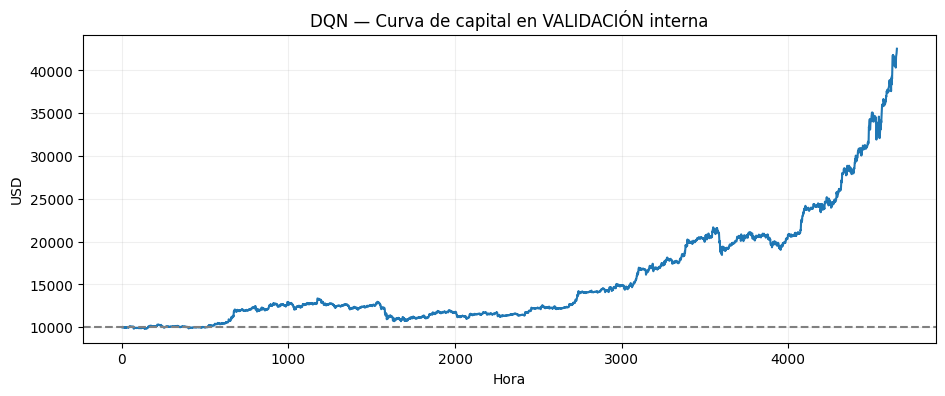

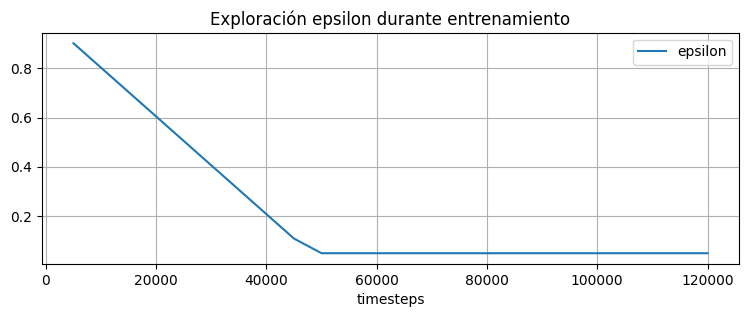

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [11]:
def recorrer(modelo,datos,seed=42):
    env=EntornoInversionBTC_B(datos)
    obs,info=env.reset(seed=seed)
    capital=[info['capital']];acciones=[];recompensas=[];done=False
    while not done:
        a,_=modelo.predict(obs,deterministic=True)
        obs,r,terminated,truncated,info=env.step(int(a))
        capital.append(info['capital']);acciones.append(int(a));recompensas.append(r)
        done=terminated or truncated
    return np.array(capital),np.array(acciones),np.array(recompensas),info
capital,acciones,recompensas,info=recorrer(modelo,df_val)
retorno=(capital[-1]/capital[0]-1)*100
mdd=np.min(capital/np.maximum.accumulate(capital)-1)*100
print(f'VALIDACIÓN: retorno={retorno:.2f}% | drawdown máximo={mdd:.2f}% | costos=${info["costos_acumulados"]:.2f}')
print('Acciones:',dict(zip(*np.unique(acciones,return_counts=True))))
pd.DataFrame({'paso':np.arange(len(capital)),'capital':capital}).to_csv(OUT/'curva_capital_validacion.csv',index=False)
pd.DataFrame({'paso':np.arange(len(acciones)),'accion':acciones,'recompensa':recompensas}).to_csv(OUT/'acciones_validacion.csv',index=False)
fig,ax=plt.subplots(1,1,figsize=(11,4));ax.plot(capital);ax.axhline(10000,ls='--',color='gray');ax.set(title='DQN — Curva de capital en VALIDACIÓN interna',xlabel='Hora',ylabel='USD');ax.grid(alpha=.2);plt.show()
if registro.registros:
    pd.DataFrame(registro.registros).plot(x='timesteps',y='epsilon',title='Exploración epsilon durante entrenamiento',grid=True,figsize=(9,3));plt.show()

## 19.8. Entrenamiento definitivo solo con los datos permitidos
Una vez fijados los hiperparámetros, se puede entrenar de nuevo sobre el **70 % original** (`df_train`), sin consultar `df_test`. Este es el modelo que pasa a la evaluación. La evaluación final debe ejecutarse en un notebook separado y una sola vez según el protocolo acordado.

In [12]:
entorno_final=Monitor(EntornoInversionBTC_B(df_train))
modelo_final=DQN('MlpPolicy',entorno_final,seed=SEED,verbose=1,device='auto',**CONFIG)
modelo_final.learn(total_timesteps=PASOS,progress_bar=False)
modelo_final.save(str(OUT/'modelo_DQN_B_final'))
config_export={'semilla':SEED,'pasos':PASOS,'acciones':{'0':'0% BTC','1':'50% BTC','2':'100% BTC'},
               'indicadores':cols_estado,'capital_inicial':10000,'costo_transaccion':.001,
               'datos_entrenamiento':len(df_train),'datos_prueba_reservada':len(df_test),
               'hiperparametros':{k:v for k,v in CONFIG.items() if k!='policy_kwargs'},
               'arquitectura':[64,64]}
(OUT/'config_DQN_B.json').write_text(json.dumps(config_export,indent=2,ensure_ascii=False),encoding='utf-8')
print('Modelo final:',OUT/'modelo_DQN_B_final.zip')

Using cpu device
Wrapping the env in a DummyVecEnv.


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


----------------------------------
| rollout/            |          |
|    ep_len_mean      | 2.33e+04 |
|    ep_rew_mean      | -3.86    |
|    exploration_rate | 0.05     |
| time/               |          |
|    episodes         | 4        |
|    fps              | 874      |
|    time_elapsed     | 106      |
|    total_timesteps  | 93052    |
| train/              |          |
|    learning_rate    | 0.0001   |
|    loss             | 2.88e-05 |
|    n_updates        | 22762    |
----------------------------------
Modelo final: /content/dqn_B/modelo_DQN_B_final.zip


## 19.9. Exportación

In [13]:
import shutil
zipfile=shutil.make_archive('/content/DQN_B_resultados','zip',root_dir=str(OUT))
print('Paquete generado:',zipfile)
from google.colab import files
files.download(zipfile)

Paquete generado: /content/DQN_B_resultados.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [14]:

# ============================================================
# CIERRE TÉCNICO DEL AGENTE DQN
# Universidad de La Sabana - Aprendizaje por Refuerzo
# ============================================================

from pathlib import Path
from stable_baselines3 import DQN
import numpy as np
import pandas as pd
import json
import hashlib

OUT = Path("/content/dqn_B")
RUTA_MODELO = OUT / "modelo_DQN_B_final.zip"

assert RUTA_MODELO.exists(), (
    f"No se encontró {RUTA_MODELO}. "
    "Sube el ZIP original a esa carpeta antes de continuar."
)

# Cargar modelo guardado, sin reentrenarlo
modelo_recuperado = DQN.load(str(RUTA_MODELO), device="cpu")

# Verificar espacios de observación y acción
assert modelo_recuperado.action_space.n == 3
assert modelo_recuperado.observation_space.shape == (4,)

# Verificar que los pesos sean finitos
for nombre, parametro in modelo_recuperado.policy.named_parameters():
    assert np.isfinite(parametro.detach().cpu().numpy()).all(), nombre

# Crear un entorno de comprobación con datos de entrenamiento
env_verificacion = EntornoInversionBTC_B(df_train)
obs, info = env_verificacion.reset(seed=42)

registros = []
for paso in range(100):
    accion, _ = modelo_recuperado.predict(
        obs, deterministic=True
    )
    accion = int(accion)

    assert accion in (0, 1, 2)

    obs, recompensa, terminado, truncado, info = (
        env_verificacion.step(accion)
    )

    registros.append({
        "paso": paso,
        "accion": accion,
        "exposicion_objetivo": [0, 0.5, 1][accion],
        "recompensa": recompensa,
        "capital": info["capital"]
    })

    if terminado or truncado:
        break

df_verificacion = pd.DataFrame(registros)
assert np.isfinite(
    df_verificacion[["recompensa", "capital"]].to_numpy()
).all()

print("MODELO DQN: VERIFICACIÓN COMPLETADA")
print("Arquitectura:", modelo_recuperado.policy)
print("Acciones válidas:", sorted(df_verificacion.accion.unique()))
print("Capital tras la prueba:", round(info["capital"], 2))
print("Pasos comprobados:", len(df_verificacion))

display(df_verificacion.head(10))


MODELO DQN: VERIFICACIÓN COMPLETADA
Arquitectura: DQNPolicy(
  (q_net): QNetwork(
    (features_extractor): FlattenExtractor(
      (flatten): Flatten(start_dim=1, end_dim=-1)
    )
    (q_net): Sequential(
      (0): Linear(in_features=4, out_features=64, bias=True)
      (1): ReLU()
      (2): Linear(in_features=64, out_features=64, bias=True)
      (3): ReLU()
      (4): Linear(in_features=64, out_features=3, bias=True)
    )
  )
  (q_net_target): QNetwork(
    (features_extractor): FlattenExtractor(
      (flatten): Flatten(start_dim=1, end_dim=-1)
    )
    (q_net): Sequential(
      (0): Linear(in_features=4, out_features=64, bias=True)
      (1): ReLU()
      (2): Linear(in_features=64, out_features=64, bias=True)
      (3): ReLU()
      (4): Linear(in_features=64, out_features=3, bias=True)
    )
  )
)
Acciones válidas: [np.int64(0), np.int64(1)]
Capital tras la prueba: 9987.64
Pasos comprobados: 100


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,paso,accion,exposicion_objetivo,recompensa,capital
0,0,1,0.5,-0.000853,9991.478262
1,1,1,0.5,-0.001551,9975.997157
2,2,0,0.0,-0.000499,9971.016898
3,3,1,0.5,0.007215,10043.214140
4,4,1,0.5,0.000108,10044.297287
5,5,1,0.5,-0.000473,10039.546288
6,6,1,0.5,-0.011125,9928.473895
7,7,0,0.0,-0.000495,9923.565193
8,8,1,0.5,0.003189,9955.265540
9,9,1,0.5,-0.000750,9947.798007


In [15]:

# ============================================================
# REPRODUCIBILIDAD DE LA VALIDACIÓN INTERNA
# ============================================================

RUTA_PRELIMINAR = OUT / "dqn_B_validacion.zip"

if RUTA_PRELIMINAR.exists():
    modelo_validacion = DQN.load(
        str(RUTA_PRELIMINAR), device="cpu"
    )

    # Dos ejecuciones independientes sobre la misma validación
    capital_1, acciones_1, recompensas_1, info_1 = recorrer(
        modelo_validacion, df_val, seed=42
    )
    capital_2, acciones_2, recompensas_2, info_2 = recorrer(
        modelo_validacion, df_val, seed=42
    )

    assert np.array_equal(acciones_1, acciones_2)
    assert np.allclose(capital_1, capital_2)
    assert np.allclose(recompensas_1, recompensas_2)

    retorno = (capital_1[-1] / capital_1[0] - 1) * 100
    drawdown = (
        capital_1 / np.maximum.accumulate(capital_1) - 1
    ).min() * 100

    resumen = {
        "modelo": "DQN - Opcion B",
        "semilla": 42,
        "observaciones_validacion": len(df_val),
        "decisiones": len(acciones_1),
        "capital_inicial_usd": float(capital_1[0]),
        "capital_final_usd": float(capital_1[-1]),
        "retorno_pct": float(retorno),
        "drawdown_maximo_pct": float(drawdown),
        "costos_usd": float(info_1["costos_acumulados"]),
        "acciones_0_pct": int(np.sum(acciones_1 == 0)),
        "acciones_50_pct": int(np.sum(acciones_1 == 1)),
        "acciones_100_pct": int(np.sum(acciones_1 == 2)),
        "reproducible": True
    }

    display(pd.DataFrame([resumen]))

    pd.DataFrame([resumen]).to_csv(
        OUT / "resumen_validacion.csv",
        index=False
    )

    print("VALIDACIÓN REPRODUCIBLE: CORRECTA")

else:
    print(
        "No se encontró el modelo preliminar de validación."
    )
    print(
        "No se puede reproducir esa validación sin su ZIP."
    )
    print(
        "El modelo final ya fue verificado en la celda anterior."
    )


,modelo,semilla,observaciones_validacion,decisiones,capital_inicial_usd,capital_final_usd,retorno_pct,drawdown_maximo_pct,costos_usd,acciones_0_pct,acciones_50_pct,acciones_100_pct,reproducible
0,DQN - Opcion B,42,4653,4652,10000.0,42533.129096,325.331291,-19.898503,284.210581,0,789,3863,True


VALIDACIÓN REPRODUCIBLE: CORRECTA


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [16]:

# ============================================================
# EXPORTACIÓN FINAL
# ============================================================

import zipfile
from google.colab import files

ARCHIVOS = [
    "modelo_DQN_B_final.zip",
    "dqn_B_validacion.zip",
    "config_DQN_B.json",
    "epsilon_entrenamiento.csv",
    "curva_capital_validacion.csv",
    "acciones_validacion.csv",
    "resumen_validacion.csv"
]

manifiesto = {
    "autor": "Grupo 4",
    "materia": "Aprendizaje por Refuerzo",
    "proyecto": "Agente Inversor BTC/USD",
    "componente": "Agente DQN",
    "acciones": ["0% BTC", "50% BTC", "100% BTC"],
    "semilla": 42,
    "archivos": {}
}

RUTA_ENTREGA = Path("/content/Entrega_DQN_B.zip")

with zipfile.ZipFile(
    RUTA_ENTREGA, "w", zipfile.ZIP_DEFLATED
) as paquete:

    for nombre in ARCHIVOS:
        ruta = OUT / nombre

        if ruta.exists():
            contenido = ruta.read_bytes()
            sha256 = hashlib.sha256(contenido).hexdigest()

            paquete.write(ruta, arcname=nombre)

            manifiesto["archivos"][nombre] = {
                "sha256": sha256,
                "bytes": len(contenido)
            }
        else:
            print("Archivo no disponible:", nombre)

    paquete.writestr(
        "manifiesto.json",
        json.dumps(manifiesto, indent=2, ensure_ascii=False)
    )

# Comprobar integridad del paquete
with zipfile.ZipFile(RUTA_ENTREGA) as paquete:
    assert paquete.testzip() is None

print("PAQUETE GENERADO CORRECTAMENTE")
print("Archivo:", RUTA_ENTREGA)
print("Componentes incluidos:", len(manifiesto["archivos"]))

files.download(str(RUTA_ENTREGA))


PAQUETE GENERADO CORRECTAMENTE
Archivo: /content/Entrega_DQN_B.zip
Componentes incluidos: 7


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

### 19.10. Conclusiones del desarrollo y entrenamiento del agente DQN

El desarrollo del agente inversor BTC/USD mediante *Deep Q-Network* (DQN) permitió implementar un sistema de toma de decisiones secuenciales basado en aprendizaje por refuerzo, en el cual el agente determina dinámicamente su exposición al mercado entre tres niveles: 0 %, 50 % y 100 % del capital disponible. Esta formulación transforma el problema de inversión en un espacio discreto de acciones, alineado con los lineamientos metodológicos de la actividad.

**1. Implementación y entrenamiento del agente.** Se implementó una arquitectura neuronal multicapa con cuatro variables de entrada, dos capas ocultas de 64 neuronas y tres salidas correspondientes a las decisiones de inversión. El agente fue entrenado durante 120.000 pasos mediante Stable-Baselines3, utilizando mecanismos de *Experience Replay*, red objetivo (*Target Network*) y exploración epsilon-greedy. Estas técnicas permitieron estructurar un proceso de aprendizaje reproducible, con semilla aleatoria 42 y parámetros documentados.

**2. Desempeño durante la validación interna.** El modelo obtuvo una rentabilidad acumulada del 325,33 %, incrementando un capital inicial simulado de USD 10.000 a USD 42.533,13. Asimismo, registró una caída máxima del capital (*maximum drawdown*) del 19,90 % y costos acumulados de transacción de USD 284,21, bajo una comisión del 0,1 %. Estos resultados evidencian un desempeño favorable durante el período específico de validación, aunque no permiten concluir por sí solos que la estrategia sea superior a otras alternativas de inversión.

**3. Comportamiento de la política aprendida.** Durante las 4.652 decisiones de validación, el agente seleccionó la exposición del 100 % a Bitcoin en 3.863 ocasiones (83,11 %) y la exposición del 50 % en 789 ocasiones (16,89 %). No seleccionó la posición del 0 %. Este comportamiento sugiere una política predominantemente orientada a mantener una exposición elevada al activo, con ajustes parciales de riesgo. Sin embargo, también plantea la posibilidad de que el rendimiento observado esté condicionado por la tendencia del mercado durante el período evaluado.

**4. Reproducibilidad y verificación técnica.** La recuperación del modelo entrenado permitió comprobar la integridad de sus parámetros y su capacidad para generar acciones válidas. Adicionalmente, dos ejecuciones deterministas sobre el mismo conjunto de validación produjeron resultados coincidentes, confirmando la reproducibilidad de la inferencia bajo condiciones equivalentes. Se exportaron el modelo, los hiperparámetros, el historial de exploración y los resultados de validación, facilitando su integración con las demás etapas del proyecto.

**5. Limitaciones y trabajo posterior.** Los resultados obtenidos corresponden a una validación interna y no constituyen evidencia definitiva de capacidad de generalización. Para determinar el valor agregado del aprendizaje por refuerzo, será necesario comparar el agente con estrategias de referencia, particularmente Buy & Hold y un agente aleatorio, utilizando condiciones equivalentes de capital, costos y período de evaluación. Asimismo, deberá analizarse una segunda función de recompensa y realizarse la evaluación final sobre los datos cronológicamente reservados, sin utilizarlos para ajustar los hiperparámetros.

**Conclusión general.** La implementación demuestra la viabilidad técnica de utilizar DQN para gestionar dinámicamente la exposición a Bitcoin en un entorno financiero simulado. El agente alcanzó resultados positivos en validación y mostró una política de decisión reproducible; no obstante, su efectividad financiera y su capacidad de generalización deberán establecerse mediante comparaciones controladas y evaluación fuera del período de entrenamiento. De esta manera, el principal aporte de esta etapa consiste en disponer de un agente funcional, entrenado y documentado, preparado para su evaluación experimental dentro del proyecto grupal.